# Agricultural Query Clustering — Phase 2 (Version 2: domain transformers, topic input, overlap analysis)

**Input to every model = farmer Query + expert Response**, joined as `question: <query> answer: <response>`. Version 2 also tests the same input **plus a topic** (`question: … topic: … answer: …`).

## What this notebook does

1. Cleans the data and builds the *Query + Response* text.
2. Builds **12 vector spaces**: 3 classical (TF-IDF+SVD, Doc2Vec, GloVe-avg), 5 general-purpose transformer encoders (MiniLM, **SBERT/MPNet**, E5, BGE, GTE) and **4 domain encoders**: Agri-Sentence-Transformer, AgriBERT, SciBERT, SPECTER.
3. **Does not fix K.** Every (vector space, algorithm) pair is swept over K = 2 … `K_MAX` (WCSS for the **elbow method**, silhouette, Davies-Bouldin, Calinski-Harabasz) and K is chosen by a written rule.
4. Compares **classical clustering** with **transformer-based clustering** (encoder → UMAP → KMeans / GMM / Ward / HDBSCAN) across **72 configurations**, ranked with space-independent metrics (Stage 9).
5. **NEW — Stage 10:** domain-trained vs general-purpose transformers, with a SciBERT → AgriBERT → Agri-Sentence-Transformer ablation chain.
6. **NEW — Stages 14–15:** extracts a topic per record (statistical NMF and an agriculture-encoder key-phrase method) and tests **Query + Response** against **Query + Response + Topic**, with shuffled-topic controls and a pre-declared decision rule.
7. **NEW — Stages 17–18:** measures how **differentiated** the final clusters are and **where, how much and why they overlap** (hard vs soft overlap, evidence-based reason tags, example records, merge test).
8. Stability, text-variant, agreement and intrusion experiments on the winner.

## Stage map (output folders)

| Folder | Content |
|---|---|
| `00_setup` … `05_embeddings` | Config, raw audit, sampling, cleaning, text variants, vectors, encoder status |
| `06_E1_k_selection_kmeans` | K sweep + elbow for KMeans in all 12 spaces |
| `07_E2_umap_projection` | Choice of UMAP dimensionality |
| `08_E3_full_k_sweeps` | K sweeps for all 72 configurations |
| `09_E4_classical_vs_transformer` | Leaderboard, classical-vs-transformer comparison |
| `10_E10_domain_vs_general` | **NEW** domain-trained vs general transformers |
| `11_E5_text_variants` | Question-only / answer-only sensitivity |
| `12_E6_stability`, `13_E7_encoder_agreement` | Stability and agreement |
| `14_E11_topic_extraction` | **NEW** NMF topics and agri key-phrases |
| `15_E12_input_with_topic` | **NEW** Query+Response vs +Topic, controls, decision |
| `16_E8_final_clusters` | Final labels, keywords, representatives, names |
| `17_E13_differentiation` | **NEW** how distinct the clusters are |
| `18_E14_overlap_reasons` | **NEW** where and why clusters overlap |
| `19_E9_intrusion`, `20_final_summary` | Intrusion test; master table, manifest, zip |

> **Run time:** 12 spaces × 7 pipelines × K sweeps plus the input experiment is long (roughly 2–3 hours on a Colab T4). Lower `MAX_ROWS` or `K_MAX` in the config cell for a faster trial run.

## Stage 0 — Setup
### 0.1 Install libraries
One install cell. `pandas==2.2.3` is pinned because that is the version your earlier successful run used. If Colab asks to restart the runtime, restart and run again from the top.

In [1]:
%pip install -q pandas==2.2.3 gensim umap-learn hdbscan sentence-transformers transformers scipy scikit-learn matplotlib

In [2]:
# Version check: confirms every library imports before we start the long run.
from importlib.metadata import version
import numpy as np, pandas as pd, sklearn, scipy, sentence_transformers, umap, hdbscan, gensim
print("NumPy:", np.__version__, "| Pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__, "| SciPy:", scipy.__version__)
print("Sentence-Transformers:", sentence_transformers.__version__, "| UMAP:", umap.__version__, "| Gensim:", gensim.__version__)
try:
    print("HDBSCAN:", version("hdbscan"))
except Exception:
    print("HDBSCAN: installed (version metadata unavailable)")

NumPy: 2.4.6 | Pandas: 2.2.3 | scikit-learn: 1.6.1 | SciPy: 1.16.3
Sentence-Transformers: 5.7.0 | UMAP: 0.5.12 | Gensim: 4.4.0
HDBSCAN: 0.8.44


### 0.2 Imports

In [3]:
import ast, hashlib, json, re, shutil, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scipy.cluster.hierarchy import linkage, fcluster          # Ward linkage computed once, cut at every K
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, TfidfTransformer, ENGLISH_STOP_WORDS
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (adjusted_mutual_info_score, adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score, pairwise_distances_argmin)
from sklearn.preprocessing import normalize
from sklearn.manifold import trustworthiness
from sklearn.decomposition import NMF
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import silhouette_samples, accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.dpi"] = 110
print("Imports finished.")

Imports finished.


### 0.3 Configuration
Change values **only here**. Every setting is justified next to it.

| Setting | Why this value |
|---|---|
| `K_MIN=2`, `K_MAX=25` | The sweep must be wide enough for the elbow to appear. `K_MAX` is automatically capped at `n_rows // 20`. |
| `K_SELECT_MIN=5` | **Selection constraint, not a sweep limit.** Silhouette / Calinski-Harabasz favour very small K; your first run showed ≥ 8 themes. K = 2…4 are still tested; the unconstrained optimum is saved beside the constrained one. Stage 6 also reports how often the constraint is *binding*. |
| `UMAP_DIMS_TO_TEST` | UMAP dimensionality is tested, not assumed (Stage 7). |
| `HDBSCAN_MIN_SIZES` | HDBSCAN chooses its own number of clusters; `min_cluster_size` is swept instead of K. |
| `DEGENERATE_SHARE=0.5` | A clustering with one cluster > 50 % of rows cannot separate topics; reported but not ranked. |
| `HF_ENCODER_MODELS` | 5 general encoders from version 1 + the 4 domain encoders (`agri_st`, `agribert`, `scibert`, `specter`). `mpnet` is the SBERT model you listed. |
| `ENCODER_GROUP` | `general`, `agriculture` (trained on agricultural text) and `science` (trained on scientific papers). Only `agri_st` and `agribert` are agriculture-trained; SciBERT and SPECTER are scientific-domain. |
| `ENCODER_POOLING` | SciBERT / AgriBERT are masked-language models, not sentence encoders, so token vectors must be pooled: **mean** pooling (SBERT paper: better than CLS for non-fine-tuned BERT). SPECTER uses **CLS** pooling as in its paper. Sentence-transformers models keep their own saved pooling. |
| `ENCODER_MAX_SEQ=512` | The new BERT-family models support 512 tokens; setting it explicitly prevents silent truncation differences between models. |
| `TOPIC_K_RANGE` | NMF topic counts 5…20: below 5 topics are too coarse, above 20 they are finer than the cluster counts being studied. The best count is chosen by NPMI coherence, not assumed. |
| `KEYPHRASES_PER_DOC=3`, `TOPIC_WORDS_PER_NMF_TOPIC=4` | A short topic string keeps the added text small relative to the answer (a long topic would dominate the embedding). |
| `N_INPUT_SEEDS=3` | Three seeds (new UMAP + new silhouette subset) give a noise estimate used in the adoption rule. |
| `OVERLAP_TOP_TERMS=25`, `TOP_PAIRS=6` | Words per cluster used to compare vocabularies; number of overlapping pairs shown in detail. |

In [4]:
RANDOM_SEED = 42
MAX_ROWS = 5000            # None = use entire dataset (all 177,169 rows, no sampling).
K_MIN, K_MAX = 2, 25       # K sweep range (K_MAX is capped after sampling, see Stage 2)
K_SELECT_MIN = 5           # smallest K allowed to be *chosen* (all K in the range are still tested)
UMAP_DIMS_TO_TEST = [5, 10, 20]
HDBSCAN_MIN_SIZES = [10, 15, 20, 30, 50]
DEGENERATE_SHARE = 0.5
N_STABILITY_SEEDS = 5
N_RESAMPLES = 3            # 80% subsamples used in stability checks
INTRUSION_PER_CLUSTER = 5

HF_ENCODER_MODELS = {
    # general-purpose sentence encoders (version 1)
    "minilm":   "sentence-transformers/all-MiniLM-L6-v2",
    "mpnet":    "sentence-transformers/all-mpnet-base-v2",   # = the "SBERT" model requested
    "e5":       "intfloat/e5-base-v2",                       # needs "query: " prefix (added automatically)
    "bge":      "BAAI/bge-base-en-v1.5",
    "gte":      "thenlper/gte-base",
    # domain encoders requested in version 2
    "agri_st":  "recobo/agri-sentence-transformer",          # 512-d sentence model built on the agriculture BERT below
    "agribert": "recobo/agriculture-bert-uncased",           # BERT further pre-trained from SciBERT on 6.5M agricultural paragraphs
    "scibert":  "allenai/scibert_scivocab_uncased",          # scientific-paper BERT
    "specter":  "allenai/specter",                           # scientific-document embeddings (citation-trained)
}
ENCODER_GROUP = {"minilm": "general", "mpnet": "general", "e5": "general", "bge": "general", "gte": "general",
                 "agri_st": "agriculture", "agribert": "agriculture", "scibert": "science", "specter": "science"}
DOMAIN_COMPARISON_SET = ["agri_st", "scibert", "mpnet", "agribert", "specter"]   # the five models requested
ENCODER_POOLING = {"agribert": "mean", "scibert": "mean", "specter": "cls"}        # models that are not ready-made sentence encoders
ENCODER_MAX_SEQ = {"agri_st": 512, "agribert": 512, "scibert": 512, "specter": 512}
ENCODER_INFO = {}                                                                 # filled when a model is loaded
CLASSICAL_SPACES = ["tfidf_svd", "doc2vec", "glove_avg"]

TOPIC_K_RANGE = list(range(5, 21))
TOPIC_WORDS_PER_NMF_TOPIC = 4
KEYPHRASES_PER_DOC = 3
TOPIC_ENCODER_PREFERENCE = ["agri_st", "agribert", "scibert"]   # first one that loaded ranks the key-phrases
N_INPUT_SEEDS = 3
OVERLAP_TOP_TERMS = 25
TOP_PAIRS = 6

RUN_DOC2VEC = True
RUN_GLOVE = True
RUN_LLM_LABELS = True
LLM_LABEL_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"

LOCAL_CSV_PATH = None      # only used outside Colab
OUTPUT_DIR = Path("experiment_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

STAGES = {
    "setup": "00_setup", "raw": "01_raw_data", "sampling": "02_sampling", "cleaning": "03_cleaning",
    "text": "04_text_representations", "emb": "05_embeddings",
    "E1": "06_E1_k_selection_kmeans", "E2": "07_E2_umap_projection", "E3": "08_E3_full_k_sweeps",
    "E4": "09_E4_classical_vs_transformer", "E10": "10_E10_domain_vs_general", "E5": "11_E5_text_variants",
    "E6": "12_E6_stability", "E7": "13_E7_encoder_agreement", "E11": "14_E11_topic_extraction",
    "E12": "15_E12_input_with_topic", "E8": "16_E8_final_clusters", "E13": "17_E13_differentiation",
    "E14": "18_E14_overlap_reasons", "E9": "19_E9_intrusion", "final": "20_final_summary",
}
print("Output root:", OUTPUT_DIR.resolve())

Output root: /content/experiment_outputs


### 0.4 Storage helpers
Every table / array / figure / JSON is saved to its stage folder and logged in `MANIFEST`.

In [5]:
MANIFEST = []

def stage_folder(stage_key):
    folder = OUTPUT_DIR / STAGES[stage_key]
    folder.mkdir(parents=True, exist_ok=True)
    return folder

def _register(stage_key, path, kind, note):
    path = Path(path)
    MANIFEST.append({"stage": STAGES[stage_key], "file": path.name, "kind": kind,
                     "size_kb": round(path.stat().st_size / 1024, 1), "note": note, "path": str(path)})
    print(f"  [saved {kind:5s}] {path}  ({MANIFEST[-1]['size_kb']} KB)")

def save_df(df_, stage_key, name, note="", index=False):
    path = stage_folder(stage_key) / f"{name}.csv"
    df_.to_csv(path, index=index)
    _register(stage_key, path, "csv", note)
    return path

def save_npy(array, stage_key, name, note=""):
    path = stage_folder(stage_key) / f"{name}.npy"
    np.save(path, array)
    _register(stage_key, path, "npy", note)
    return path

def save_json(obj, stage_key, name, note=""):
    path = stage_folder(stage_key) / f"{name}.json"
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)
    _register(stage_key, path, "json", note)
    return path

def save_fig(fig, stage_key, name, note=""):
    path = stage_folder(stage_key) / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    _register(stage_key, path, "png", note)
    plt.show()
    plt.close(fig)

def save_manifest():
    manifest_df = pd.DataFrame(MANIFEST)
    manifest_df.to_csv(OUTPUT_DIR / "00_manifest.csv", index=False)
    return manifest_df

print("Storage helpers ready.")

Storage helpers ready.


### 0.5 Environment check

In [6]:
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cpu":
    print("No GPU found. In Colab: Runtime > Change runtime type > T4 GPU (encoding is much faster).")

Device: cuda


## Stage 1 — Load the raw dataset
### 1.1 Upload the CSV
In Colab a file picker opens. Outside Colab set `LOCAL_CSV_PATH` in the config cell.

In [7]:
try:
    from google.colab import files
    uploaded = files.upload()
    csv_files = [n for n in uploaded.keys() if n.lower().endswith(".csv")]
    if not csv_files:
        raise FileNotFoundError("Please upload the dataset CSV file.")
    DATA_PATH = csv_files[0]
except ImportError:
    if LOCAL_CSV_PATH is not None and Path(LOCAL_CSV_PATH).exists():
        DATA_PATH = LOCAL_CSV_PATH
    else:
        # Automatically search for known local agricultural CSVs in the workspace
        candidates = ["Agricultural_Dataset.csv"]
        found = [c for c in candidates if Path(c).exists()]
        if found:
            DATA_PATH = found[0]
            print(f"Found local dataset automatically: {DATA_PATH}")
        else:
            all_csvs = list(Path(".").glob("*.csv"))
            if all_csvs:
                DATA_PATH = str(all_csvs[0])
                print(f"Using first CSV found in directory: {DATA_PATH}")
            else:
                raise FileNotFoundError("Not in Colab: set LOCAL_CSV_PATH in the config cell or place a CSV in the working directory.")
print("Using dataset:", DATA_PATH)


Saving Agricultural_Dataset.csv to Agricultural_Dataset.csv
Using dataset: Agricultural_Dataset.csv


### 1.2 Read the CSV and preview it

In [8]:
df_full = pd.read_csv(DATA_PATH)
print("Original CSV shape:", df_full.shape)

# Map column names to the expected 6-column pipeline schema
# Handles variations: 'questions' vs 'question', 'answer' vs 'answers', etc.
col_map = {}
for c in df_full.columns:
    c_lower = c.strip().lower()
    if c_lower in ["questions", "question", "query", "querytext", "farmer_query"]:
        col_map[c] = "representative_question"
    elif c_lower in ["answer", "answers", "kccans", "response", "expert_response"]:
        col_map[c] = "answer"

if col_map:
    print("Standardizing dataset columns:", col_map)
    df_full = df_full.rename(columns=col_map)

if "query_text" not in df_full.columns and "representative_question" in df_full.columns:
    df_full["query_text"] = df_full["representative_question"]

if "query_id" not in df_full.columns:
    df_full["query_id"] = [f"Q_{i:06d}" for i in range(len(df_full))]

if "embedding_answers" not in df_full.columns and "answer" in df_full.columns:
    df_full["embedding_answers"] = df_full["answer"].apply(lambda x: str([str(x)]) if pd.notna(x) else "[]")

if "record_count" not in df_full.columns:
    df_full["record_count"] = 1

if "unique_answer_count" not in df_full.columns:
    df_full["unique_answer_count"] = 1

print("Shape after mapping (rows, columns):", df_full.shape)

required_columns = {"query_id", "query_text", "representative_question", "embedding_answers",
                    "record_count", "unique_answer_count"}
missing = required_columns - set(df_full.columns)
if missing:
    raise ValueError(f"CSV is missing required columns: {sorted(missing)}")

dtypes_df = df_full.dtypes.astype(str).rename("dtype").reset_index().rename(columns={"index": "column"})
display(dtypes_df)
display(df_full.head())
save_df(df_full.head(100), "raw", "raw_head", "First 100 raw rows")
save_df(dtypes_df, "raw", "raw_dtypes", "Column data types")


Original CSV shape: (177169, 10)
Standardizing dataset columns: {'questions': 'representative_question', 'answer': 'answer'}
Shape after mapping (rows, columns): (177169, 15)


,column,dtype
0,representative_question,object
1,answer,object
2,questions_lemmatized,object
3,questions_pos_tagged,object
4,question_entities,object
5,answer_entities,object
6,all_ner_entities,object
7,unigrams,object
8,bigrams,object
9,trigrams,object


,representative_question,answer,questions_lemmatized,questions_pos_tagged,question_entities,answer_entities,all_ner_entities,unigrams,bigrams,trigrams,query_text,query_id,embedding_answers,record_count,unique_answer_count
0,asking about the control measure for aphid inf...,suggested him to spray rogor 2ml/lit.at evenin...,ask about the control measure for aphid infest...,ask (VERB) about (ADP) the (DET) control measu...,"[{""entity"": ""aphid"", ""label"": ""PEST"", ""start"":...",[],"{""question_entities"": [{""entity"": ""aphid"", ""la...","[""ask"", ""about"", ""the"", ""control"", ""measure"", ...","[""ask about"", ""about the"", ""the control"", ""con...","[""ask about the"", ""about the control"", ""the co...",asking about the control measure for aphid inf...,Q_000000,['suggested him to spray rogor 2ml/lit.at even...,1,1
1,asking about the control measure of flower dro...,suggested him to apply fertilizer in recommend...,ask about the control measure of flower drop p...,ask (VERB) about (ADP) the (DET) control measu...,"[{""entity"": ""flower drop"", ""label"": ""PLANT_SYM...","[{""entity"": ""urea"", ""label"": ""FERTILIZER"", ""st...","{""question_entities"": [{""entity"": ""flower drop...","[""ask"", ""about"", ""the"", ""control"", ""measure"", ...","[""ask about"", ""about the"", ""the control"", ""con...","[""ask about the"", ""about the control"", ""the co...",asking about the control measure of flower dro...,Q_000001,['suggested him to apply fertilizer in recomme...,1,1
2,asking about how to avail kisan credit card lo...,suggested to consult with officer-marketing an...,ask about how to avail kisan credit card loan ...,ask (VERB) about (ADP) how (ADV) to (PART) ava...,"[{""entity"": ""kisan credit card"", ""label"": ""GOV...","[{""entity"": ""sbi"", ""label"": ""FINANCIAL_INSTITU...","{""question_entities"": [{""entity"": ""kisan credi...","[""ask"", ""about"", ""how"", ""to"", ""avail"", ""kisan""...","[""ask about"", ""about how"", ""how to"", ""to avail...","[""ask about how"", ""about how to"", ""how to avai...",asking about how to avail kisan credit card lo...,Q_000002,['suggested to consult with officer-marketing ...,1,1
3,asking about source of early ahu rice variety,suggested to take early ahu rice variety from ...,ask about source of early ahu rice variety,ask (VERB) about (ADP) source (NOUN) of (ADP) ...,"[{""entity"": ""early ahu"", ""label"": ""CROP_VARIET...","[{""entity"": ""early ahu"", ""label"": ""CROP_VARIET...","{""question_entities"": [{""entity"": ""early ahu"",...","[""ask"", ""about"", ""source"", ""of"", ""early"", ""ahu...","[""ask about"", ""about source"", ""source of"", ""of...","[""ask about source"", ""about source of"", ""sourc...",asking about source of early ahu rice variety,Q_000003,['suggested to take early ahu rice variety fro...,1,1
4,asking that he has not got proper friut from h...,suggested him to aplly recommended fertilizer ...,ask that he have not get proper friut from his...,ask (VERB) that (SCONJ) he (PRON) have (AUX) n...,"[{""entity"": ""coconut"", ""label"": ""CROP"", ""start...","[{""entity"": ""urea"", ""label"": ""FERTILIZER"", ""st...","{""question_entities"": [{""entity"": ""coconut"", ""...","[""ask"", ""that"", ""he"", ""have"", ""not"", ""get"", ""p...","[""ask that"", ""that he"", ""he have"", ""have not"",...","[""ask that he"", ""that he have"", ""he have not"",...",asking that he has not got proper friut from h...,Q_000004,['suggested him to aplly recommended fertilize...,1,1


  [saved csv  ] experiment_outputs/01_raw_data/raw_head.csv  (142.6 KB)
  [saved csv  ] experiment_outputs/01_raw_data/raw_dtypes.csv  (0.3 KB)


PosixPath('experiment_outputs/01_raw_data/raw_dtypes.csv')

### 1.3 Audit the raw data

In [9]:
missing_df = (df_full.isna().sum().rename("missing").to_frame()
              .assign(missing_pct=lambda t: (100 * t["missing"] / len(df_full)).round(2))
              .reset_index().rename(columns={"index": "column"}))
answer_str_len = df_full["embedding_answers"].astype(str).str.len()
audit = {
    "rows": int(len(df_full)), "columns": list(df_full.columns),
    "sum_record_count": int(df_full["record_count"].sum()),
    "duplicate_query_ids": int(df_full["query_id"].duplicated().sum()),
    "duplicate_query_text": int(df_full["query_text"].duplicated().sum()),
    "empty_answer_field": int((answer_str_len <= 2).sum()),
    "answer_field_chars_mean": float(answer_str_len.mean()),
    "answer_field_chars_max": int(answer_str_len.max()),
}
numeric_summary = df_full[["record_count", "unique_answer_count"]].describe().T.reset_index().rename(columns={"index": "column"})
display(missing_df); display(numeric_summary)
print(json.dumps(audit, indent=2, default=str))
save_json(audit, "raw", "dataset_audit", "Dataset health audit")
save_df(missing_df, "raw", "missing_values", "Missing values per column")
save_df(numeric_summary, "raw", "numeric_summary", "Describe() of count columns")

,column,missing,missing_pct
0,representative_question,0,0.0
1,answer,0,0.0
2,questions_lemmatized,0,0.0
3,questions_pos_tagged,0,0.0
4,question_entities,0,0.0
5,answer_entities,0,0.0
6,all_ner_entities,0,0.0
7,unigrams,0,0.0
8,bigrams,0,0.0
9,trigrams,0,0.0


,column,count,mean,std,min,25%,50%,75%,max
0,record_count,177169.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
1,unique_answer_count,177169.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0


{
  "rows": 177169,
  "columns": [
    "representative_question",
    "answer",
    "questions_lemmatized",
    "questions_pos_tagged",
    "question_entities",
    "answer_entities",
    "all_ner_entities",
    "unigrams",
    "bigrams",
    "trigrams",
    "query_text",
    "query_id",
    "embedding_answers",
    "record_count",
    "unique_answer_count"
  ],
  "sum_record_count": 177169,
  "duplicate_query_ids": 0,
  "duplicate_query_text": 90821,
  "empty_answer_field": 0,
  "answer_field_chars_mean": 80.08550028503858,
  "answer_field_chars_max": 7750
}
  [saved json ] experiment_outputs/01_raw_data/dataset_audit.json  (0.6 KB)
  [saved csv  ] experiment_outputs/01_raw_data/missing_values.csv  (0.3 KB)
  [saved csv  ] experiment_outputs/01_raw_data/numeric_summary.csv  (0.1 KB)


PosixPath('experiment_outputs/01_raw_data/numeric_summary.csv')

### 1.4 Distribution plots

  [saved png  ] experiment_outputs/01_raw_data/raw_distributions.png  (48.3 KB)


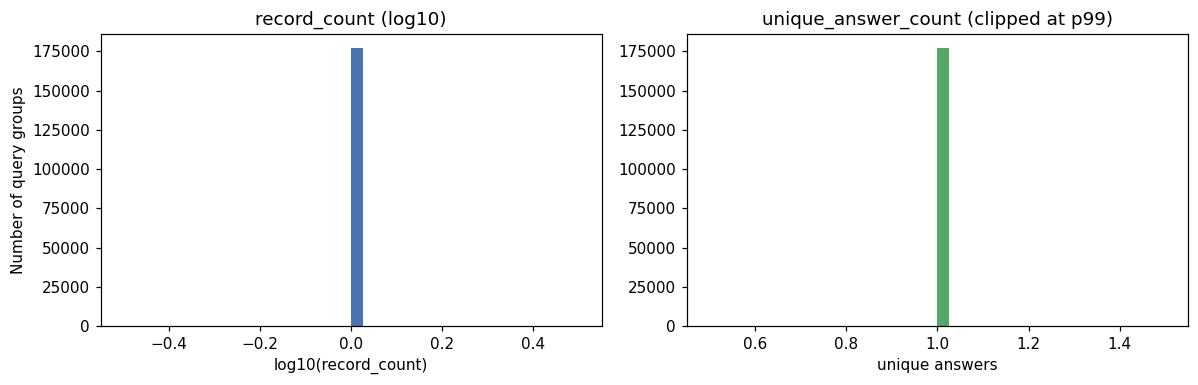

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(np.log10(df_full["record_count"].clip(lower=1)), bins=40, color="#4C72B0")
axes[0].set_title("record_count (log10)"); axes[0].set_xlabel("log10(record_count)"); axes[0].set_ylabel("Number of query groups")
axes[1].hist(df_full["unique_answer_count"].clip(upper=df_full["unique_answer_count"].quantile(0.99)), bins=40, color="#55A868")
axes[1].set_title("unique_answer_count (clipped at p99)"); axes[1].set_xlabel("unique answers")
fig.tight_layout()
save_fig(fig, "raw", "raw_distributions", "Histograms of record_count and unique_answer_count")

## Stage 2 — Sampling and the dynamic K range
**Dataset Input Configuration:** `MAX_ROWS = None` is set by default, so the entire dataset (all 177,169 rows) is used as input everywhere without sampling.
`K_RANGE` is built here from the **actual** number of rows (cap: one cluster per 20 rows at most).

In [11]:
if MAX_ROWS is not None and len(df_full) > MAX_ROWS:
    df = df_full.sample(n=MAX_ROWS, random_state=RANDOM_SEED).copy()
    print(f"Sampled {len(df):,} rows from {len(df_full):,} (MAX_ROWS={MAX_ROWS})")
else:
    df = df_full.copy()
    print(f"Using ENTIRE dataset: {len(df):,} rows (no sampling applied)")
df = df.reset_index(drop=True)
print("Rows used in experiments:", len(df))

K_MAX_EFFECTIVE = max(K_MIN + 1, min(K_MAX, len(df) // 20))
K_RANGE = list(range(K_MIN, K_MAX_EFFECTIVE + 1))
K_SELECT_MIN_EFFECTIVE = min(K_SELECT_MIN, K_RANGE[-1])
print("K range tested:", K_RANGE[0], "to", K_RANGE[-1], "| smallest K allowed to be chosen:", K_SELECT_MIN_EFFECTIVE)

sample_vs_full = pd.concat([
    df_full[["record_count", "unique_answer_count"]].describe().add_suffix("_full"),
    df[["record_count", "unique_answer_count"]].describe().add_suffix("_sample"),
], axis=1)
display(sample_vs_full)
save_df(df[["query_id"]], "sampling", "sampled_ids", "query_id of every row used")
save_df(sample_vs_full.reset_index().rename(columns={"index": "stat"}), "sampling", "sample_vs_full_summary", "Sample vs full statistics")

config_snapshot = {
    "RANDOM_SEED": RANDOM_SEED, "MAX_ROWS": MAX_ROWS, "n_rows_used": len(df), "K_RANGE": K_RANGE,
    "K_SELECT_MIN_EFFECTIVE": K_SELECT_MIN_EFFECTIVE, "UMAP_DIMS_TO_TEST": UMAP_DIMS_TO_TEST,
    "HDBSCAN_MIN_SIZES": HDBSCAN_MIN_SIZES, "DEGENERATE_SHARE": DEGENERATE_SHARE,
    "N_STABILITY_SEEDS": N_STABILITY_SEEDS, "N_RESAMPLES": N_RESAMPLES,
    "HF_ENCODER_MODELS": HF_ENCODER_MODELS, "ENCODER_GROUP": ENCODER_GROUP, "ENCODER_POOLING": ENCODER_POOLING, "TOPIC_K_RANGE": TOPIC_K_RANGE, "CLASSICAL_SPACES": CLASSICAL_SPACES,
    "RUN_DOC2VEC": RUN_DOC2VEC, "RUN_GLOVE": RUN_GLOVE, "RUN_LLM_LABELS": RUN_LLM_LABELS,
    "LLM_LABEL_MODEL": LLM_LABEL_MODEL, "DEVICE": DEVICE, "torch_version": torch.__version__,
}
save_json(config_snapshot, "setup", "config_snapshot", "All settings used in this run")

Sampled 5,000 rows from 177,169 (MAX_ROWS=5000)
Rows used in experiments: 5000
K range tested: 2 to 25 | smallest K allowed to be chosen: 5


,record_count_full,unique_answer_count_full,record_count_sample,unique_answer_count_sample
count,177169.0,177169.0,5000.0,5000.0
mean,1.0,1.0,1.0,1.0
std,0.0,0.0,0.0,0.0
min,1.0,1.0,1.0,1.0
25%,1.0,1.0,1.0,1.0
50%,1.0,1.0,1.0,1.0
75%,1.0,1.0,1.0,1.0
max,1.0,1.0,1.0,1.0


  [saved csv  ] experiment_outputs/02_sampling/sampled_ids.csv  (44.0 KB)
  [saved csv  ] experiment_outputs/02_sampling/sample_vs_full_summary.csv  (0.3 KB)
  [saved json ] experiment_outputs/00_setup/config_snapshot.json  (1.6 KB)


PosixPath('experiment_outputs/00_setup/config_snapshot.json')

## Stage 3 — Text cleaning (step by step)
### 3.1 Cleaning functions
Regexes use single backslashes (the very first version of your notebook had doubled backslashes that silently disabled URL removal). A leading `. ` is also stripped because many queries start with `. asking about …`.

In [12]:
def clean_text(value):
    """Lowercase, remove URLs and unusual symbols, collapse spaces, strip leading punctuation."""
    if pd.isna(value):
        return ""
    text = str(value).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s.,;:?!'/-]", " ", text)   # '/' kept so doses such as "2ml/l" survive
    text = re.sub(r"\s+", " ", text).strip()
    return text.lstrip(" .,;:-").strip()

def parse_answer_list(value):
    """Turn the stringified list in embedding_answers into a list of cleaned answers."""
    if isinstance(value, list):
        answers = value
    else:
        try:
            answers = ast.literal_eval(str(value))
        except (ValueError, SyntaxError):
            answers = [str(value)]
    if not isinstance(answers, list):
        answers = [answers]
    return [clean_text(a) for a in answers if clean_text(a)]

def parse_failed(value):
    try:
        ast.literal_eval(str(value))
        return False
    except (ValueError, SyntaxError):
        return True

def remove_boilerplate(text):
    phrases = [r"\bdear farmer\b", r"\bdear sir\b", r"\bdear madam\b", r"\bthank you\b", r"\bthanks\b",
               r"\bregards\b", r"\byours faithfully\b", r"\bhope this helps\b"]
    for phrase in phrases:
        text = re.sub(phrase, " ", text)
    return re.sub(r"\s+", " ", text).strip()

def truncate_words(text, limit=80):
    return " ".join(text.split()[:limit])

print("Cleaning functions defined.")

Cleaning functions defined.


### 3.2 Unit-test the cleaners

In [13]:
test_inputs = ["Visit https://example.com/info NOW!!!   Thanks",
               "Apply 2.5 kg/ha of N@P#K   fertilizer",
               np.nan,
               "Dear Farmer, spray   neem oil. Regards",
               ". asking about kisan credit card"]
test_table = pd.DataFrame({"input": [str(t) for t in test_inputs],
                           "clean_text": [clean_text(t) for t in test_inputs],
                           "no_boilerplate": [remove_boilerplate(clean_text(t)) for t in test_inputs]})
display(test_table)
assert test_table.loc[0, "clean_text"].startswith("visit now"), "URL removal failed"
assert test_table.loc[2, "clean_text"] == "", "NaN handling failed"
assert test_table.loc[4, "clean_text"] == "asking about kisan credit card", "leading punctuation not stripped"
print("All cleaning assertions passed.")
save_df(test_table, "cleaning", "cleaning_unit_tests", "Before/after on hand-made strings")

,input,clean_text,no_boilerplate
0,Visit https://example.com/info NOW!!! Thanks,visit now!!! thanks,visit now!!!
1,Apply 2.5 kg/ha of N@P#K fertilizer,apply 2.5 kg/ha of n p k fertilizer,apply 2.5 kg/ha of n p k fertilizer
2,nan,,
3,"Dear Farmer, spray neem oil. Regards","dear farmer, spray neem oil. regards",", spray neem oil."
4,. asking about kisan credit card,asking about kisan credit card,asking about kisan credit card


All cleaning assertions passed.
  [saved csv  ] experiment_outputs/03_cleaning/cleaning_unit_tests.csv  (0.4 KB)


PosixPath('experiment_outputs/03_cleaning/cleaning_unit_tests.csv')

### 3.3 Step A — Parse the answer lists

In [14]:
df["parse_failed"] = df["embedding_answers"].apply(parse_failed)
df["answers_list"] = df["embedding_answers"].apply(parse_answer_list)
df["n_answers_parsed"] = df["answers_list"].apply(len)
print("Rows where list-parsing failed:", int(df["parse_failed"].sum()))
print("Rows with zero usable answers:", int((df["n_answers_parsed"] == 0).sum()))
display(df[["n_answers_parsed", "unique_answer_count"]].describe().T)
save_df(df[["query_id", "parse_failed", "n_answers_parsed", "unique_answer_count"]], "cleaning", "step_A_parsed_answers", "Parsing outcome per row")

Rows where list-parsing failed: 0
Rows with zero usable answers: 4


,count,mean,std,min,25%,50%,75%,max
n_answers_parsed,5000.0,0.9992,0.028276,0.0,1.0,1.0,1.0,1.0
unique_answer_count,5000.0,1.0000,0.000000,1.0,1.0,1.0,1.0,1.0


  [saved csv  ] experiment_outputs/03_cleaning/step_A_parsed_answers.csv  (92.8 KB)


PosixPath('experiment_outputs/03_cleaning/step_A_parsed_answers.csv')

### 3.4 Step B — Clean the question and join the answers

In [15]:
df["query_clean"] = df["query_text"].apply(clean_text)
df["representative_clean"] = df["representative_question"].apply(clean_text)
df["answer_text"] = df["answers_list"].apply(lambda answers: " ".join(answers))

step_b = df[["query_id", "representative_question", "representative_clean", "answer_text"]].copy()
step_b["answer_text"] = step_b["answer_text"].str[:300]
display(step_b.sample(5, random_state=RANDOM_SEED))
save_df(step_b, "cleaning", "step_B_cleaned_questions_answers", "Raw vs cleaned question + answer (answer cut at 300 chars)")

,query_id,representative_question,representative_clean,answer_text
1501,Q_130649,asking about extension programe,asking about extension programe,"atma,rkvy,kvk"
2586,Q_072314,asking for the insect pest management in paddy.,asking for the insect pest management in paddy.,i suggest him to spray malathion 2g per litre ...
2653,Q_052622,asking about the govt. scheme,asking about the govt. scheme,advised to contact kvk concerned officer
1055,Q_000690,asking about brinjal shoot borer problem,asking about brinjal shoot borer problem,suggested to spray rocket 2ml/litre of water
705,Q_139814,asking about the recommended fym dose for ginger,asking about the recommended fym dose for ginger,suggested to apply fym 1 quintal per bigha


  [saved csv  ] experiment_outputs/03_cleaning/step_B_cleaned_questions_answers.csv  (831.8 KB)


PosixPath('experiment_outputs/03_cleaning/step_B_cleaned_questions_answers.csv')

### 3.5 Step C — Build the text variants

**Main input = Query + Response** (`query_answer_text`), as you requested.

**Why `question: … answer: …` instead of `[SEP]`?** `[SEP]` is a special token for BERT-style tokenizers (MiniLM) but is just literal characters for others (MPNet, E5, BGE, GTE) and became the junk keyword `sep` in your first TF-IDF output. Plain words work identically in all 8 representations.

**Which "query"?** `representative_question` is used (the representative wording of each query group); this is what the original notebook used. `query_clean` is also kept in the table so you can switch by editing one line.

The other four variants exist **only to test, in Stage 10, whether Query + Response really is the better input**; they are not used for the main results.

| Column | Meaning |
|---|---|
| `query_answer_text` | `question: <query> answer: <all answers>` (**main input**) |
| `question_only_text` | `question: <query>` |
| `answer_only_text` | `answer: <all answers>` |
| `boilerplate_stripped_text` | main input with greetings / sign-offs removed |
| `truncated_answer_text` | question + only the first 80 answer words |

In [16]:
def build_text(q, a):
    return (("question: " + q) + (" answer: " + a if a else "")).strip()

df["query_answer_text"] = [build_text(q, a) for q, a in zip(df["representative_clean"], df["answer_text"])]
df["question_only_text"] = ["question: " + q for q in df["representative_clean"]]
df["answer_only_text"] = ["answer: " + a if a else "answer:" for a in df["answer_text"]]
df["boilerplate_stripped_text"] = df["query_answer_text"].apply(remove_boilerplate)
df["truncated_answer_text"] = [build_text(q, truncate_words(a, 80)) for q, a in zip(df["representative_clean"], df["answer_text"])]

TEXT_COLUMNS = ["query_answer_text", "question_only_text", "answer_only_text", "boilerplate_stripped_text", "truncated_answer_text"]
empty_counts = {c: int((df[c].str.replace("question:", "").str.replace("answer:", "").str.strip() == "").sum()) for c in TEXT_COLUMNS}
print("Empty texts per variant:", empty_counts)
display(df[["query_id"] + TEXT_COLUMNS].head(3).T)
save_df(df[["query_id"] + TEXT_COLUMNS], "text", "all_text_variants", "The five text representations for every row")
save_json(empty_counts, "text", "empty_text_counts", "Empty strings per text variant")

Empty texts per variant: {'query_answer_text': 0, 'question_only_text': 0, 'answer_only_text': 4, 'boilerplate_stripped_text': 0, 'truncated_answer_text': 0}


,0,1,2
query_id,Q_091629,Q_075996,Q_028049
query_answer_text,"question: query regarding some local chicken, ...",question: asking about the control of leaf cur...,question: asking about the vitamin for tomato ...
question_only_text,"question: query regarding some local chicken, ...",question: asking about the control of leaf cur...,question: asking about the vitamin for tomato
answer_only_text,answer: told him to change the bedding materia...,answer: suggested him to spray rogor 2ml/litre...,answer: advised him to spray tracel 2 2gm/litr...
boilerplate_stripped_text,"question: query regarding some local chicken, ...",question: asking about the control of leaf cur...,question: asking about the vitamin for tomato ...
truncated_answer_text,"question: query regarding some local chicken, ...",question: asking about the control of leaf cur...,question: asking about the vitamin for tomato ...


  [saved csv  ] experiment_outputs/04_text_representations/all_text_variants.csv  (2756.8 KB)
  [saved json ] experiment_outputs/04_text_representations/empty_text_counts.json  (0.1 KB)


PosixPath('experiment_outputs/04_text_representations/empty_text_counts.json')

### 3.6 Text length statistics
Encoders truncate long inputs (MiniLM 256 tokens, MPNet 384, others 512). Roughly 1.3 tokens per word, so we also report how many texts may be truncated.

,variant,count,mean,std,min,50%,90%,99%,max,pct_over_256_tokens_est,pct_over_512_tokens_est
0,query_answer_text,5000.0,22.4818,15.475476,3.0,19.0,35.0,93.00,229.0,0.02,0.0
1,question_only_text,5000.0,7.9976,3.263821,2.0,8.0,11.0,18.00,69.0,0.00,0.0
2,answer_only_text,5000.0,14.4850,14.172507,1.0,11.0,26.0,83.00,221.0,0.02,0.0
3,boilerplate_stripped_text,5000.0,22.4814,15.475385,3.0,19.0,35.0,93.00,229.0,0.02,0.0
4,truncated_answer_text,5000.0,22.2442,13.992288,3.0,19.0,35.0,88.01,138.0,0.00,0.0


  [saved png  ] experiment_outputs/04_text_representations/text_length_hist.png  (47.7 KB)


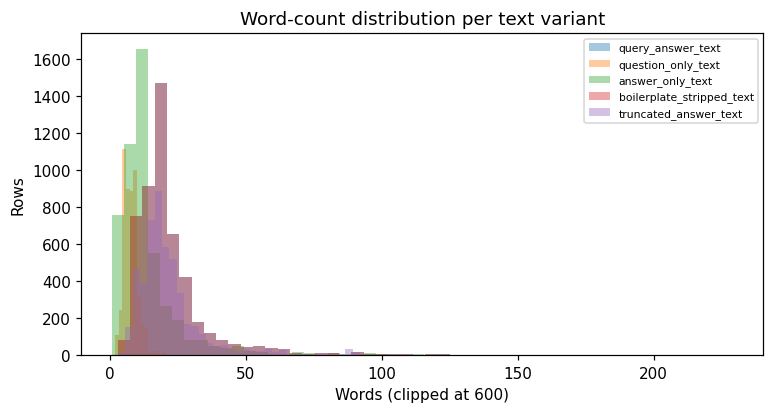

  [saved csv  ] experiment_outputs/04_text_representations/text_length_stats.csv  (0.5 KB)


PosixPath('experiment_outputs/04_text_representations/text_length_stats.csv')

In [17]:
length_table = pd.DataFrame({c: df[c].str.split().str.len() for c in TEXT_COLUMNS})
length_stats = length_table.describe(percentiles=[0.5, 0.9, 0.99]).T.reset_index().rename(columns={"index": "variant"})
length_stats["pct_over_256_tokens_est"] = [(length_table[c] * 1.3 > 256).mean() * 100 for c in TEXT_COLUMNS]
length_stats["pct_over_512_tokens_est"] = [(length_table[c] * 1.3 > 512).mean() * 100 for c in TEXT_COLUMNS]
display(length_stats)

fig, ax = plt.subplots(figsize=(8, 3.8))
for col in TEXT_COLUMNS:
    ax.hist(length_table[col].clip(upper=600), bins=50, alpha=0.4, label=col)
ax.set_xlabel("Words (clipped at 600)"); ax.set_ylabel("Rows"); ax.set_title("Word-count distribution per text variant"); ax.legend(fontsize=7)
save_fig(fig, "text", "text_length_hist", "Word count histograms of the text variants")
save_df(length_stats, "text", "text_length_stats", "Word-count statistics per text variant")

## Stage 4 — Reusable analysis functions
Functions only; nothing heavy runs here.

### 4.1 Internal cluster-quality metrics
* **WCSS** (within-cluster sum of squares) → the **elbow method**.
* **Silhouette** (higher is better), **Davies-Bouldin** (lower is better), **Calinski-Harabasz** (higher is better).
* Noise (`-1`, HDBSCAN only) is excluded from the metrics and reported as `noise_ratio`.

In [18]:
def safe_cluster_metrics(vectors, labels):
    labels = np.asarray(labels)
    keep = labels != -1
    x, y = vectors[keep], labels[keep]
    unique = np.unique(y)
    noise_ratio = float(1 - keep.mean())
    if len(unique) < 2 or len(unique) >= len(y):
        return {"silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan,
                "n_clusters": int(len(unique)), "noise_ratio": noise_ratio}
    sample_size = min(1500, len(y))     # silhouette is O(n^2): score a fixed random subset
    return {"silhouette": float(silhouette_score(x, y, sample_size=sample_size, random_state=RANDOM_SEED)),
            "davies_bouldin": float(davies_bouldin_score(x, y)),
            "calinski_harabasz": float(calinski_harabasz_score(x, y)),
            "n_clusters": int(len(unique)), "noise_ratio": noise_ratio}

def wcss(vectors, labels):
    """Within-cluster sum of squared distances to each cluster mean (works for any algorithm)."""
    total = 0.0
    for c in np.unique(labels):
        members = vectors[labels == c]
        total += float(((members - members.mean(axis=0)) ** 2).sum())
    return total

def cluster_sizes(labels):
    return pd.Series(labels).value_counts().sort_index().rename("size").rename_axis("cluster").reset_index()

### 4.2 Clustering, dimensionality reduction and noise handling
* `labels_for_k` — one entry point for **KMeans, GMM (diagonal covariance), Ward**. Ward uses SciPy's linkage, computed **once** per vector space and cut at every K (identical result to sklearn's Ward, much faster for a sweep).
* `finalize_labels` — HDBSCAN noise points are assigned to the nearest cluster centre, so that every method labels **all** rows and can be compared fairly. The raw noise ratio is still reported.
* `umap_reduce` — cosine-metric UMAP (embeddings are L2-normalised).

In [19]:
_LINK_CACHE = {}

def labels_for_k(vectors, algo, k, seed=RANDOM_SEED, key=None):
    if algo == "kmeans":
        return KMeans(n_clusters=k, random_state=seed, n_init=10).fit_predict(vectors)
    if algo == "gmm":
        for reg in (1e-5, 1e-4, 1e-3, 1e-2):          # retry with stronger regularisation if a component collapses
            try:
                return GaussianMixture(n_components=k, covariance_type="diag", reg_covar=reg, random_state=seed).fit_predict(vectors)
            except ValueError:
                continue
        raise ValueError("GMM failed for every regularisation level")
    if algo == "ward":
        if key is None:
            return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(vectors)
        if key not in _LINK_CACHE:
            _LINK_CACHE[key] = linkage(vectors, method="ward")
        return fcluster(_LINK_CACHE[key], t=k, criterion="maxclust") - 1
    raise ValueError("Unknown algorithm: " + algo)

def hdbscan_labels(vectors, min_cluster_size):
    import hdbscan as _hdb
    model = _hdb.HDBSCAN(min_cluster_size=min_cluster_size, metric="euclidean", gen_min_span_tree=True)
    labels = model.fit_predict(vectors)
    try:
        validity = float(model.relative_validity_)
    except Exception:
        validity = np.nan
    return labels, validity

def finalize_labels(vectors, labels):
    """Assign HDBSCAN noise (-1) to the nearest cluster centre; leave other labels unchanged."""
    labels = np.asarray(labels).copy()
    noise = labels == -1
    if not noise.any() or noise.all():
        return labels
    ids = np.unique(labels[~noise])
    centres = np.vstack([vectors[labels == c].mean(axis=0) for c in ids])
    labels[noise] = ids[pairwise_distances_argmin(vectors[noise], centres)]
    return labels

def umap_reduce(vectors, dimensions, seed=RANDOM_SEED):
    import umap as _umap
    reducer = _umap.UMAP(n_components=dimensions, n_neighbors=15, min_dist=0.0, metric="cosine", random_state=seed)
    return reducer.fit_transform(vectors)

def reduce_vectors(vectors, method, dimensions=50):
    if method == "none":
        return vectors
    if method == "pca":
        n_comp = min(dimensions, vectors.shape[1] - 1, vectors.shape[0] - 1)
        return PCA(n_components=n_comp, random_state=RANDOM_SEED).fit_transform(vectors)
    if method == "umap":
        return umap_reduce(vectors, dimensions)
    raise ValueError("Unknown reduction method: " + method)

### 4.3 Choosing K: elbow + composite score
For each sweep we compute:

1. **Elbow K** — kneedle-style: normalise `K` and WCSS to [0, 1] and take the K whose point lies farthest below the straight line joining the first and last point. `elbow_strength` is that distance; below `0.05` we flag **"no clear elbow"** (typical for high-dimensional embeddings where WCSS falls almost linearly).
2. **Composite K** — min-max-normalise silhouette (↑), −Davies-Bouldin (↑) and Calinski-Harabasz (↑) over the candidate Ks and average them. No weights are invented: three standard, independent internal criteria, equal weight.
3. **Final K = composite K** restricted to `K ≥ K_SELECT_MIN`. The elbow K and the unconstrained silhouette K are kept as cross-checks (`elbow_agrees` = elbow within ±2 of the final K).

In [20]:
def minmax(values):
    v = np.asarray(values, dtype=float)
    lo, hi = np.nanmin(v), np.nanmax(v)
    if not np.isfinite(lo) or not np.isfinite(hi) or hi - lo < 1e-12:
        return np.full_like(v, 0.5)
    return (v - lo) / (hi - lo)

def elbow_k(ks, w):
    ks, w = np.asarray(ks, float), np.asarray(w, float)
    if len(ks) < 3 or w.max() - w.min() < 1e-12:
        return int(ks[0]), 0.0
    x = (ks - ks.min()) / (ks.max() - ks.min())
    y = (w - w.min()) / (w.max() - w.min())
    gap = (y[0] + (y[-1] - y[0]) * x) - y          # line from first to last point minus the curve
    best = int(np.argmax(gap))
    return int(ks[best]), float(gap[best])

def sweep_k(vectors, algo, k_range, seed=RANDOM_SEED, key=None):
    rows, labels_by_k = [], {}
    for k in k_range:
        lab = labels_for_k(vectors, algo, k, seed=seed, key=key)
        labels_by_k[k] = lab
        rows.append({"k": k, "wcss": wcss(vectors, lab), **safe_cluster_metrics(vectors, lab)})
    return pd.DataFrame(rows), labels_by_k

def choose_k(sweep, k_select_min):
    valid = sweep.dropna(subset=["silhouette"]).copy()
    cand = valid[valid["k"] >= k_select_min].copy()
    if cand.empty:
        cand = valid.copy()
    cand["composite"] = (minmax(cand["silhouette"]) + minmax(-cand["davies_bouldin"]) + minmax(cand["calinski_harabasz"])) / 3
    k_final = int(cand.loc[cand["composite"].idxmax(), "k"])
    k_elbow, strength = elbow_k(sweep["k"].values, sweep["wcss"].values)
    k_sil_free = int(valid.loc[valid["silhouette"].idxmax(), "k"])
    k_sil_constrained = int(cand.loc[cand["silhouette"].idxmax(), "k"])
    return {"k_final": k_final, "k_elbow": k_elbow, "elbow_strength": round(strength, 3),
            "elbow_clear": bool(strength >= 0.05), "elbow_agrees": bool(abs(k_elbow - k_final) <= 2),
            "k_silhouette_unconstrained": k_sil_free, "k_silhouette_constrained": k_sil_constrained,
            "composite_table": cand[["k", "composite"]]}

### 4.4 Metrics that do not depend on one vector space
Silhouette computed *inside the space that was clustered* is not comparable between spaces (a 10-D UMAP space always looks "more separated" than a 768-D one). So the leaderboard (Stage 9) uses these space-independent measures:

* **Cross-space consensus silhouette** — a clustering is re-scored (cosine silhouette) in **every other** raw vector space (its own encoder is excluded). A clustering that only looks good in the space it was built in scores low; one that reflects structure shared across representations scores high. Per reference space the scores are z-scored over all configurations before averaging, because spaces have different baseline similarity (e.g. E5/GTE random-pair cosine ≈ 0.81 in your sanity check).
* **NPMI topic coherence** — for each cluster, its top-10 TF-IDF words are checked for how often they co-occur in documents (normalised pointwise mutual information, −1…1). Size-weighted mean over clusters. This looks only at the words, not at any embedding.
* **Stability** — ARI between the full clustering and clusterings refit on random 80% subsets.
* **Noise ratio** (HDBSCAN) and **largest-cluster share** (degeneracy check).

*Limitation stated honestly:* NPMI is lexical, so it mildly favours TF-IDF-based spaces; the consensus score is mildly favoured by encoders that resemble the others. This is why both are used together, with equal weight, and why the intrusion test (Stage 14) and manual review remain necessary.

In [21]:
STOP_WORDS = list(ENGLISH_STOP_WORDS.union({"question", "answer"}))

def build_coherence_index(texts):
    """Binary document-term matrix (for co-occurrence) + TF-IDF weights (to pick each cluster's top words)."""
    cv = CountVectorizer(stop_words=STOP_WORDS, min_df=5, max_df=0.5, binary=True, token_pattern=r"(?u)\b[a-z][a-z]+\b")
    X = cv.fit_transform(texts).tocsc()
    T = TfidfTransformer(norm="l2").fit_transform(X).tocsr()
    return {"X": X, "T": T, "n_docs": X.shape[0], "terms": np.array(cv.get_feature_names_out())}

def npmi_coherence(labels, index, top_n=10):
    labels = np.asarray(labels)
    X, T, n_docs = index["X"], index["T"], index["n_docs"]
    scores, weights = [], []
    for c in np.unique(labels):
        members = np.where(labels == c)[0]
        if len(members) < 5:
            continue
        w = np.asarray(T[members].mean(axis=0)).ravel()
        top = np.argsort(-w)[:top_n]
        sub = X[:, top]
        co = (sub.T @ sub).toarray() / n_docs
        p = np.diag(co)
        vals = []
        for i in range(len(top)):
            for j in range(i + 1, len(top)):
                pij = co[i, j]
                if pij <= 0 or p[i] <= 0 or p[j] <= 0:
                    vals.append(-1.0)
                elif pij >= 1:
                    vals.append(1.0)
                else:
                    vals.append(np.log(pij / (p[i] * p[j])) / (-np.log(pij)))
        scores.append(np.mean(vals)); weights.append(len(members))
    return float(np.average(scores, weights=weights)) if scores else np.nan

def cross_space_silhouettes(labels, ref_spaces, exclude=(), seed=RANDOM_SEED):
    """Cosine silhouette of `labels` in every reference space except those in `exclude`."""
    labels = np.asarray(labels)
    out = {}
    for name, vecs in ref_spaces.items():
        if name in exclude:
            out[name] = np.nan
            continue
        try:
            out[name] = float(silhouette_score(vecs, labels, metric="cosine", sample_size=min(1500, len(labels)), random_state=seed))
        except Exception:
            out[name] = np.nan
    return out

def max_cluster_share(labels):
    return float(pd.Series(labels).value_counts(normalize=True).max())

def top_terms(texts, labels, top_n=10):
    vectorizer = TfidfVectorizer(stop_words=STOP_WORDS, max_features=20000, ngram_range=(1, 2), min_df=2)
    matrix = vectorizer.fit_transform(texts)
    terms = np.array(vectorizer.get_feature_names_out())
    labels = np.asarray(labels)
    output = []
    for cluster_id in sorted(set(labels)):
        if cluster_id == -1:
            continue
        idx = np.where(labels == cluster_id)[0]
        if not len(idx):
            continue
        scores = np.asarray(matrix[idx].mean(axis=0)).ravel()
        best = scores.argsort()[::-1][:top_n]
        output.append({"cluster": int(cluster_id), "size": int(len(idx)), "top_terms": ", ".join(terms[best])})
    return pd.DataFrame(output)

def heatmap(matrix_df, title, cmap="viridis", vmin=None, vmax=None):
    fig, ax = plt.subplots(figsize=(1.0 + 0.9 * len(matrix_df), 0.6 + 0.8 * len(matrix_df)))
    im = ax.imshow(matrix_df.values, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(matrix_df.columns))); ax.set_xticklabels(matrix_df.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(matrix_df.index))); ax.set_yticklabels(matrix_df.index)
    for i in range(matrix_df.shape[0]):
        for j in range(matrix_df.shape[1]):
            ax.text(j, i, f"{matrix_df.values[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046)
    return fig

print("Analysis functions ready.")

Analysis functions ready.


### 4.5 Helpers for the domain-encoder, topic-input and overlap experiments
Definitions only. They are used by Stages 10, 15, 17 and 18.

* `auto_cluster` — the same *"sweep K → choose K"* logic as Stage 8, packaged so it can be re-run on any new set of vectors (a different text input).
* `zscore_consensus` — the cross-space consensus of Stage 4.4, z-scored with the **same** per-space mean/std as the leaderboard, so new runs are directly comparable with the leaderboard rows. A `seed` argument changes the random silhouette subset, which lets us measure *measurement noise*, not only clustering noise.
* `margin_to_other_centroids` / `differentiation_metrics` — how far each record is from its own cluster compared with the nearest *other* cluster.
* `recoverability` — can a classifier trained on a **different** representation (words, or another encoder) recover the clusters? Clusters that blur together are confused by it. (Not meaningful inside the representation that produced the clusters: KMeans cells are linearly separable there by construction.)
* `cluster_term_sets` / `jaccard` — which distinctive words each cluster uses, and how much two clusters share them.

In [22]:
def zscore_consensus(labels, exclude_enc, seed=RANDOM_SEED):
    """(z-scored consensus, raw consensus) using the leaderboard's per-space mean/std (S_COL_MEAN / S_COL_STD)."""
    cross = cross_space_silhouettes(labels, EMBEDDINGS, exclude=(exclude_enc,), seed=seed)
    zs = [(v - S_COL_MEAN[n]) / (S_COL_STD[n] + 1e-12) for n, v in cross.items() if not np.isnan(v)]
    raw = [v for v in cross.values() if not np.isnan(v)]
    return (float(np.mean(zs)) if zs else np.nan), (float(np.mean(raw)) if raw else np.nan)

def auto_cluster(raw_vectors, algo, reduce, seed=RANDOM_SEED, tag="run"):
    """Sweep K (or HDBSCAN min_cluster_size), choose it with the Stage 4.3 rule, return labels + details."""
    space = umap_reduce(raw_vectors, UMAP_DIM, seed) if reduce == "umap" else raw_vectors
    if algo == "hdbscan":
        rows, labs = [], {}
        for mcs in HDBSCAN_MIN_SIZES:
            lab, validity = hdbscan_labels(space, mcs)
            labs[mcs] = lab
            rows.append({"min_cluster_size": mcs, "n_clusters": len(set(lab)) - (1 if -1 in lab else 0),
                         "noise_ratio_before": float((lab == -1).mean()), "relative_validity": validity})
        sweep = pd.DataFrame(rows)
        best = pick_hdbscan(sweep, K_SELECT_MIN_EFFECTIVE)
        raw_lab = labs[best]
        return {"labels": finalize_labels(space, raw_lab), "param": best, "k": int(len(set(raw_lab)) - (1 if -1 in raw_lab else 0)),
                "space": space, "sweep": sweep, "choice": {"min_cluster_size": best}}
    sweep, labs = sweep_k(space, algo, K_RANGE, seed=seed, key=f"{tag}|{seed}")
    choice = choose_k(sweep, K_SELECT_MIN_EFFECTIVE)
    return {"labels": np.asarray(labs[choice["k_final"]]), "param": choice["k_final"], "k": choice["k_final"], "space": space,
            "sweep": sweep, "choice": {k: v for k, v in choice.items() if k != "composite_table"}}

def centroid_matrix(vectors, labels):
    ids = np.unique(labels)
    cents = np.vstack([vectors[labels == c].mean(axis=0) for c in ids])
    return ids, normalize(cents)

def margin_to_other_centroids(vectors, labels):
    """For every record: cosine to its own cluster centre minus cosine to the nearest OTHER cluster centre."""
    labels = np.asarray(labels)
    ids, cents = centroid_matrix(vectors, labels)
    sim = normalize(vectors) @ cents.T
    own_pos = np.searchsorted(ids, labels)
    rows = np.arange(len(labels))
    own = sim[rows, own_pos]
    other = sim.copy()
    other[rows, own_pos] = -np.inf
    nearest_pos = other.argmax(axis=1)
    return ids, cents, own, ids[nearest_pos], own - other[rows, nearest_pos]

def differentiation_metrics(labels, vectors):
    labels = np.asarray(labels)
    if len(np.unique(labels)) < 2:
        return {}
    sil = silhouette_samples(vectors, labels, metric="cosine")
    ids, cents, own, nearest, margin = margin_to_other_centroids(vectors, labels)
    off = (cents @ cents.T)[np.triu_indices(len(ids), 1)]
    return {"mean_silhouette": float(sil.mean()), "share_negative_silhouette": float((sil < 0).mean()),
            "mean_margin": float(margin.mean()), "share_nonpositive_margin": float((margin <= 0).mean()),
            "mean_centroid_cosine": float(off.mean()), "max_centroid_cosine": float(off.max())}

def recoverability(labels, features, n_splits=5):
    """Cross-validated logistic regression that predicts the cluster from `features`. Returns accuracy, macro-F1 and predictions."""
    y = np.asarray(labels)
    ids, counts = np.unique(y, return_counts=True)
    splits = int(min(n_splits, counts.min()))
    if len(ids) < 2 or splits < 2:
        return None
    cv = StratifiedKFold(n_splits=splits, shuffle=True, random_state=RANDOM_SEED)
    pred = cross_val_predict(LogisticRegression(max_iter=300, C=5.0), features, y, cv=cv)
    return {"accuracy": float(accuracy_score(y, pred)), "macro_f1": float(f1_score(y, pred, average="macro")), "pred": pred}

def cluster_term_sets(labels, top_n=25):
    labels = np.asarray(labels)
    T, terms = COH_INDEX["T"], COH_INDEX["terms"]
    out = {}
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        w = np.asarray(T[idx].mean(axis=0)).ravel()
        order = np.argsort(-w)[:top_n]
        out[int(c)] = {"idx": order, "terms": list(terms[order]), "weights": w[order]}
    return out

def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / max(1, len(a | b))

print("Helpers for E10-E14 ready.")

Helpers for E10-E14 ready.


## Stage 5 — Build every vector space
All representations of `query_answer_text` go into the dictionary `EMBEDDINGS` and are saved to `05_embeddings/`.
Encoder vectors are cached on disk by a fingerprint of the texts.
### 5.1 Embedding cache helpers

In [23]:
EMBEDDINGS = {}
MEM_CACHE = {}

def load_encoder(model_key):
    """Load one encoder. Word-level BERTs (SciBERT, AgriBERT, SPECTER) are wrapped with an explicit pooling layer;
    ready-made sentence-transformers models are loaded as published."""
    from sentence_transformers import SentenceTransformer, models
    name = HF_ENCODER_MODELS[model_key]
    if model_key in ENCODER_POOLING:
        word = models.Transformer(name, max_seq_length=ENCODER_MAX_SEQ.get(model_key, 512))
        try:
            dim = word.get_word_embedding_dimension()
        except AttributeError:
            dim = word.auto_model.config.hidden_size
        pool = models.Pooling(dim, pooling_mode=ENCODER_POOLING[model_key])
        model = SentenceTransformer(modules=[word, pool], device=DEVICE)
    else:
        model = SentenceTransformer(name, device=DEVICE)
        if model_key in ENCODER_MAX_SEQ:
            model.max_seq_length = ENCODER_MAX_SEQ[model_key]
    ENCODER_INFO[model_key] = {"max_seq_length": int(model.max_seq_length)}
    return model

def text_fingerprint(texts):
    return hashlib.md5("\n".join(texts).encode("utf-8")).hexdigest()[:10]

def get_hf_embeddings(texts, model_key, tag="main", batch_size=64):
    texts = list(texts)
    fp = text_fingerprint(texts)
    mem_key = (model_key, fp)
    if mem_key in MEM_CACHE:
        return MEM_CACHE[mem_key]
    cache_file = stage_folder("emb") / f"hf_{model_key}_{tag}_{fp}.npy"
    if cache_file.exists():
        vectors = np.load(cache_file)
        if len(vectors) == len(texts):
            MEM_CACHE[mem_key] = vectors
            print(f"  (cache hit) {cache_file.name}")
            return vectors
    model = load_encoder(model_key)
    model_texts = ["query: " + t for t in texts] if model_key == "e5" else texts
    start = time.time()
    vectors = model.encode(model_texts, batch_size=batch_size, show_progress_bar=True,
                           normalize_embeddings=True, convert_to_numpy=True)
    print(f"  encoded {len(texts)} texts with {model_key} in {time.time() - start:.1f}s -> shape {vectors.shape}")
    np.save(cache_file, vectors)
    _register("emb", cache_file, "npy", f"HF embeddings, model={HF_ENCODER_MODELS[model_key]}, tag={tag}")
    MEM_CACHE[mem_key] = vectors
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return vectors

### 5.2 Classical A — TF-IDF + SVD (LSA)

In [24]:
main_texts = df["query_answer_text"].fillna("").tolist()

tfidf = TfidfVectorizer(stop_words=STOP_WORDS, max_features=20000, ngram_range=(1, 2), min_df=2)
sparse = tfidf.fit_transform(main_texts)
print("TF-IDF matrix shape (docs, vocab):", sparse.shape)
print("Sparsity: {:.2%} non-zero".format(sparse.nnz / (sparse.shape[0] * sparse.shape[1])))

terms = np.array(tfidf.get_feature_names_out())
mean_weight = np.asarray(sparse.mean(axis=0)).ravel()
top_global = pd.DataFrame({"term": terms, "mean_tfidf": mean_weight}).sort_values("mean_tfidf", ascending=False).head(50)
display(top_global.head(15))
save_df(top_global, "emb", "tfidf_top50_global_terms", "Highest mean TF-IDF terms across all documents")

TF-IDF matrix shape (docs, vocab): (5000, 8370)
Sparsity: 0.25% non-zero


,term,mean_tfidf
1242,asking,0.038541
8121,water,0.035426
7052,spray,0.030250
2411,control,0.026315
4538,litre,0.025410
4543,litre water,0.024315
1062,apply,0.022532
7358,suggested,0.020697
1283,asking control,0.019512
2815,details,0.018808


  [saved csv  ] experiment_outputs/05_embeddings/tfidf_top50_global_terms.csv  (1.4 KB)


PosixPath('experiment_outputs/05_embeddings/tfidf_top50_global_terms.csv')

TF-IDF+SVD vector shape: (5000, 100)
Variance explained by 100 components: 32.4%
  [saved png  ] experiment_outputs/05_embeddings/tfidf_svd_explained_variance.png  (39.5 KB)


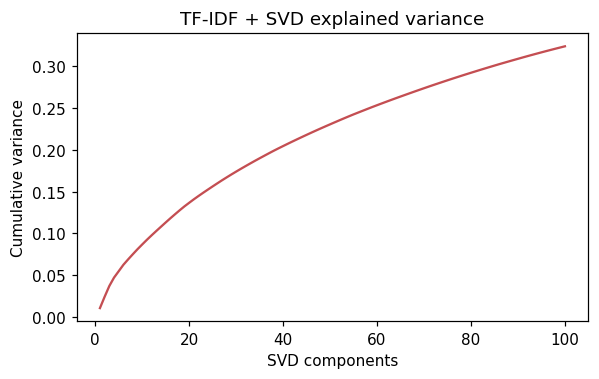

  [saved npy  ] experiment_outputs/05_embeddings/vectors_tfidf_svd.npy  (3906.4 KB)


PosixPath('experiment_outputs/05_embeddings/vectors_tfidf_svd.npy')

In [25]:
n_components = min(100, sparse.shape[1] - 1, sparse.shape[0] - 1)
svd = TruncatedSVD(n_components=n_components, random_state=RANDOM_SEED)
EMBEDDINGS["tfidf_svd"] = normalize(svd.fit_transform(sparse))
print("TF-IDF+SVD vector shape:", EMBEDDINGS["tfidf_svd"].shape)

cum_var = np.cumsum(svd.explained_variance_ratio_)
print(f"Variance explained by {n_components} components: {cum_var[-1]:.1%}")
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(range(1, len(cum_var) + 1), cum_var, color="#C44E52")
ax.set_xlabel("SVD components"); ax.set_ylabel("Cumulative variance"); ax.set_title("TF-IDF + SVD explained variance")
save_fig(fig, "emb", "tfidf_svd_explained_variance", "SVD cumulative explained variance")
save_npy(EMBEDDINGS["tfidf_svd"], "emb", "vectors_tfidf_svd", "TF-IDF+SVD vectors for the main text")

### 5.3 Classical B — Doc2Vec (gensim, trained on your data)

In [26]:
if RUN_DOC2VEC:
    from gensim.models.doc2vec import Doc2Vec, TaggedDocument
    tokenised = [re.findall(r"[a-z0-9]+", t) for t in main_texts]
    tagged = [TaggedDocument(words=tok, tags=[i]) for i, tok in enumerate(tokenised)]
    d2v = Doc2Vec(vector_size=100, window=5, min_count=2, workers=1, epochs=30, seed=RANDOM_SEED)  # workers=1 => deterministic
    d2v.build_vocab(tagged)
    start = time.time()
    d2v.train(tagged, total_examples=d2v.corpus_count, epochs=d2v.epochs)
    print(f"Doc2Vec trained in {time.time() - start:.1f}s, vocabulary size = {len(d2v.wv)}")
    EMBEDDINGS["doc2vec"] = normalize(np.vstack([d2v.dv[i] for i in range(len(tagged))]))
    print("Doc2Vec vector shape:", EMBEDDINGS["doc2vec"].shape)
    save_npy(EMBEDDINGS["doc2vec"], "emb", "vectors_doc2vec", "Doc2Vec (gensim) vectors for the main text")
    probe_word = d2v.wv.index_to_key[min(5, len(d2v.wv.index_to_key) - 1)]
    similar = pd.DataFrame(d2v.wv.most_similar(probe_word, topn=8), columns=["similar_word", "cosine"])
    print("Sanity check - words closest to:", probe_word)
    display(similar)
    save_df(similar, "emb", "doc2vec_word_neighbours_check", "Nearest words to one frequent word")
else:
    print("Doc2Vec skipped (RUN_DOC2VEC=False).")

Doc2Vec trained in 8.3s, vocabulary size = 2820
Doc2Vec vector shape: (5000, 100)
  [saved npy  ] experiment_outputs/05_embeddings/vectors_doc2vec.npy  (1953.2 KB)
Sanity check - words closest to: the


,similar_word,cosine
0,ground,0.417230
1,taking,0.410283
2,washed,0.409415
3,vegetable,0.400579
4,portion,0.395924
5,borne,0.393354
6,mulching,0.388875
7,promoting,0.384798


  [saved csv  ] experiment_outputs/05_embeddings/doc2vec_word_neighbours_check.csv  (0.2 KB)


### 5.4 Classical C — GloVe averaged word vectors

In [27]:
if RUN_GLOVE:
    try:
        import gensim.downloader as gensim_api
        glove = gensim_api.load("glove-wiki-gigaword-100")
        dim = glove.vector_size
        rows, covered = [], []
        for text in main_texts:
            tokens = re.findall(r"[a-z0-9]+", text)
            known = [glove[t] for t in tokens if t in glove.key_to_index]
            covered.append(len(known) / max(1, len(tokens)))
            rows.append(np.mean(known, axis=0) if known else np.zeros(dim))
        EMBEDDINGS["glove_avg"] = normalize(np.vstack(rows))
        print("GloVe-avg shape:", EMBEDDINGS["glove_avg"].shape, "| mean token coverage:", f"{np.mean(covered):.1%}")
        save_npy(EMBEDDINGS["glove_avg"], "emb", "vectors_glove_avg", "Average GloVe-100 vectors for the main text")
        save_df(pd.DataFrame({"query_id": df["query_id"], "glove_coverage": covered}), "emb", "glove_token_coverage", "Per-document GloVe vocabulary coverage")
    except Exception as exc:
        print("GloVe skipped:", repr(exc))
else:
    print("GloVe skipped (RUN_GLOVE=False).")

[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe-avg shape: (5000, 100) | mean token coverage: 94.3%
  [saved npy  ] experiment_outputs/05_embeddings/vectors_glove_avg.npy  (1953.2 KB)
  [saved csv  ] experiment_outputs/05_embeddings/glove_token_coverage.csv  (103.2 KB)


### 5.5 Transformer encoders (Hugging Face)
Nine encoders: five general-purpose and four domain models (Agri-Sentence-Transformer, AgriBERT, SciBERT, SPECTER). All receive the identical Query + Response text. If a model fails to download it is skipped and reported in 5.8.

In [28]:
for model_key in HF_ENCODER_MODELS:
    print(f"\n=== {model_key}: {HF_ENCODER_MODELS[model_key]} ===")
    try:
        EMBEDDINGS[model_key] = get_hf_embeddings(main_texts, model_key, tag="main")
    except Exception as exc:
        print(f"  FAILED: {exc!r}  -> model skipped")

TRANSFORMER_SPACES = [m for m in HF_ENCODER_MODELS if m in EMBEDDINGS]
CLASSICAL_AVAILABLE = [c for c in CLASSICAL_SPACES if c in EMBEDDINGS]
assert TRANSFORMER_SPACES, "No transformer encoder loaded. Check internet access / HF Hub."
assert CLASSICAL_AVAILABLE, "No classical space was built."
print("\nVector spaces ready:", {k: v.shape for k, v in EMBEDDINGS.items()})
print("Transformer spaces:", TRANSFORMER_SPACES, "| Classical spaces:", CLASSICAL_AVAILABLE)
DOMAIN_AVAILABLE = [e for e in DOMAIN_COMPARISON_SET if e in EMBEDDINGS]
print("Requested domain-comparison models available:", DOMAIN_AVAILABLE)


=== minilm: sentence-transformers/all-MiniLM-L6-v2 ===


/tmp/ipykernel_2765/1804861863.py:7: DeprecationWarning: Importing from 'sentence_transformers.models' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.modules' instead.
  from sentence_transformers import SentenceTransformer, models


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (116 outputs left out)

vocab.txt:   0%|          | 0.00/222k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

  encoded 5000 texts with specter in 18.2s -> shape (5000, 768)
  [saved npy  ] experiment_outputs/05_embeddings/hf_specter_main_28ebd5cbc1.npy  (15000.1 KB)

Vector spaces ready: {'tfidf_svd': (5000, 100), 'doc2vec': (5000, 100), 'glove_avg': (5000, 100), 'minilm': (5000, 384), 'mpnet': (5000, 768), 'e5': (5000, 768), 'bge': (5000, 768), 'gte': (5000, 768), 'agri_st': (5000, 768), 'agribert': (5000, 768), 'scibert': (5000, 768), 'specter': (5000, 768)}
Transformer spaces: ['minilm', 'mpnet', 'e5', 'bge', 'gte', 'agri_st', 'agribert', 'scibert', 'specter'] | Classical spaces: ['tfidf_svd', 'doc2vec', 'glove_avg']
Requested domain-comparison models available: ['agri_st', 'scibert', 'mpnet', 'agribert', 'specter']


### 5.6 Sanity checks on every vector space
Shape, length (≈ 1), NaNs, zero vectors and random-pair similarity.

In [29]:
rng_check = np.random.default_rng(RANDOM_SEED)
pair_idx = rng_check.integers(0, len(df), size=(2000, 2))
checks = []
for name, vecs in EMBEDDINGS.items():
    norms = np.linalg.norm(vecs, axis=1)
    sims = (vecs[pair_idx[:, 0]] * vecs[pair_idx[:, 1]]).sum(axis=1)
    checks.append({"space": name, "group": ENCODER_GROUP.get(name, "classical"), "n_rows": vecs.shape[0], "dims": vecs.shape[1], "has_nan": bool(np.isnan(vecs).any()),
                   "mean_norm": float(norms.mean()), "zero_vectors": int((norms < 1e-8).sum()),
                   "random_pair_cosine_mean": float(sims.mean()), "random_pair_cosine_std": float(sims.std())})
checks_df = pd.DataFrame(checks)
display(checks_df)
assert not checks_df["has_nan"].any(), "NaNs found in a vector space"
save_df(checks_df, "emb", "embedding_sanity_checks", "Shape, norm, NaN and random-pair similarity per vector space")

,space,group,n_rows,dims,has_nan,mean_norm,zero_vectors,random_pair_cosine_mean,random_pair_cosine_std
0,tfidf_svd,classical,5000,100,False,0.9998,1,0.068747,0.128309
1,doc2vec,classical,5000,100,False,1.0000,0,0.385519,0.274368
2,glove_avg,classical,5000,100,False,1.0000,0,0.872799,0.071557
3,minilm,general,5000,384,False,1.0000,0,0.310719,0.143269
4,mpnet,general,5000,768,False,1.0000,0,0.407110,0.164034
5,e5,general,5000,768,False,1.0000,0,0.820627,0.039962
6,bge,general,5000,768,False,1.0000,0,0.761716,0.069563
7,gte,general,5000,768,False,1.0000,0,0.919922,0.026962
8,agri_st,agriculture,5000,768,False,1.0000,0,0.173235,0.138332
9,agribert,agriculture,5000,768,False,1.0000,0,0.873746,0.055763


  [saved csv  ] experiment_outputs/05_embeddings/embedding_sanity_checks.csv  (1.0 KB)


PosixPath('experiment_outputs/05_embeddings/embedding_sanity_checks.csv')

### 5.7 Nearest-neighbour inspection

In [30]:
probe_row = 0
print("PROBE QUESTION:", df.loc[probe_row, "representative_question"][:200], "\n")
neighbour_rows = []
for name, vecs in EMBEDDINGS.items():
    sims = vecs @ vecs[probe_row]
    for rank, idx in enumerate(np.argsort(-sims)[1:4], start=1):
        neighbour_rows.append({"space": name, "rank": rank, "row": int(idx), "cosine": float(sims[idx]),
                               "question": df.loc[idx, "representative_question"][:150]})
neighbours_df = pd.DataFrame(neighbour_rows)
display(neighbours_df)
save_df(neighbours_df, "emb", "nearest_neighbour_probe", f"3 nearest neighbours of row {probe_row} in each vector space")

PROBE QUESTION: query regarding some local chicken, showing the signs of decrease in egg production then the previous time - 



,space,rank,row,cosine,question
0,tfidf_svd,1,2223,0.862533,query regarding medicine & vaccine for duck
1,tfidf_svd,2,4429,0.859388,query regarding some pigeon & local chicken sh...
2,tfidf_svd,3,1238,0.853423,query regarding a cow showing the signs of dec...
3,doc2vec,1,4429,0.830184,query regarding some pigeon & local chicken sh...
4,doc2vec,2,4823,0.829624,query regarding ulceration in left leg
5,doc2vec,3,4286,0.821209,asking about kcc loan
6,glove_avg,1,1238,0.980775,query regarding a cow showing the signs of dec...
7,glove_avg,2,2950,0.976242,asking about treatment of ectoparasite infesta...
8,glove_avg,3,2961,0.976010,asked about the remedy for management of water...
9,minilm,1,371,0.640698,query regarding some local chicken


  [saved csv  ] experiment_outputs/05_embeddings/nearest_neighbour_probe.csv  (3.3 KB)


PosixPath('experiment_outputs/05_embeddings/nearest_neighbour_probe.csv')

### 5.8 Which encoders loaded, and how they are used
A model that failed to download is skipped (not fatal), but the table below makes that visible so a missing model is never overlooked.
`group` explains *why* each model is in the study; `pooling` is how token vectors were turned into one sentence vector (Section 0.3 justifies each choice).

In [31]:
status_rows = []
for key, model_id in HF_ENCODER_MODELS.items():
    status_rows.append({"encoder": key, "model_id": model_id, "group": ENCODER_GROUP[key], "requested_domain_set": key in DOMAIN_COMPARISON_SET,
                        "loaded": key in EMBEDDINGS, "dims": EMBEDDINGS[key].shape[1] if key in EMBEDDINGS else np.nan,
                        "pooling": ENCODER_POOLING.get(key, "model's own saved config"),
                        "max_seq_length_used": ENCODER_INFO.get(key, {}).get("max_seq_length", "(cached: model default / config)")})
encoder_status = pd.DataFrame(status_rows)
display(encoder_status)
save_df(encoder_status, "emb", "encoder_status", "Which encoders loaded, their group, pooling and sequence length")
missing_requested = [k for k in DOMAIN_COMPARISON_SET if k not in EMBEDDINGS]
if missing_requested:
    print("WARNING - requested domain models that did not load:", missing_requested)
else:
    print("All five requested models loaded:", DOMAIN_COMPARISON_SET)

,encoder,model_id,group,requested_domain_set,loaded,dims,pooling,max_seq_length_used
0,minilm,sentence-transformers/all-MiniLM-L6-v2,general,False,True,384,model's own saved config,256
1,mpnet,sentence-transformers/all-mpnet-base-v2,general,True,True,768,model's own saved config,384
2,e5,intfloat/e5-base-v2,general,False,True,768,model's own saved config,512
3,bge,BAAI/bge-base-en-v1.5,general,False,True,768,model's own saved config,512
4,gte,thenlper/gte-base,general,False,True,768,model's own saved config,512
5,agri_st,recobo/agri-sentence-transformer,agriculture,True,True,768,model's own saved config,512
6,agribert,recobo/agriculture-bert-uncased,agriculture,True,True,768,mean,512
7,scibert,allenai/scibert_scivocab_uncased,science,True,True,768,mean,512
8,specter,allenai/specter,science,True,True,768,cls,512


  [saved csv  ] experiment_outputs/05_embeddings/encoder_status.csv  (0.8 KB)
All five requested models loaded: ['agri_st', 'scibert', 'mpnet', 'agribert', 'specter']


## Stage 6 — Experiment E1: choosing K for KMeans in all 12 vector spaces (elbow + internal metrics)
**Question:** how many clusters does each representation support?
**Method:** KMeans for every K in `K_RANGE`; record WCSS, silhouette, Davies-Bouldin, Calinski-Harabasz; derive the elbow K and the composite K (Stage 4.3).
**Reading the plots:** red dashed line = elbow K, green solid line = final K. If the curve is almost straight, `elbow_clear = False` and the elbow is not trusted (the composite score decides).

In [32]:
E1_SWEEPS, E1_LABELS, E1_CHOICE = {}, {}, {}
for name, vecs in EMBEDDINGS.items():
    start = time.time()
    sw, labs = sweep_k(vecs, "kmeans", K_RANGE)
    E1_SWEEPS[name], E1_LABELS[name] = sw, labs
    E1_CHOICE[name] = choose_k(sw, K_SELECT_MIN_EFFECTIVE)
    print(f"done: {name:10s} final K = {E1_CHOICE[name]['k_final']:>2d} | elbow K = {E1_CHOICE[name]['k_elbow']:>2d} "
          f"(strength {E1_CHOICE[name]['elbow_strength']:.2f}) | {time.time() - start:.1f}s")

e1_all = pd.concat([sw.assign(space=name) for name, sw in E1_SWEEPS.items()], ignore_index=True)
e1_choice_df = pd.DataFrame([{"space": n, **{k: v for k, v in c.items() if k != "composite_table"}} for n, c in E1_CHOICE.items()])
display(e1_choice_df)
save_df(e1_all, "E1", "E1_kmeans_k_sweep_all_spaces", "WCSS / silhouette / DB / CH for every K and space (KMeans)")
save_df(e1_choice_df, "E1", "E1_k_choice_per_space", "Elbow K, composite K and silhouette K per space")

done: tfidf_svd  final K = 25 | elbow K = 10 (strength 0.19) | 19.7s
done: doc2vec    final K =  5 | elbow K = 10 (strength 0.31) | 21.7s
done: glove_avg  final K =  7 | elbow K =  8 (strength 0.34) | 17.9s
done: minilm     final K =  5 | elbow K =  9 (strength 0.30) | 54.6s
done: mpnet      final K =  6 | elbow K =  8 (strength 0.32) | 101.2s
done: e5         final K =  5 | elbow K =  8 (strength 0.34) | 94.8s
done: bge        final K =  5 | elbow K =  8 (strength 0.34) | 98.9s


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered i

done: gte        final K =  7 | elbow K =  8 (strength 0.41) | 115.7s
done: agri_st    final K =  5 | elbow K = 10 (strength 0.24) | 101.3s
done: agribert   final K =  5 | elbow K = 11 (strength 0.34) | 97.7s
done: scibert    final K =  5 | elbow K =  8 (strength 0.38) | 95.4s
done: specter    final K =  5 | elbow K =  9 (strength 0.38) | 100.5s


,space,k_final,k_elbow,elbow_strength,elbow_clear,elbow_agrees,k_silhouette_unconstrained,k_silhouette_constrained
0,tfidf_svd,25,10,0.193,True,False,25,25
1,doc2vec,5,10,0.306,True,False,2,5
2,glove_avg,7,8,0.336,True,True,2,7
3,minilm,5,9,0.298,True,False,5,5
4,mpnet,6,8,0.316,True,True,2,7
5,e5,5,8,0.342,True,False,2,5
6,bge,5,8,0.345,True,False,2,8
7,gte,7,8,0.407,True,True,2,9
8,agri_st,5,10,0.241,True,False,2,5
9,agribert,5,11,0.338,True,False,2,6


  [saved csv  ] experiment_outputs/06_E1_k_selection_kmeans/E1_kmeans_k_sweep_all_spaces.csv  (25.3 KB)
  [saved csv  ] experiment_outputs/06_E1_k_selection_kmeans/E1_k_choice_per_space.csv  (0.5 KB)


PosixPath('experiment_outputs/06_E1_k_selection_kmeans/E1_k_choice_per_space.csv')

  [saved png  ] experiment_outputs/06_E1_k_selection_kmeans/E1_elbow_silhouette_composite.png  (822.6 KB)


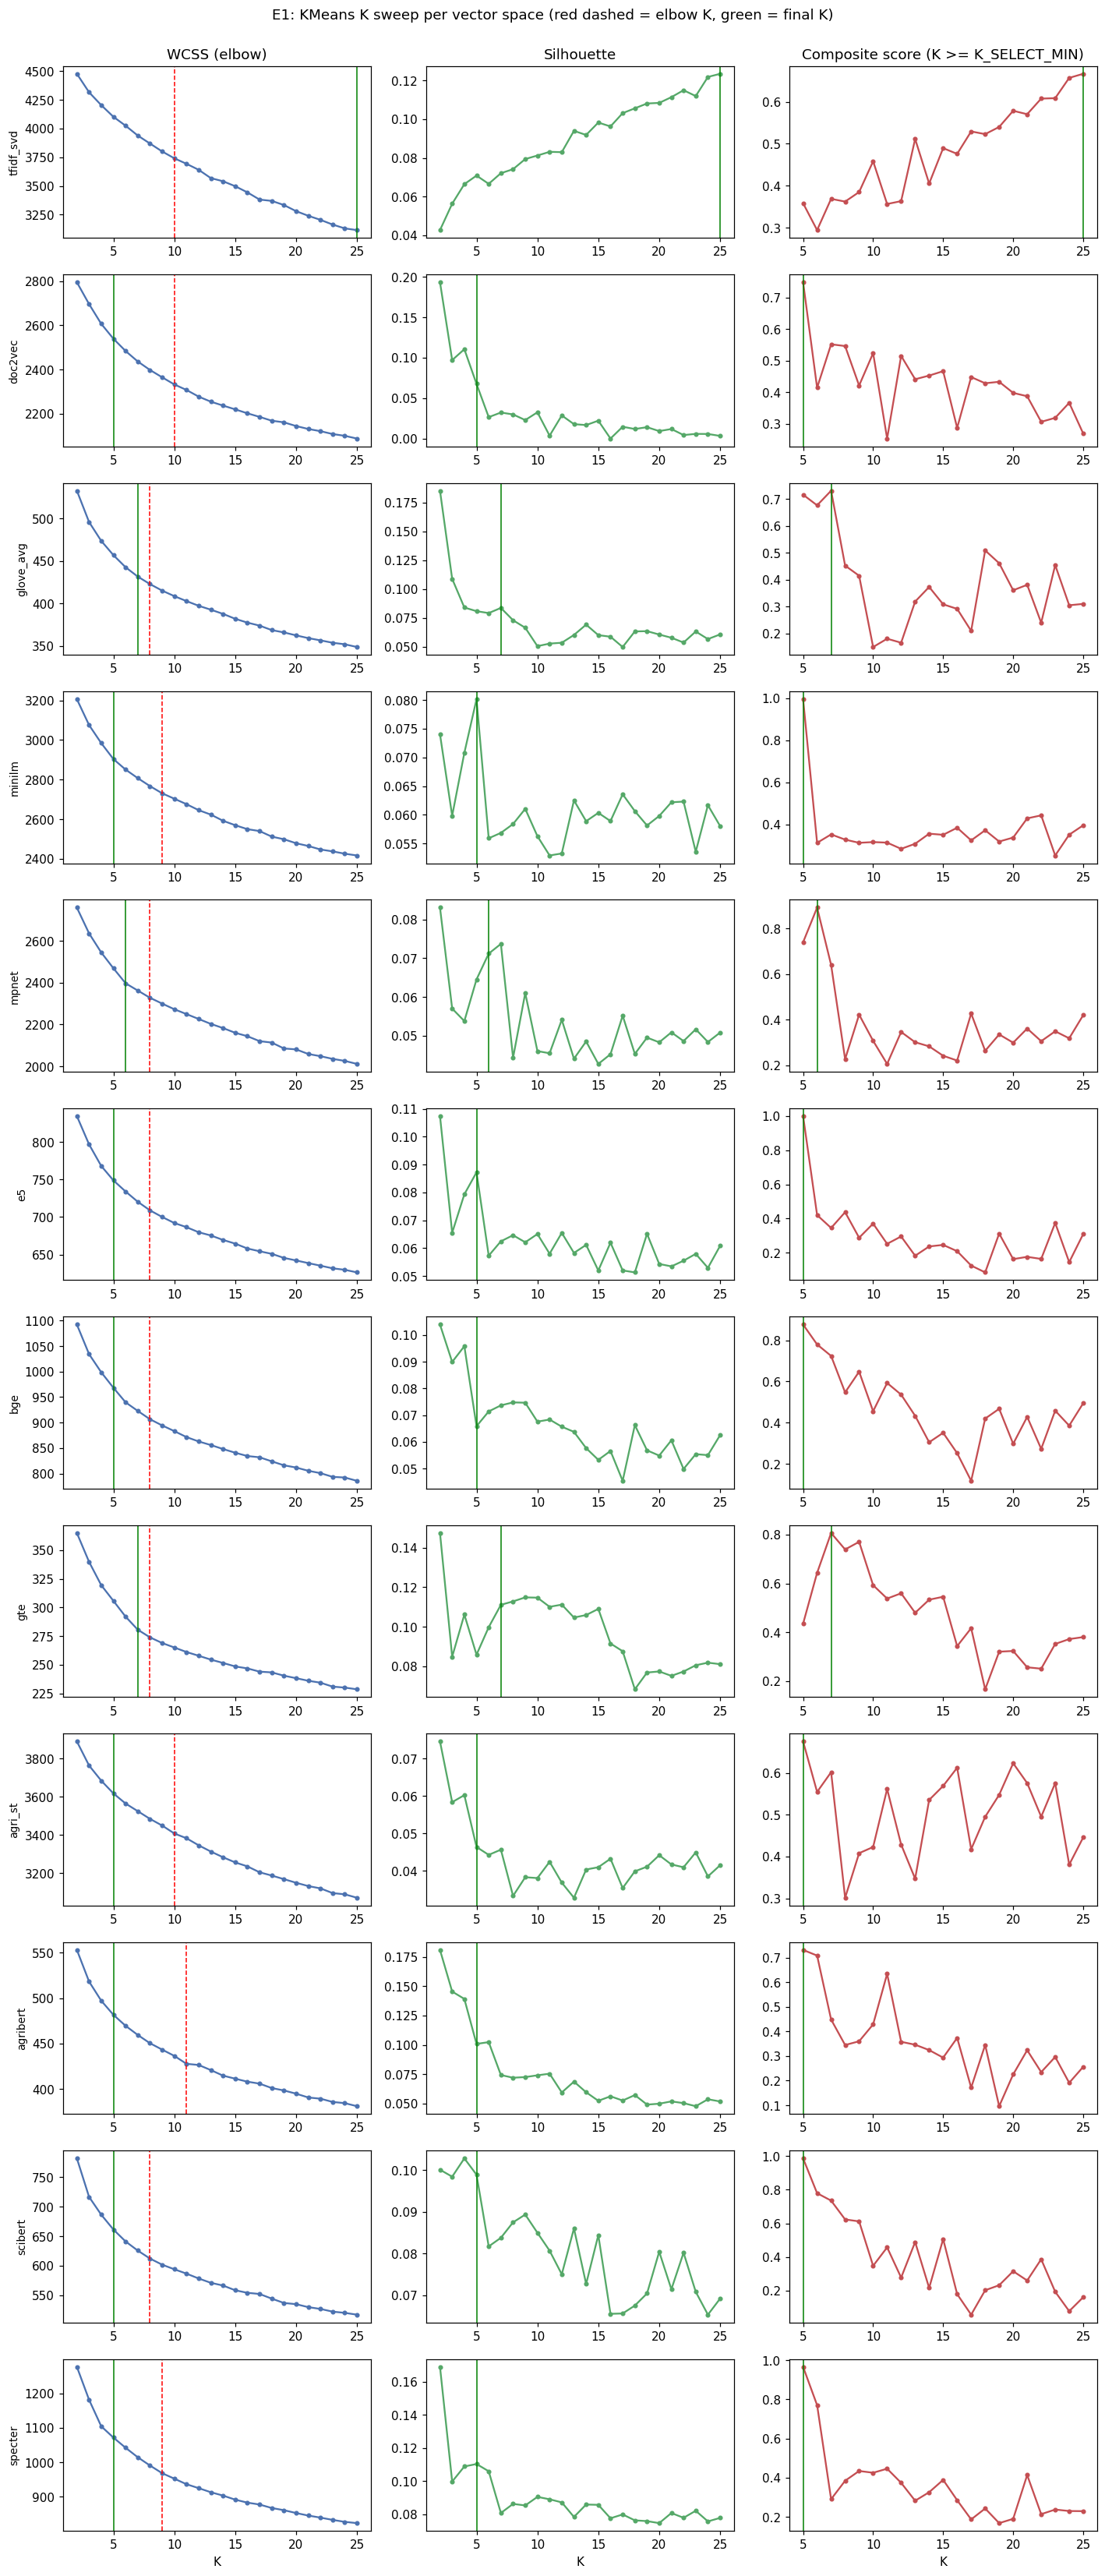

In [33]:
n_sp = len(EMBEDDINGS)
fig, axes = plt.subplots(n_sp, 3, figsize=(13, 2.5 * n_sp), squeeze=False)
for r, name in enumerate(EMBEDDINGS):
    sw, ch = E1_SWEEPS[name], E1_CHOICE[name]
    axes[r, 0].plot(sw["k"], sw["wcss"], "o-", ms=3, color="#4C72B0")
    axes[r, 0].axvline(ch["k_elbow"], color="red", ls="--", lw=1)
    axes[r, 0].axvline(ch["k_final"], color="green", lw=1)
    axes[r, 0].set_ylabel(name, fontsize=9)
    axes[r, 1].plot(sw["k"], sw["silhouette"], "o-", ms=3, color="#55A868")
    axes[r, 1].axvline(ch["k_final"], color="green", lw=1)
    comp = ch["composite_table"]
    axes[r, 2].plot(comp["k"], comp["composite"], "o-", ms=3, color="#C44E52")
    axes[r, 2].axvline(ch["k_final"], color="green", lw=1)
axes[0, 0].set_title("WCSS (elbow)"); axes[0, 1].set_title("Silhouette"); axes[0, 2].set_title("Composite score (K >= K_SELECT_MIN)")
for ax in axes[-1]:
    ax.set_xlabel("K")
fig.suptitle("E1: KMeans K sweep per vector space (red dashed = elbow K, green = final K)", y=1.0)
fig.tight_layout()
save_fig(fig, "E1", "E1_elbow_silhouette_composite", "Elbow, silhouette and composite curves for every vector space")

In [34]:
# How much does the K_SELECT_MIN constraint matter? Compare constrained and unconstrained choices.
display(e1_choice_df[["space", "k_final", "k_silhouette_unconstrained", "k_silhouette_constrained", "k_elbow", "elbow_clear", "elbow_agrees"]])
print("Spaces where the unconstrained silhouette picks K below K_SELECT_MIN:",
      int((e1_choice_df["k_silhouette_unconstrained"] < K_SELECT_MIN_EFFECTIVE).sum()), "of", len(e1_choice_df))
at_floor = e1_choice_df[e1_choice_df["k_final"] == K_SELECT_MIN_EFFECTIVE]
print(f"K_SELECT_MIN is BINDING (chosen K = {K_SELECT_MIN_EFFECTIVE}) in {len(at_floor)} of {len(e1_choice_df)} spaces: {list(at_floor['space'])}")
print("Where it binds, the composite score was still falling when the floor was reached, so the true optimum may be lower; the elbow K (column k_elbow) is the independent cross-check for those spaces.")

,space,k_final,k_silhouette_unconstrained,k_silhouette_constrained,k_elbow,elbow_clear,elbow_agrees
0,tfidf_svd,25,25,25,10,True,False
1,doc2vec,5,2,5,10,True,False
2,glove_avg,7,2,7,8,True,True
3,minilm,5,5,5,9,True,False
4,mpnet,6,2,7,8,True,True
5,e5,5,2,5,8,True,False
6,bge,5,2,8,8,True,False
7,gte,7,2,9,8,True,True
8,agri_st,5,2,5,10,True,False
9,agribert,5,2,6,11,True,False


Spaces where the unconstrained silhouette picks K below K_SELECT_MIN: 10 of 12
K_SELECT_MIN is BINDING (chosen K = 5) in 8 of 12 spaces: ['doc2vec', 'minilm', 'e5', 'bge', 'agri_st', 'agribert', 'scibert', 'specter']
Where it binds, the composite score was still falling when the floor was reached, so the true optimum may be lower; the elbow K (column k_elbow) is the independent cross-check for those spaces.


## Stage 7 — Experiment E2: UMAP dimensionality for transformer-based clustering
**Question:** transformer-based clustering first projects embeddings with UMAP. Which output dimensionality should be used? (BERTopic's default is 5; your earlier run used 10 and 50.) It is **tested, not assumed**.

**Fair metric:** silhouette *inside the UMAP space* is inflated by UMAP's compression (your earlier run: 0.047 raw → 0.439 UMAP-50), so it cannot be used. Instead the clusters found in each UMAP space (KMeans at that encoder's E1 K) are scored with **cosine silhouette in the original embedding space**, and **trustworthiness** reports how well local neighbourhoods survived.
`none` and `pca` rows are shown for reference; the dimension is chosen **among UMAP options only**, by the mean (over encoders) of the silhouette minus that encoder's average over dimensions (so encoders with naturally higher scores do not dominate).

In [35]:
UMAP_CACHE = {}   # (encoder, dims) -> reduced vectors
e2_rows = []
for enc in TRANSFORMER_SPACES:
    raw = EMBEDDINGS[enc]
    k_enc = E1_CHOICE[enc]["k_final"]
    options = [("none", None)] + [("pca", 50)] + [("umap", d) for d in UMAP_DIMS_TO_TEST]
    for method, dims in options:
        start = time.time()
        if method == "none":
            red = raw
        elif method == "pca":
            red = reduce_vectors(raw, "pca", dims)
        else:
            red = umap_reduce(raw, dims)
            UMAP_CACHE[(enc, dims)] = red
        lab = labels_for_k(red, "kmeans", k_enc)
        row = {"encoder": enc, "reduction": method, "dims": raw.shape[1] if dims is None else dims, "k": k_enc,
               "silhouette_in_reduced_space": safe_cluster_metrics(red, lab)["silhouette"],
               "silhouette_in_original_space": float(silhouette_score(raw, lab, metric="cosine", sample_size=min(1500, len(lab)), random_state=RANDOM_SEED))}
        if method != "none":
            row["trustworthiness"] = float(trustworthiness(raw, red, n_neighbors=10, metric="cosine"))
        e2_rows.append(row)
        print(f"done: {enc:7s} {method:5s} dims={row['dims']:<4} ({time.time() - start:.1f}s)")
e2_results = pd.DataFrame(e2_rows)
display(e2_results)
save_df(e2_results, "E2", "E2_umap_dimensionality", "Original-space silhouette and trustworthiness per encoder and reduction")

done: minilm  none  dims=384  (1.2s)
done: minilm  pca   dims=50   (1.6s)
done: minilm  umap  dims=5    (63.3s)
done: minilm  umap  dims=10   (12.1s)
done: minilm  umap  dims=20   (15.0s)
done: mpnet   none  dims=768  (3.5s)
done: mpnet   pca   dims=50   (2.2s)
done: mpnet   umap  dims=5    (11.6s)
done: mpnet   umap  dims=10   (12.4s)
done: mpnet   umap  dims=20   (15.4s)
done: e5      none  dims=768  (1.8s)
done: e5      pca   dims=50   (1.9s)
done: e5      umap  dims=5    (11.3s)
done: e5      umap  dims=10   (12.3s)
done: e5      umap  dims=20   (15.8s)
done: bge     none  dims=768  (2.0s)
done: bge     pca   dims=50   (1.8s)
done: bge     umap  dims=5    (11.6s)
done: bge     umap  dims=10   (12.5s)
done: bge     umap  dims=20   (15.6s)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))


done: gte     none  dims=768  (4.1s)
done: gte     pca   dims=50   (2.7s)
done: gte     umap  dims=5    (11.6s)
done: gte     umap  dims=10   (12.5s)
done: gte     umap  dims=20   (15.5s)
done: agri_st none  dims=768  (2.1s)
done: agri_st pca   dims=50   (2.0s)
done: agri_st umap  dims=5    (11.4s)
done: agri_st umap  dims=10   (12.3s)
done: agri_st umap  dims=20   (15.6s)
done: agribert none  dims=768  (2.8s)
done: agribert pca   dims=50   (2.4s)
done: agribert umap  dims=5    (11.6s)
done: agribert umap  dims=10   (12.4s)
done: agribert umap  dims=20   (15.7s)
done: scibert none  dims=768  (2.2s)
done: scibert pca   dims=50   (1.8s)
done: scibert umap  dims=5    (11.7s)
done: scibert umap  dims=10   (12.5s)
done: scibert umap  dims=20   (16.0s)
done: specter none  dims=768  (2.2s)
done: specter pca   dims=50   (2.3s)
done: specter umap  dims=5    (11.2s)
done: specter umap  dims=10   (12.6s)
done: specter umap  dims=20   (16.4s)


,encoder,reduction,dims,k,silhouette_in_reduced_space,silhouette_in_original_space,trustworthiness
0,minilm,none,384,5,0.080144,0.143999,NaN
1,minilm,pca,50,5,0.117893,0.143859,0.997679
2,minilm,umap,5,5,0.466257,0.062849,0.979869
3,minilm,umap,10,5,0.469232,0.063282,0.980140
4,minilm,umap,20,5,0.455863,0.064842,0.981033
5,mpnet,none,768,6,0.071187,0.127179,NaN
6,mpnet,pca,50,6,0.112932,0.126415,0.997835
7,mpnet,umap,5,6,0.498316,0.071408,0.973217
8,mpnet,umap,10,6,0.492876,0.063816,0.974353
9,mpnet,umap,20,6,0.492413,0.063300,0.974780


  [saved csv  ] experiment_outputs/07_E2_umap_projection/E2_umap_dimensionality.csv  (3.2 KB)


PosixPath('experiment_outputs/07_E2_umap_projection/E2_umap_dimensionality.csv')

,dims,mean_centred_silhouette,mean_original_silhouette,mean_trustworthiness
0,5,0.001682,0.135878,0.977551
1,10,-0.012223,0.121973,0.978327
2,20,0.010542,0.144738,0.978338


Chosen UMAP dimensionality: 20
  [saved csv  ] experiment_outputs/07_E2_umap_projection/E2_umap_dimension_choice.csv  (0.3 KB)
  [saved json ] experiment_outputs/07_E2_umap_projection/E2_chosen_umap_dim.json  (0.1 KB)
  [saved png  ] experiment_outputs/07_E2_umap_projection/E2_umap_dimension_plot.png  (79.7 KB)


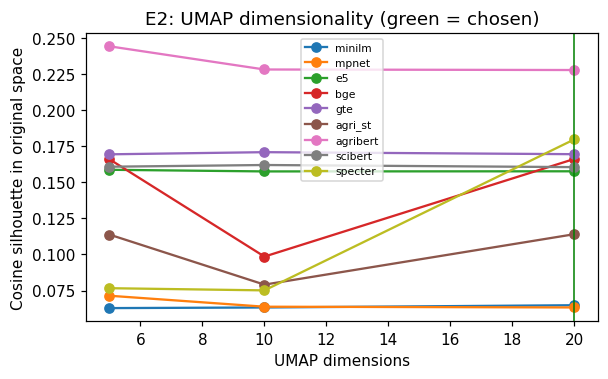

  [saved npy  ] experiment_outputs/07_E2_umap_projection/umap20_minilm.npy  (390.8 KB)
  [saved npy  ] experiment_outputs/07_E2_umap_projection/umap20_mpnet.npy  (390.8 KB)
  [saved npy  ] experiment_outputs/07_E2_umap_projection/umap20_e5.npy  (390.8 KB)
  [saved npy  ] experiment_outputs/07_E2_umap_projection/umap20_bge.npy  (390.8 KB)
  [saved npy  ] experiment_outputs/07_E2_umap_projection/umap20_gte.npy  (390.8 KB)
  [saved npy  ] experiment_outputs/07_E2_umap_projection/umap20_agri_st.npy  (390.8 KB)
  [saved npy  ] experiment_outputs/07_E2_umap_projection/umap20_agribert.npy  (390.8 KB)
  [saved npy  ] experiment_outputs/07_E2_umap_projection/umap20_scibert.npy  (390.8 KB)
  [saved npy  ] experiment_outputs/07_E2_umap_projection/umap20_specter.npy  (390.8 KB)
Registered spaces: ['tfidf_svd', 'doc2vec', 'glove_avg', 'minilm', 'mpnet', 'e5', 'bge', 'gte', 'agri_st', 'agribert', 'scibert', 'specter', 'minilm__umap', 'mpnet__umap', 'e5__umap', 'bge__umap', 'gte__umap', 'agri_st__uma

In [36]:
umap_rows = e2_results[e2_results["reduction"] == "umap"].copy()
umap_rows["centred_silhouette"] = umap_rows["silhouette_in_original_space"] - umap_rows.groupby("encoder")["silhouette_in_original_space"].transform("mean")
dim_scores = umap_rows.groupby("dims").agg(mean_centred_silhouette=("centred_silhouette", "mean"),
                                           mean_original_silhouette=("silhouette_in_original_space", "mean"),
                                           mean_trustworthiness=("trustworthiness", "mean")).reset_index()
display(dim_scores)
UMAP_DIM = int(dim_scores.loc[dim_scores["mean_centred_silhouette"].idxmax(), "dims"])
print("Chosen UMAP dimensionality:", UMAP_DIM)
save_df(dim_scores, "E2", "E2_umap_dimension_choice", "Mean centred original-space silhouette per UMAP dimensionality")
save_json({"UMAP_DIM": UMAP_DIM, "rule": "max mean (silhouette_in_original_space - encoder mean) among UMAP dims"}, "E2", "E2_chosen_umap_dim", "Chosen UMAP dimensionality")

fig, ax = plt.subplots(figsize=(6, 3.4))
for enc in TRANSFORMER_SPACES:
    sub = umap_rows[umap_rows["encoder"] == enc]
    ax.plot(sub["dims"], sub["silhouette_in_original_space"], "o-", label=enc)
ax.axvline(UMAP_DIM, color="green", lw=1)
ax.set_xlabel("UMAP dimensions"); ax.set_ylabel("Cosine silhouette in original space"); ax.set_title("E2: UMAP dimensionality (green = chosen)"); ax.legend(fontsize=7)
save_fig(fig, "E2", "E2_umap_dimension_plot", "Silhouette in original space vs UMAP dimensionality")

# Vector registry used by every later stage: raw spaces + UMAP spaces at the chosen dimensionality.
SPACE_VEC = dict(EMBEDDINGS)
for enc in TRANSFORMER_SPACES:
    SPACE_VEC[f"{enc}__umap"] = UMAP_CACHE[(enc, UMAP_DIM)]
    save_npy(SPACE_VEC[f"{enc}__umap"], "E2", f"umap{UMAP_DIM}_{enc}", f"UMAP-{UMAP_DIM} vectors of {enc}")
print("Registered spaces:", list(SPACE_VEC))

## Stage 8 — Experiment E3: full K sweeps for every configuration
Every configuration below is swept over `K_RANGE` (HDBSCAN over `min_cluster_size`), K is chosen with the rule of Stage 4.3, and the chosen labelling is stored.

| Pipeline | Vectors | Algorithms |
|---|---|---|
| `classical_features` | TF-IDF+SVD, Doc2Vec, GloVe-avg | KMeans, GMM, Ward |
| `transformer_raw` | 9 encoders (raw embeddings) | KMeans, GMM, Ward |
| `transformer_umap` (**BERTopic-style**) | 9 encoders → UMAP | KMeans, GMM, Ward, **HDBSCAN** |

HDBSCAN on *raw* 384–768-D embeddings is not included: your earlier run gave 2 clusters with 63% noise there (density estimation fails in high dimensions), while the UMAP version worked.
Total: 9 + 27 + 36 = **72 configurations** (69 if GloVe cannot be downloaded; fewer if a model fails to load).

In [37]:
CONFIGS = []
for s in CLASSICAL_AVAILABLE:
    for algo in ["kmeans", "gmm", "ward"]:
        CONFIGS.append({"name": f"{s} | {algo}", "family": "classical", "pipeline": "classical_features", "encoder": s,
                        "reduce": "none", "algo": algo, "space_key": s})
for enc in TRANSFORMER_SPACES:
    for algo in ["kmeans", "gmm", "ward"]:
        CONFIGS.append({"name": f"{enc} | {algo}", "family": "transformer", "pipeline": "transformer_raw", "encoder": enc,
                        "reduce": "none", "algo": algo, "space_key": enc})
    for algo in ["kmeans", "gmm", "ward", "hdbscan"]:
        CONFIGS.append({"name": f"{enc}+umap | {algo}", "family": "transformer", "pipeline": "transformer_umap", "encoder": enc,
                        "reduce": "umap", "algo": algo, "space_key": f"{enc}__umap"})
for c_ in CONFIGS:
    c_["group"] = ENCODER_GROUP.get(c_["encoder"], "classical")
print("Configurations:", len(CONFIGS))
display(pd.DataFrame(CONFIGS).groupby(["family", "pipeline", "algo"]).size().rename("n").reset_index())

Configurations: 72


,family,pipeline,algo,n
0,classical,classical_features,gmm,3
1,classical,classical_features,kmeans,3
2,classical,classical_features,ward,3
3,transformer,transformer_raw,gmm,9
4,transformer,transformer_raw,kmeans,9
5,transformer,transformer_raw,ward,9
6,transformer,transformer_umap,gmm,9
7,transformer,transformer_umap,hdbscan,9
8,transformer,transformer_umap,kmeans,9
9,transformer,transformer_umap,ward,9


In [38]:
def pick_hdbscan(sweep_h, k_select_min):
    """HDBSCAN picks its own number of clusters. Choose min_cluster_size by HDBSCAN's relative validity (DBCV approximation)
    among candidates with at least k_select_min clusters; ties -> lower noise."""
    cand = sweep_h[(sweep_h["n_clusters"] >= k_select_min) & sweep_h["relative_validity"].notna()]
    if cand.empty:
        cand = sweep_h.sort_values("n_clusters", ascending=False).head(1)
    else:
        cand = cand.sort_values(["relative_validity", "noise_ratio_before"], ascending=[False, True]).head(1)
    return int(cand.iloc[0]["min_cluster_size"])

GRID, SWEEP_TABLES, HDB_TABLES = {}, [], []
for cfg in CONFIGS:
    start = time.time()
    vec = SPACE_VEC[cfg["space_key"]]
    if cfg["algo"] == "hdbscan":
        rows, labs = [], {}
        for mcs in HDBSCAN_MIN_SIZES:
            lab, validity = hdbscan_labels(vec, mcs)
            fin = finalize_labels(vec, lab)
            n_cl = len(set(lab)) - (1 if -1 in lab else 0)
            rows.append({"config": cfg["name"], "min_cluster_size": mcs, "n_clusters": n_cl, "noise_ratio_before": float((lab == -1).mean()),
                         "relative_validity": validity, "silhouette_after_assignment": safe_cluster_metrics(vec, fin)["silhouette"]})
            labs[mcs] = lab
        sweep_h = pd.DataFrame(rows)
        HDB_TABLES.append(sweep_h)
        mcs_best = pick_hdbscan(sweep_h, K_SELECT_MIN_EFFECTIVE)
        raw_lab = labs[mcs_best]
        GRID[cfg["name"]] = {"cfg": cfg, "param": mcs_best, "k": int(len(set(raw_lab)) - (1 if -1 in raw_lab else 0)),
                             "noise_before": float((raw_lab == -1).mean()), "labels": finalize_labels(vec, raw_lab), "choice": {"min_cluster_size": mcs_best}}
    else:
        if cfg["reduce"] == "none" and cfg["algo"] == "kmeans":     # reuse E1 (identical computation)
            sw, labs, ch = E1_SWEEPS[cfg["space_key"]], E1_LABELS[cfg["space_key"]], E1_CHOICE[cfg["space_key"]]
        else:
            sw, labs = sweep_k(vec, cfg["algo"], K_RANGE, key=cfg["space_key"])
            ch = choose_k(sw, K_SELECT_MIN_EFFECTIVE)
        SWEEP_TABLES.append(sw.assign(config=cfg["name"], algo=cfg["algo"], space=cfg["space_key"], pipeline=cfg["pipeline"]))
        GRID[cfg["name"]] = {"cfg": cfg, "param": ch["k_final"], "k": ch["k_final"], "noise_before": 0.0,
                             "labels": np.asarray(labs[ch["k_final"]]), "choice": {k: v for k, v in ch.items() if k != "composite_table"}}
    print(f"done: {cfg['name']:28s} K = {GRID[cfg['name']]['k']:>2d}  ({time.time() - start:.1f}s)")

sweeps_all = pd.concat(SWEEP_TABLES, ignore_index=True)
save_df(sweeps_all, "E3", "E3_all_k_sweeps", "WCSS/silhouette/DB/CH for every K, every non-HDBSCAN configuration")
if HDB_TABLES:
    hdb_all = pd.concat(HDB_TABLES, ignore_index=True)
    display(hdb_all)
    save_df(hdb_all, "E3", "E3_hdbscan_sweeps", "HDBSCAN min_cluster_size sweep per encoder")

done: tfidf_svd | kmeans           K = 25  (0.0s)
done: tfidf_svd | gmm              K = 24  (16.6s)
done: tfidf_svd | ward             K = 25  (3.1s)
done: doc2vec | kmeans             K =  5  (0.0s)
done: doc2vec | gmm                K =  6  (18.3s)
done: doc2vec | ward               K =  5  (3.6s)
done: glove_avg | kmeans           K =  7  (0.0s)
done: glove_avg | gmm              K =  8  (14.4s)
done: glove_avg | ward             K =  5  (3.0s)
done: minilm | kmeans              K =  5  (0.0s)
done: minilm | gmm                 K =  5  (37.7s)
done: minilm | ward                K =  5  (5.6s)
done: minilm+umap | kmeans         K = 16  (6.5s)
done: minilm+umap | gmm            K = 21  (3.8s)
done: minilm+umap | ward           K = 16  (2.2s)
done: minilm+umap | hdbscan        K = 38  (1.5s)
done: mpnet | kmeans               K =  6  (0.0s)
done: mpnet | gmm                  K =  6  (110.1s)
done: mpnet | ward                 K =  5  (9.7s)
done: mpnet+umap | kmeans          K = 12  (

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered i

done: gte | gmm                    K =  8  (90.4s)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered i

done: gte | ward                   K =  7  (27.2s)
done: gte+umap | kmeans            K =  9  (5.7s)
done: gte+umap | gmm               K =  8  (5.1s)
done: gte+umap | ward              K =  9  (2.3s)
done: gte+umap | hdbscan           K = 59  (1.6s)
done: agri_st | kmeans             K =  5  (0.0s)
done: agri_st | gmm                K =  8  (77.9s)
done: agri_st | ward               K =  5  (9.2s)
done: agri_st+umap | kmeans        K =  5  (6.9s)
done: agri_st+umap | gmm           K = 20  (4.4s)
done: agri_st+umap | ward          K =  5  (2.3s)
done: agri_st+umap | hdbscan       K = 10  (2.4s)
done: agribert | kmeans            K =  5  (0.0s)
done: agribert | gmm               K =  5  (76.6s)
done: agribert | ward              K =  9  (10.0s)
done: agribert+umap | kmeans       K =  7  (5.6s)
done: agribert+umap | gmm          K =  5  (6.5s)
done: agribert+umap | ward         K =  5  (2.2s)
done: agribert+umap | hdbscan      K = 11  (1.7s)
done: scibert | kmeans             K =  5  (0.

,config,min_cluster_size,n_clusters,noise_ratio_before,relative_validity,silhouette_after_assignment
0,minilm+umap | hdbscan,10,120,0.2000,0.334865,0.539338
1,minilm+umap | hdbscan,15,86,0.2122,0.304106,0.529231
2,minilm+umap | hdbscan,20,63,0.2196,0.247897,0.551167
3,minilm+umap | hdbscan,30,38,0.2152,0.374580,0.512608
4,minilm+umap | hdbscan,50,16,0.2312,0.256099,0.487246
5,mpnet+umap | hdbscan,10,115,0.2176,0.268206,0.471900
6,mpnet+umap | hdbscan,15,81,0.2302,0.258708,0.470088
7,mpnet+umap | hdbscan,20,53,0.2552,0.302869,0.460137
8,mpnet+umap | hdbscan,30,17,0.1156,0.532202,0.411108
9,mpnet+umap | hdbscan,50,10,0.1092,0.675843,0.466635


  [saved csv  ] experiment_outputs/08_E3_full_k_sweeps/E3_hdbscan_sweeps.csv  (3.3 KB)


In [39]:
k_choice_df = pd.DataFrame([{"config": n, "pipeline": g["cfg"]["pipeline"], "algo": g["cfg"]["algo"], "chosen_k": g["k"], "noise_before_assignment": g["noise_before"],
                             **{k: v for k, v in g["choice"].items()}} for n, g in GRID.items()])
display(k_choice_df)
save_df(k_choice_df, "E3", "E3_chosen_k_per_config", "Chosen K, elbow K and cross-checks for every configuration")
elbow_sub = k_choice_df.dropna(subset=["k_elbow"])
print(f"Elbow agrees (within +-2) with chosen K in {int(elbow_sub['elbow_agrees'].sum())} of {len(elbow_sub)} sweeps; "
      f"a clear elbow (strength >= 0.05) exists in {int(elbow_sub['elbow_clear'].sum())} of {len(elbow_sub)} sweeps.")

,config,pipeline,algo,chosen_k,noise_before_assignment,k_final,k_elbow,elbow_strength,elbow_clear,elbow_agrees,k_silhouette_unconstrained,k_silhouette_constrained,min_cluster_size
0,tfidf_svd | kmeans,classical_features,kmeans,25,0.0000,25.0,10.0,0.193,True,False,25.0,25.0,NaN
1,tfidf_svd | gmm,classical_features,gmm,24,0.0000,24.0,9.0,0.223,True,False,25.0,25.0,NaN
2,tfidf_svd | ward,classical_features,ward,25,0.0000,25.0,9.0,0.169,True,False,25.0,25.0,NaN
3,doc2vec | kmeans,classical_features,kmeans,5,0.0000,5.0,10.0,0.306,True,False,2.0,5.0,NaN
4,doc2vec | gmm,classical_features,gmm,6,0.0000,6.0,10.0,0.301,True,False,2.0,6.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,specter | ward,transformer_raw,ward,6,0.0000,6.0,8.0,0.347,True,True,2.0,6.0,NaN
68,specter+umap | kmeans,transformer_umap,kmeans,23,0.0000,23.0,6.0,0.575,True,False,23.0,23.0,NaN
69,specter+umap | gmm,transformer_umap,gmm,25,0.0000,25.0,4.0,0.551,True,False,3.0,21.0,NaN
70,specter+umap | ward,transformer_umap,ward,24,0.0000,24.0,6.0,0.576,True,False,24.0,24.0,NaN


  [saved csv  ] experiment_outputs/08_E3_full_k_sweeps/E3_chosen_k_per_config.csv  (5.6 KB)
Elbow agrees (within +-2) with chosen K in 18 of 63 sweeps; a clear elbow (strength >= 0.05) exists in 63 of 63 sweeps.


  [saved png  ] experiment_outputs/08_E3_full_k_sweeps/E3_k_curves_kmeans.png  (279.3 KB)


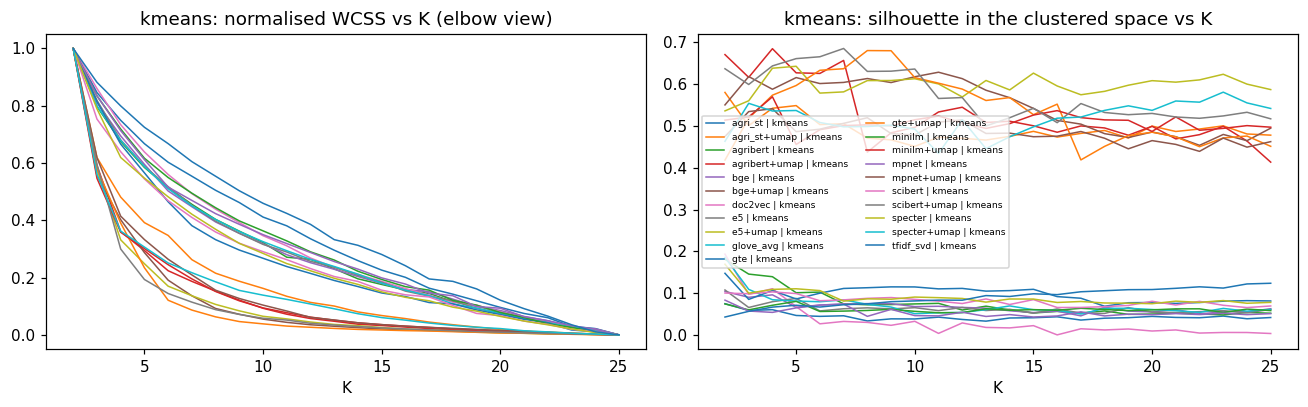

  [saved png  ] experiment_outputs/08_E3_full_k_sweeps/E3_k_curves_gmm.png  (273.7 KB)


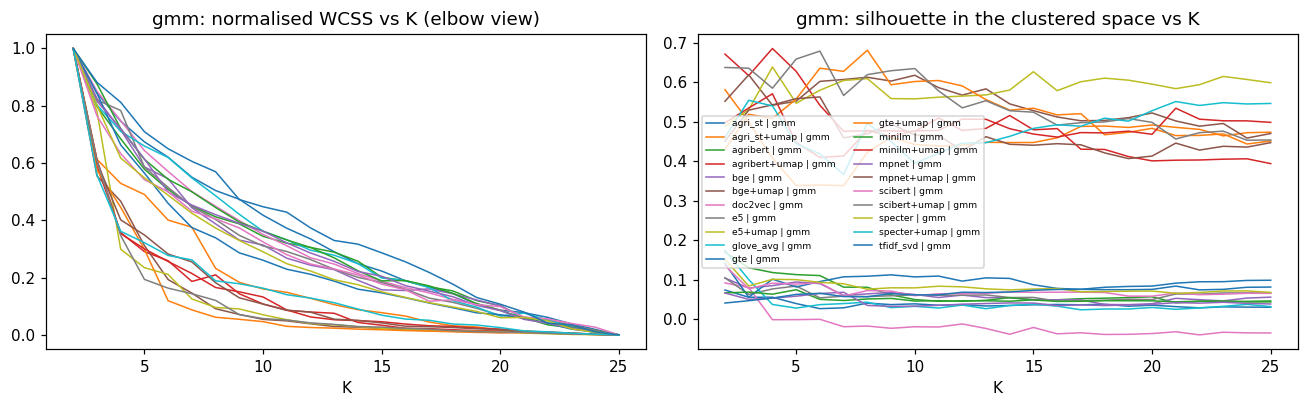

  [saved png  ] experiment_outputs/08_E3_full_k_sweeps/E3_k_curves_ward.png  (266.9 KB)


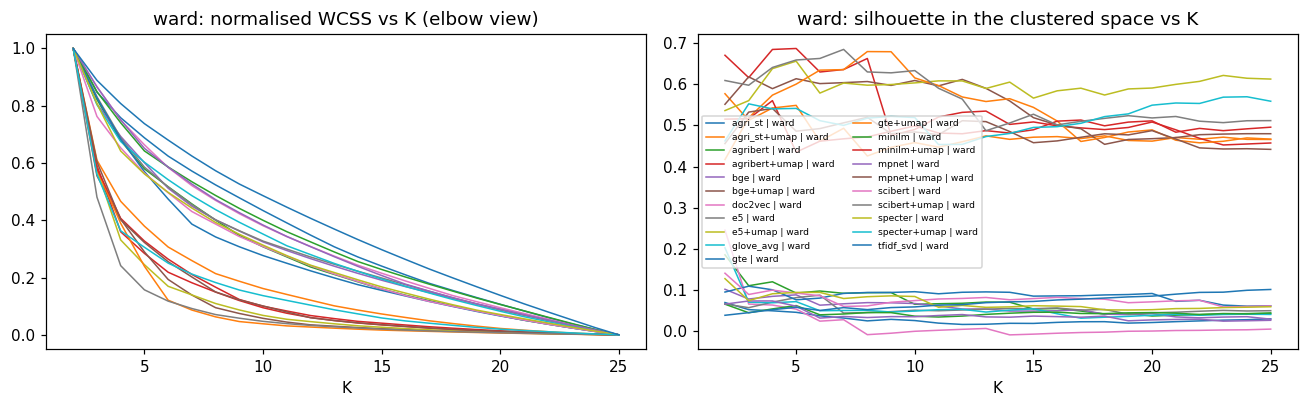

In [40]:
# One figure per algorithm: normalised WCSS curves (elbow view) and composite scores, one line per vector space.
for algo in ["kmeans", "gmm", "ward"]:
    sub = sweeps_all[sweeps_all["algo"] == algo]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    for cfg_name, g in sub.groupby("config"):
        w = g["wcss"].values
        axes[0].plot(g["k"], (w - w.min()) / (w.max() - w.min() + 1e-12), label=cfg_name, lw=1)
        axes[1].plot(g["k"], g["silhouette"], label=cfg_name, lw=1)
    axes[0].set_title(f"{algo}: normalised WCSS vs K (elbow view)"); axes[0].set_xlabel("K")
    axes[1].set_title(f"{algo}: silhouette in the clustered space vs K"); axes[1].set_xlabel("K")
    axes[1].legend(fontsize=6, ncol=2)
    fig.tight_layout()
    save_fig(fig, "E3", f"E3_k_curves_{algo}", f"WCSS and silhouette curves for all spaces, algorithm={algo}")

## Stage 9 — Experiment E4: Classical vs transformer-based clustering (leaderboard)
Every one of the 72 chosen clusterings is scored with the space-independent metrics from Stage 4.4:
**cross-space consensus** (z-scored), **NPMI coherence**, **stability** (ARI on 80% subsamples), **noise ratio**.
The final rank is the **mean of the four ranks** (equal weights, because there is no evidence for unequal weights).
Configurations whose largest cluster exceeds `DEGENERATE_SHARE` of the rows are reported but not ranked.

In [41]:
COH_INDEX = build_coherence_index(main_texts)
print("Coherence vocabulary size:", len(COH_INDEX["terms"]))

def stability_resampling(cfg, full_labels, param, vec, n_rep=N_RESAMPLES, frac=0.8):
    """Refit the clustering step on random subsets and compare with the full-data labels on the shared rows."""
    rng = np.random.default_rng(RANDOM_SEED)
    scores = []
    for r in range(n_rep):
        idx = np.sort(rng.choice(len(vec), size=max(10, int(frac * len(vec))), replace=False))
        sub = vec[idx]
        if cfg["algo"] == "hdbscan":
            lab, _ = hdbscan_labels(sub, param)
        else:
            lab = labels_for_k(sub, cfg["algo"], param, seed=100 + r)
        scores.append(adjusted_rand_score(full_labels[idx], finalize_labels(sub, lab)))
    return float(np.mean(scores)), float(np.std(scores))

records, sil_matrix = [], {}
for name, g in GRID.items():
    cfg, labels = g["cfg"], g["labels"]
    start = time.time()
    own_vec = SPACE_VEC[cfg["space_key"]]
    cross = cross_space_silhouettes(labels, EMBEDDINGS, exclude=(cfg["encoder"],))
    sil_matrix[name] = cross
    stab_mean, stab_std = stability_resampling(cfg, labels, g["param"], own_vec)
    records.append({"config": name, "family": cfg["family"], "pipeline": cfg["pipeline"], "encoder": cfg["encoder"], "encoder_group": cfg["group"], "algo": cfg["algo"],
                    "k": g["k"], "noise_before_assignment": g["noise_before"], "max_cluster_share": max_cluster_share(labels),
                    "silhouette_own_space": safe_cluster_metrics(own_vec, labels)["silhouette"],
                    "consensus_raw": float(np.nanmean(list(cross.values()))),
                    "npmi_coherence": npmi_coherence(labels, COH_INDEX),
                    "stability_ari": stab_mean, "stability_ari_std": stab_std})
    print(f"scored: {name:28s} ({time.time() - start:.1f}s)")

leader = pd.DataFrame(records)
S = pd.DataFrame(sil_matrix).T                               # rows = configs, columns = reference spaces
Z = (S - S.mean(axis=0, skipna=True)) / (S.std(axis=0, skipna=True) + 1e-12)
leader["consensus_z"] = Z.mean(axis=1, skipna=True).reindex(leader["config"]).values
save_df(S.reset_index().rename(columns={"index": "config"}), "E4", "E4_cross_space_silhouette_matrix", "Cosine silhouette of every clustering in every other reference space")

Coherence vocabulary size: 1121
scored: tfidf_svd | kmeans           (2.7s)
scored: tfidf_svd | gmm              (2.3s)
scored: tfidf_svd | ward             (4.4s)
scored: doc2vec | kmeans             (1.5s)
scored: doc2vec | gmm                (1.4s)
scored: doc2vec | ward               (3.4s)
scored: glove_avg | kmeans           (1.6s)
scored: glove_avg | gmm              (2.1s)
scored: glove_avg | ward             (4.2s)
scored: minilm | kmeans              (3.2s)
scored: minilm | gmm                 (1.8s)
scored: minilm | ward                (7.5s)
scored: minilm+umap | kmeans         (1.1s)
scored: minilm+umap | gmm            (1.0s)
scored: minilm+umap | ward           (2.2s)
scored: minilm+umap | hdbscan        (1.1s)
scored: mpnet | kmeans               (7.4s)
scored: mpnet | gmm                  (4.1s)
scored: mpnet | ward                 (11.9s)
scored: mpnet+umap | kmeans          (1.0s)
scored: mpnet+umap | gmm             (0.7s)
scored: mpnet+umap | ward            (2.2s)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))


scored: gte | kmeans                 (7.0s)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))


scored: gte | gmm                    (5.5s)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_unsupervised.py:386: RuntimeWarning: overflow encountered in scalar multiply
  else extra_disp * (n_samples - n_labels) / (intra_disp * (n_labels - 1.0))


scored: gte | ward                   (12.0s)
scored: gte+umap | kmeans            (1.3s)
scored: gte+umap | gmm               (0.8s)
scored: gte+umap | ward              (2.1s)
scored: gte+umap | hdbscan           (1.1s)
scored: agri_st | kmeans             (6.0s)
scored: agri_st | gmm                (9.3s)
scored: agri_st | ward               (11.9s)
scored: agri_st+umap | kmeans        (0.7s)
scored: agri_st+umap | gmm           (1.0s)
scored: agri_st+umap | ward          (2.1s)
scored: agri_st+umap | hdbscan       (1.1s)
scored: agribert | kmeans            (7.1s)
scored: agribert | gmm               (4.5s)
scored: agribert | ward              (11.7s)
scored: agribert+umap | kmeans       (0.8s)
scored: agribert+umap | gmm          (0.7s)
scored: agribert+umap | ward         (2.3s)
scored: agribert+umap | hdbscan      (1.9s)
scored: scibert | kmeans             (5.4s)
scored: scibert | gmm                (3.6s)
scored: scibert | ward               (11.8s)
scored: scibert+umap | kmean

PosixPath('experiment_outputs/09_E4_classical_vs_transformer/E4_cross_space_silhouette_matrix.csv')

In [42]:
leader["degenerate"] = leader["max_cluster_share"] > DEGENERATE_SHARE
eligible = ~leader["degenerate"]
metric_dirs = {"consensus_z": False, "npmi_coherence": False, "stability_ari": False, "noise_before_assignment": True}   # ascending?
for m, asc in metric_dirs.items():
    leader["rank_" + m] = np.nan
    leader.loc[eligible, "rank_" + m] = leader.loc[eligible, m].rank(ascending=asc, method="average")
leader["mean_rank"] = leader[["rank_" + m for m in metric_dirs]].mean(axis=1, skipna=False)
leader = leader.sort_values(["mean_rank", "consensus_z"], ascending=[True, False], na_position="last").reset_index(drop=True)
if "position" in leader.columns:          # makes the cell safe to re-run
    leader = leader.drop(columns=["position"])
leader.insert(0, "position", np.arange(1, len(leader) + 1))
display(leader[["position", "config", "pipeline", "k", "consensus_z", "npmi_coherence", "stability_ari", "noise_before_assignment",
                "max_cluster_share", "degenerate", "mean_rank"]])
save_df(leader, "E4", "E4_leaderboard_all_configs", "Full leaderboard: 44 configurations, all metrics and ranks")
print("Degenerate configurations (not ranked):", int(leader["degenerate"].sum()))

,position,config,pipeline,k,consensus_z,npmi_coherence,stability_ari,noise_before_assignment,max_cluster_share,degenerate,mean_rank
0,1,minilm | kmeans,transformer_raw,5,1.356781,0.185617,0.990278,0.000,0.4500,False,19.625
1,2,e5+umap | ward,transformer_umap,25,0.133670,0.239091,0.980495,0.000,0.0878,False,20.625
2,3,e5+umap | kmeans,transformer_umap,23,0.245405,0.247741,0.928155,0.000,0.0826,False,20.875
3,4,specter | kmeans,transformer_raw,5,0.682932,0.220544,0.913954,0.000,0.3612,False,21.875
4,5,mpnet+umap | kmeans,transformer_umap,12,-0.058819,0.223680,0.984708,0.000,0.2088,False,22.875
...,...,...,...,...,...,...,...,...,...,...,...
67,68,scibert+umap | hdbscan,transformer_umap,69,-2.446132,0.198695,0.824145,0.195,0.0978,False,51.250
68,69,doc2vec | gmm,classical_features,6,-1.102191,0.110449,0.689385,0.000,0.2552,False,51.875
69,70,mpnet | ward,transformer_raw,5,0.902050,0.136488,0.677351,0.000,0.5060,True,NaN
70,71,minilm | ward,transformer_raw,5,0.810021,0.120814,0.663112,0.000,0.5144,True,NaN


  [saved csv  ] experiment_outputs/09_E4_classical_vs_transformer/E4_leaderboard_all_configs.csv  (16.6 KB)
Degenerate configurations (not ranked): 3


In [43]:
ranked = leader[~leader["degenerate"] & leader["mean_rank"].notna()].copy()
assert len(ranked) > 0, "No non-degenerate configuration found - inspect E4_leaderboard_all_configs."
BEST_OVERALL = ranked.iloc[0]
BEST_TRANSFORMER = ranked[ranked["family"] == "transformer"].iloc[0]
BEST_CLASSICAL = ranked[ranked["family"] == "classical"].iloc[0]
_dom = ranked[ranked["encoder_group"].isin(["agriculture", "science"])]
BEST_DOMAIN = _dom.iloc[0] if len(_dom) else BEST_TRANSFORMER           # best agriculture- or science-trained encoder
_gen = ranked[ranked["encoder_group"] == "general"]
BEST_GENERAL = _gen.iloc[0] if len(_gen) else BEST_TRANSFORMER
_req = ranked[ranked["encoder"].isin(DOMAIN_COMPARISON_SET)]
BEST_REQUESTED = _req.iloc[0] if len(_req) else BEST_TRANSFORMER        # best of the five models you listed
winners = pd.DataFrame([BEST_OVERALL, BEST_TRANSFORMER, BEST_CLASSICAL, BEST_DOMAIN, BEST_GENERAL, BEST_REQUESTED],
                       index=["best_overall", "best_transformer", "best_classical", "best_domain_trained", "best_general", "best_of_requested_five"]).reset_index().rename(columns={"index": "role"})
display(winners[["role", "config", "pipeline", "k", "consensus_z", "npmi_coherence", "stability_ari", "noise_before_assignment", "mean_rank"]])
save_df(winners, "E4", "E4_winners", "Best overall / transformer / classical / domain-trained / general / best of the requested five")
print("BEST OVERALL         :", BEST_OVERALL["config"], "| K =", BEST_OVERALL["k"])
print("BEST TRANSFORMER     :", BEST_TRANSFORMER["config"], "| K =", BEST_TRANSFORMER["k"])
print("BEST CLASSICAL       :", BEST_CLASSICAL["config"], "| K =", BEST_CLASSICAL["k"])
print("BEST DOMAIN-TRAINED  :", BEST_DOMAIN["config"], "| K =", BEST_DOMAIN["k"])
print("BEST GENERAL         :", BEST_GENERAL["config"], "| K =", BEST_GENERAL["k"])
print("BEST OF REQUESTED 5  :", BEST_REQUESTED["config"], "| K =", BEST_REQUESTED["k"])

,role,config,pipeline,k,consensus_z,npmi_coherence,stability_ari,noise_before_assignment,mean_rank
0,best_overall,minilm | kmeans,transformer_raw,5,1.356781,0.185617,0.990278,0.0,19.625
1,best_transformer,minilm | kmeans,transformer_raw,5,1.356781,0.185617,0.990278,0.0,19.625
2,best_classical,glove_avg | kmeans,classical_features,7,-0.593670,0.196842,0.930474,0.0,32.625
3,best_domain_trained,specter | kmeans,transformer_raw,5,0.682932,0.220544,0.913954,0.0,21.875
4,best_general,minilm | kmeans,transformer_raw,5,1.356781,0.185617,0.990278,0.0,19.625
5,best_of_requested_five,specter | kmeans,transformer_raw,5,0.682932,0.220544,0.913954,0.0,21.875


  [saved csv  ] experiment_outputs/09_E4_classical_vs_transformer/E4_winners.csv  (1.8 KB)
BEST OVERALL         : minilm | kmeans | K = 5
BEST TRANSFORMER     : minilm | kmeans | K = 5
BEST CLASSICAL       : glove_avg | kmeans | K = 7
BEST DOMAIN-TRAINED  : specter | kmeans | K = 5
BEST GENERAL         : minilm | kmeans | K = 5
BEST OF REQUESTED 5  : specter | kmeans | K = 5


### 9.1 Classical vs transformer — head-to-head
Three views: (1) by family, (2) by pipeline, (3) **paired by algorithm** (best classical-feature config vs best transformer config for the same algorithm: KMeans, GMM, Ward).

In [44]:
metrics_cols = ["consensus_z", "npmi_coherence", "stability_ari", "noise_before_assignment", "max_cluster_share", "k", "mean_rank"]
by_family = ranked.groupby("family")[metrics_cols].agg(["mean", "max"]).round(3)
by_pipeline = ranked.groupby("pipeline")[metrics_cols].agg(["mean", "max"]).round(3)
print("By family (ranked, non-degenerate configurations):"); display(by_family)
print("By pipeline:"); display(by_pipeline)

paired = []
for algo in ["kmeans", "gmm", "ward"]:
    for fam in ["classical", "transformer"]:
        sub = ranked[(ranked["algo"] == algo) & (ranked["family"] == fam)]
        if len(sub):
            best = sub.sort_values("mean_rank").iloc[0]
            paired.append({"algorithm": algo, "family": fam, "best_config": best["config"], "k": best["k"], "consensus_z": best["consensus_z"],
                           "npmi": best["npmi_coherence"], "stability": best["stability_ari"], "mean_rank": best["mean_rank"]})
paired_df = pd.DataFrame(paired)
print("Paired by algorithm (best of each family):"); display(paired_df)
hdb = ranked[ranked["algo"] == "hdbscan"]
print("HDBSCAN (transformer-only, UMAP):"); display(hdb[["config", "k", "consensus_z", "npmi_coherence", "stability_ari", "noise_before_assignment", "mean_rank"]])
save_df(by_family.reset_index(), "E4", "E4_by_family", "Metric means/maxima by family")
save_df(by_pipeline.reset_index(), "E4", "E4_by_pipeline", "Metric means/maxima by pipeline")
save_df(paired_df, "E4", "E4_paired_by_algorithm", "Best classical vs best transformer for each algorithm")

By family (ranked, non-degenerate configurations):


consensus_z        npmi_coherence        stability_ari        \
                   mean    max           mean    max          mean   max   
family                                                                     
classical        -0.980  0.006          0.159  0.207         0.644  0.93   
transformer       0.111  1.441          0.178  0.248         0.861  1.00   

            noise_before_assignment        max_cluster_share              k  \
                               mean    max              mean    max    mean   
family                                                                        
classical                     0.000  0.000             0.239  0.482  13.125   
transformer                   0.022  0.239             0.291  0.494  12.885   

                mean_rank          
            max      mean     max  
family                             
classical    25    46.719  51.875  
transformer  69    33.463  51.250

By pipeline:


consensus_z        npmi_coherence        stability_ari  \
                          mean    max           mean    max          mean   
pipeline                                                                    
classical_features      -0.980  0.006          0.159  0.207         0.644   
transformer_raw          0.514  1.357          0.154  0.221         0.809   
transformer_umap        -0.169  1.441          0.195  0.248         0.897   

                         noise_before_assignment        max_cluster_share  \
                     max                    mean    max              mean   
pipeline                                                                    
classical_features  0.93                   0.000  0.000             0.239   
transformer_raw     0.99                   0.000  0.000             0.360   
transformer_umap    1.00                   0.038  0.239             0.242   

                                k     mean_rank          
                      max    mean max      mean     max  
pipeline                                                 
classical_features  0.482  13.125  25    46.719  51.875  
transformer_raw     0.494   5.680   9    34.725  49.875  
transformer_umap    0.487  17.889  69    32.587  51.250

Paired by algorithm (best of each family):


,algorithm,family,best_config,k,consensus_z,npmi,stability,mean_rank
0,kmeans,classical,glove_avg | kmeans,7,-0.593670,0.196842,0.930474,32.625
1,kmeans,transformer,minilm | kmeans,5,1.356781,0.185617,0.990278,19.625
2,gmm,classical,tfidf_svd | gmm,24,-1.265156,0.183453,0.499648,49.625
3,gmm,transformer,bge+umap | gmm,10,0.157042,0.218651,0.955176,23.875
4,ward,classical,tfidf_svd | ward,25,-1.195039,0.207262,0.464808,43.875
5,ward,transformer,e5+umap | ward,25,0.133670,0.239091,0.980495,20.625


HDBSCAN (transformer-only, UMAP):


,config,k,consensus_z,npmi_coherence,stability_ari,noise_before_assignment,mean_rank
22,agribert+umap | hdbscan,11,0.646664,0.195347,0.979485,0.0390,30.00
33,mpnet+umap | hdbscan,10,0.995465,0.203623,0.892470,0.1092,33.25
34,bge+umap | hdbscan,27,-0.417402,0.243761,0.968336,0.1468,33.25
36,e5+umap | hdbscan,26,0.007291,0.241543,0.907759,0.0738,34.00
41,agri_st+umap | hdbscan,10,0.413328,0.136630,0.991696,0.1386,36.25
52,specter+umap | hdbscan,37,-1.152028,0.210920,0.896860,0.1958,43.75
57,minilm+umap | hdbscan,38,-0.831428,0.216285,0.718316,0.2152,47.50
66,gte+umap | hdbscan,59,-0.875993,0.227052,0.380378,0.2394,50.50
67,scibert+umap | hdbscan,69,-2.446132,0.198695,0.824145,0.1950,51.25


  [saved csv  ] experiment_outputs/09_E4_classical_vs_transformer/E4_by_family.csv  (0.4 KB)
  [saved csv  ] experiment_outputs/09_E4_classical_vs_transformer/E4_by_pipeline.csv  (0.5 KB)
  [saved csv  ] experiment_outputs/09_E4_classical_vs_transformer/E4_paired_by_algorithm.csv  (0.7 KB)


PosixPath('experiment_outputs/09_E4_classical_vs_transformer/E4_paired_by_algorithm.csv')

  [saved png  ] experiment_outputs/09_E4_classical_vs_transformer/E4_classical_vs_transformer_scatter.png  (143.8 KB)


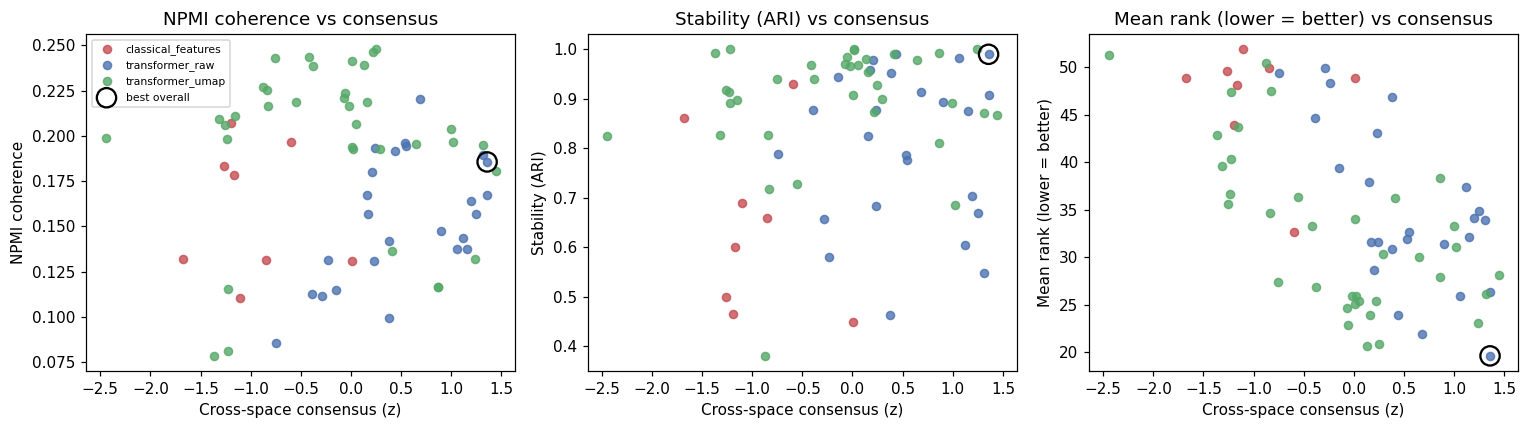

  [saved png  ] experiment_outputs/09_E4_classical_vs_transformer/E4_top15_bar.png  (70.5 KB)


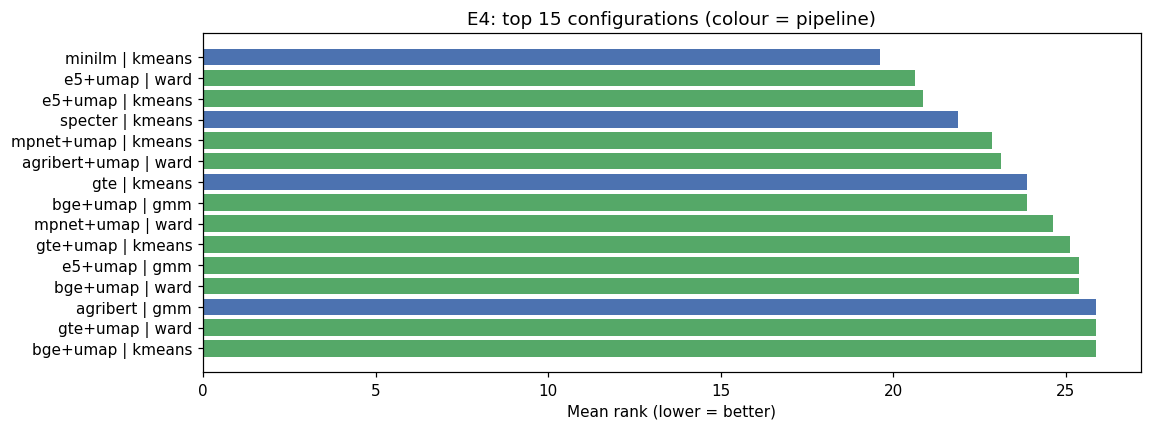

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = {"classical_features": "#C44E52", "transformer_raw": "#4C72B0", "transformer_umap": "#55A868"}
for ax, (ycol, title) in zip(axes, [("npmi_coherence", "NPMI coherence"), ("stability_ari", "Stability (ARI)"), ("mean_rank", "Mean rank (lower = better)")]):
    for pipe, g in ranked.groupby("pipeline"):
        ax.scatter(g["consensus_z"], g[ycol], label=pipe, c=colors.get(pipe, "grey"), s=28, alpha=0.8)
    ax.scatter([BEST_OVERALL["consensus_z"]], [BEST_OVERALL[ycol]], s=160, facecolors="none", edgecolors="black", linewidths=1.5, label="best overall")
    ax.set_xlabel("Cross-space consensus (z)"); ax.set_ylabel(title); ax.set_title(title + " vs consensus")
axes[0].legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "E4", "E4_classical_vs_transformer_scatter", "Scatter of all ranked configurations by pipeline")

fig, ax = plt.subplots(figsize=(11, 4))
top = ranked.head(15).iloc[::-1]
ax.barh(top["config"], top["mean_rank"], color=[colors.get(p, "grey") for p in top["pipeline"]])
ax.set_xlabel("Mean rank (lower = better)"); ax.set_title("E4: top 15 configurations (colour = pipeline)")
save_fig(fig, "E4", "E4_top15_bar", "Top 15 configurations by mean rank")

In [46]:
# Sensitivity: does the winner change if one metric is dropped or the rank method changes?
sens = []
metric_list = list(metric_dirs)
for dropped in [None] + metric_list:
    use = [m for m in metric_list if m != dropped]
    mean_rank_alt = ranked[["rank_" + m for m in use]].mean(axis=1)
    best_alt = ranked.loc[mean_rank_alt.idxmin(), "config"]
    sens.append({"dropped_metric": dropped or "none (full ranking)", "winner": best_alt})
for m in metric_list:
    best_single = ranked.sort_values("rank_" + m).iloc[0]["config"]
    sens.append({"dropped_metric": f"ONLY {m}", "winner": best_single})
sens_df = pd.DataFrame(sens)
display(sens_df)
save_df(sens_df, "E4", "E4_winner_sensitivity", "Winner under alternative metric subsets")

,dropped_metric,winner
0,none (full ranking),minilm | kmeans
1,consensus_z,e5+umap | ward
2,npmi_coherence,agribert+umap | ward
3,stability_ari,e5+umap | kmeans
4,noise_before_assignment,minilm | kmeans
5,ONLY consensus_z,agribert+umap | gmm
6,ONLY npmi_coherence,e5+umap | kmeans
7,ONLY stability_ari,agribert+umap | ward
8,ONLY noise_before_assignment,minilm | kmeans


  [saved csv  ] experiment_outputs/09_E4_classical_vs_transformer/E4_winner_sensitivity.csv  (0.3 KB)


PosixPath('experiment_outputs/09_E4_classical_vs_transformer/E4_winner_sensitivity.csv')

## Stage 10 — Experiment E10: domain-trained vs general-purpose transformers
**Question:** do transformers trained on agricultural (or scientific) text cluster these farmer queries better than general-purpose ones?

**The five requested models and what each really is** (so conclusions are not over-read):

| Key | Model | Trained on | Role in the study |
|---|---|---|---|
| `agri_st` | `recobo/agri-sentence-transformer` | Sentence-embedding model (512-d) built on the agriculture BERT below | **Agriculture-trained, sentence-level** |
| `agribert` | `recobo/agriculture-bert-uncased` | BERT further pre-trained *from SciBERT* on 6.5 M agricultural paragraphs; masked-language-model only | **Agriculture-trained, word-level** |
| `scibert` | `allenai/scibert_scivocab_uncased` | Scientific papers (masked-language-model only) | Science-trained, word-level |
| `specter` | `allenai/specter` | Scientific paper title + abstract, citation-based contrastive training | Science-trained, document-level |
| `mpnet` | `sentence-transformers/all-mpnet-base-v2` | 1 B+ general sentence pairs (the "SBERT" you listed) | **General-purpose reference** |

Note on "AgriBERT": the IJCAI-2022 AgriBERT paper describes a different model; no public Hugging Face weights for it could be confirmed, so the openly available agriculture BERT (`recobo/agriculture-bert-uncased`) is used and named `agribert`.

**Built-in ablation chain:** SciBERT → AgriBERT (adds *agricultural pre-training*) → Agri-Sentence-Transformer (adds *sentence-level training*). Comparing consecutive links isolates what each ingredient contributes.

The four earlier general encoders (`minilm`, `e5`, `bge`, `gte`) stay in the study as additional references.

**Fairness:** all 9 encoders receive the *identical* Query + Response text and go through the identical 7 pipelines (3 raw + 4 UMAP-based), the identical K rule and the identical ranking (Stage 9). Pooling follows each model's training: mean pooling for the word-level BERTs (SBERT paper: mean > CLS for non-fine-tuned BERT), CLS for SPECTER (as in the SPECTER paper), the saved config for sentence-transformers models.

In [47]:
S_COL_MEAN = S.mean(axis=0)     # per-reference-space statistics used to z-score every new clustering
S_COL_STD = S.std(axis=0)

enc_rows = []
for enc in TRANSFORMER_SPACES:
    sub_e = ranked[ranked["encoder"] == enc]
    if sub_e.empty:
        continue
    best = sub_e.iloc[0]
    km = ranked[ranked["config"] == f"{enc} | kmeans"]
    enc_rows.append({"encoder": enc, "group": ENCODER_GROUP[enc], "requested_domain_set": enc in DOMAIN_COMPARISON_SET,
                     "best_config": best["config"], "k": int(best["k"]), "consensus_z": best["consensus_z"], "npmi": best["npmi_coherence"],
                     "stability_ari": best["stability_ari"], "best_mean_rank": best["mean_rank"],
                     "avg_mean_rank_all_pipelines": sub_e["mean_rank"].mean(), "n_ranked_pipelines": len(sub_e),
                     "kmeans_raw_consensus_z": km["consensus_z"].iloc[0] if len(km) else np.nan,
                     "kmeans_raw_npmi": km["npmi_coherence"].iloc[0] if len(km) else np.nan,
                     "random_pair_cosine": float(checks_df.loc[checks_df["space"] == enc, "random_pair_cosine_mean"].iloc[0])})
per_encoder = pd.DataFrame(enc_rows).sort_values("best_mean_rank").reset_index(drop=True)
display(per_encoder)
save_df(per_encoder, "E10", "E10_per_encoder_summary", "Best pipeline and like-for-like KMeans metrics for every transformer encoder")

by_group = ranked.groupby("encoder_group")[["consensus_z", "npmi_coherence", "stability_ari", "mean_rank"]].agg(["mean", "max"]).round(3)
print("By encoder group (all ranked pipelines):")
display(by_group)
save_df(by_group.reset_index(), "E10", "E10_by_group", "Mean and best metrics per encoder group")

,encoder,group,requested_domain_set,best_config,k,consensus_z,npmi,stability_ari,best_mean_rank,avg_mean_rank_all_pipelines,n_ranked_pipelines,kmeans_raw_consensus_z,kmeans_raw_npmi,random_pair_cosine
0,minilm,general,False,minilm | kmeans,5,1.356781,0.185617,0.990278,19.625,31.687500,6,1.356781,0.185617,0.310719
1,e5,general,False,e5+umap | ward,25,0.133670,0.239091,0.980495,20.625,27.750000,7,1.357274,0.167152,0.820627
2,specter,science,True,specter | kmeans,5,0.682932,0.220544,0.913954,21.875,36.071429,7,0.682932,0.220544,0.710265
3,mpnet,general,True,mpnet+umap | kmeans,12,-0.058819,0.223680,0.984708,22.875,28.687500,6,0.204618,0.179922,0.407110
4,agribert,agriculture,True,agribert+umap | ward,5,1.240762,0.131811,1.000000,23.125,28.178571,7,0.898562,0.147553,0.873746
5,bge,general,False,bge+umap | gmm,10,0.157042,0.218651,0.955176,23.875,30.071429,7,0.381222,0.141884,0.761716
6,gte,general,False,gte | kmeans,7,0.438354,0.191387,0.990162,23.875,32.178571,7,0.438354,0.191387,0.919922
7,agri_st,agriculture,True,agri_st+umap | ward,5,0.862334,0.116593,0.992338,27.875,39.071429,7,-0.145340,0.115051,0.173235
8,scibert,science,True,scibert+umap | kmeans,7,-1.222857,0.081216,1.000000,40.375,46.535714,7,-0.287013,0.111619,0.825537


  [saved csv  ] experiment_outputs/10_E10_domain_vs_general/E10_per_encoder_summary.csv  (1.8 KB)
By encoder group (all ranked pipelines):


consensus_z        npmi_coherence        stability_ari        \
                     mean    max           mean    max          mean   max   
encoder_group                                                                
agriculture         0.623  1.441          0.151  0.219         0.849  1.00   
classical          -0.980  0.006          0.159  0.207         0.644  0.93   
general             0.279  1.357          0.200  0.248         0.869  1.00   
science            -0.800  0.683          0.154  0.221         0.855  1.00   

              mean_rank          
                   mean     max  
encoder_group                    
agriculture      33.625  48.375  
classical        46.719  51.875  
general          30.068  50.500  
science          41.304  51.250

  [saved csv  ] experiment_outputs/10_E10_domain_vs_general/E10_by_group.csv  (0.4 KB)


PosixPath('experiment_outputs/10_E10_domain_vs_general/E10_by_group.csv')

In [48]:
# Ablation chain: SciBERT -> AgriBERT -> Agri-Sentence-Transformer (+ SBERT/MPNet as the general-purpose reference).
chain = [e for e in ["scibert", "agribert", "agri_st", "mpnet"] if e in per_encoder["encoder"].values]
chain_df = per_encoder.set_index("encoder").loc[chain, ["group", "kmeans_raw_consensus_z", "kmeans_raw_npmi", "consensus_z", "npmi", "stability_ari", "best_mean_rank", "random_pair_cosine"]].copy()
for col in ["kmeans_raw_consensus_z", "kmeans_raw_npmi", "consensus_z", "npmi", "best_mean_rank"]:
    chain_df["delta_" + col] = chain_df[col].diff()
display(chain_df.reset_index())
save_df(chain_df.reset_index(), "E10", "E10_ablation_chain", "SciBERT -> AgriBERT -> Agri-ST (-> MPNet) step-by-step differences (delta = change from previous row)")
print("Reading guide: the delta of 'agribert' vs 'scibert' is the effect of agricultural pre-training; the delta of 'agri_st' vs 'agribert' is the effect of sentence-level training.")
print("A high random_pair_cosine means an 'anisotropic' space (all texts look alike); raw masked-language-model embeddings usually have it.")

,encoder,group,kmeans_raw_consensus_z,kmeans_raw_npmi,consensus_z,npmi,stability_ari,best_mean_rank,random_pair_cosine,delta_kmeans_raw_consensus_z,delta_kmeans_raw_npmi,delta_consensus_z,delta_npmi,delta_best_mean_rank
0,scibert,science,-0.287013,0.111619,-1.222857,0.081216,1.000000,40.375,0.825537,NaN,NaN,NaN,NaN,NaN
1,agribert,agriculture,0.898562,0.147553,1.240762,0.131811,1.000000,23.125,0.873746,1.185575,0.035934,2.463620,0.050595,-17.25
2,agri_st,agriculture,-0.145340,0.115051,0.862334,0.116593,0.992338,27.875,0.173235,-1.043902,-0.032501,-0.378428,-0.015218,4.75
3,mpnet,general,0.204618,0.179922,-0.058819,0.223680,0.984708,22.875,0.407110,0.349958,0.064870,-0.921154,0.107087,-5.00


  [saved csv  ] experiment_outputs/10_E10_domain_vs_general/E10_ablation_chain.csv  (1.0 KB)
Reading guide: the delta of 'agribert' vs 'scibert' is the effect of agricultural pre-training; the delta of 'agri_st' vs 'agribert' is the effect of sentence-level training.
A high random_pair_cosine means an 'anisotropic' space (all texts look alike); raw masked-language-model embeddings usually have it.


  [saved png  ] experiment_outputs/10_E10_domain_vs_general/E10_encoder_comparison.png  (85.6 KB)


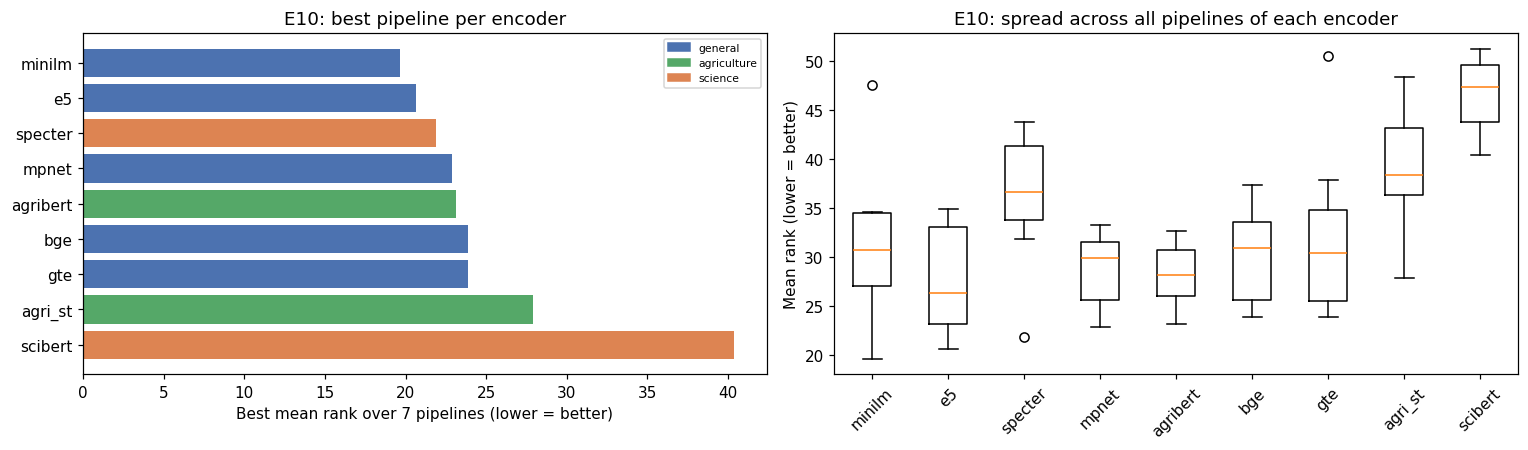

Best of the five requested models : specter | mean rank 21.88
Best domain/science-trained = specter (21.88); best general = minilm (19.62) -> general-purpose model wins on this data.
Stability std of those two configurations (rank differences this small are not meaningful): 0.092 and 0.002


In [49]:
from matplotlib.patches import Patch
colors_g = {"general": "#4C72B0", "agriculture": "#55A868", "science": "#DD8452"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
bar = per_encoder.iloc[::-1]
axes[0].barh(bar["encoder"], bar["best_mean_rank"], color=[colors_g[g] for g in bar["group"]])
axes[0].set_xlabel("Best mean rank over 7 pipelines (lower = better)"); axes[0].set_title("E10: best pipeline per encoder")
axes[0].legend(handles=[Patch(color=c, label=g) for g, c in colors_g.items()], fontsize=7)
order = list(per_encoder["encoder"])
data = [ranked.loc[ranked["encoder"] == e, "mean_rank"].values for e in order]
axes[1].boxplot(data)
axes[1].set_xticks(range(1, len(order) + 1)); axes[1].set_xticklabels(order, rotation=45)
axes[1].set_ylabel("Mean rank (lower = better)"); axes[1].set_title("E10: spread across all pipelines of each encoder")
fig.tight_layout()
save_fig(fig, "E10", "E10_encoder_comparison", "Best rank per encoder and rank spread across pipelines")

dom_best = per_encoder[per_encoder["group"] != "general"].iloc[0]
gen_best = per_encoder[per_encoder["group"] == "general"].iloc[0]
req = per_encoder[per_encoder["requested_domain_set"]]
print("Best of the five requested models :", req.iloc[0]["encoder"], "| mean rank", round(req.iloc[0]["best_mean_rank"], 2))
verdict = "domain/science-trained" if dom_best["best_mean_rank"] < gen_best["best_mean_rank"] else "general-purpose"
print(f"Best domain/science-trained = {dom_best['encoder']} ({dom_best['best_mean_rank']:.2f}); best general = {gen_best['encoder']} ({gen_best['best_mean_rank']:.2f}) -> {verdict} model wins on this data.")
print("Stability std of those two configurations (rank differences this small are not meaningful):",
      round(float(ranked[ranked['config'] == dom_best['best_config']]['stability_ari_std'].iloc[0]), 3), "and",
      round(float(ranked[ranked['config'] == gen_best['best_config']]['stability_ari_std'].iloc[0]), 3))

## Stage 11 — Experiment E5: sensitivity to the text input
Your requirement fixes the input to **Query + Response**. This experiment does **not** change that; it shows what Query + Response adds compared with question-only / answer-only text, using the **best transformer pipeline** from Stage 9 (same encoder, same algorithm, same K or `min_cluster_size`).

Because the reference corpus used for scoring contains both query and response, a fair single "winner" cannot be declared by internal scores alone. So this is reported as a **sensitivity analysis**: how many clusters appear, how coherent their top words are on the Query + Response corpus and on each variant's own corpus, and how strongly each variant's clustering agrees (ARI / AMI) with the main one.

E5 pipeline: minilm | kmeans | param = 5


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

  encoded 5000 texts with minilm in 1.4s -> shape (5000, 384)
  [saved npy  ] experiment_outputs/05_embeddings/hf_minilm_E5_question_only_text_920ec728ed.npy  (7500.1 KB)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

... (5 outputs left out)

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

  encoded 5000 texts with minilm in 2.8s -> shape (5000, 384)
  [saved npy  ] experiment_outputs/05_embeddings/hf_minilm_E5_truncated_answer_text_293ed40dcd.npy  (7500.1 KB)


,variant,n_clusters,max_cluster_share,npmi_on_main_corpus,npmi_on_own_corpus,ARI_vs_main,AMI_vs_main
0,query_answer_text,5,0.4500,0.185617,0.185617,1.000000,1.000000
1,question_only_text,5,0.3496,0.119703,-0.126621,0.469589,0.475652
2,answer_only_text,5,0.3006,0.133084,0.043979,0.461951,0.523053
3,boilerplate_stripped_text,5,0.4500,0.185720,0.185720,0.999704,0.998935
4,truncated_answer_text,5,0.4496,0.185919,0.187182,0.996162,0.990600


  [saved csv  ] experiment_outputs/11_E5_text_variants/E5_text_variants.csv  (0.6 KB)
  [saved csv  ] experiment_outputs/11_E5_text_variants/E5_labels.csv  (92.9 KB)
  [saved png  ] experiment_outputs/11_E5_text_variants/E5_variant_agreement.png  (90.7 KB)


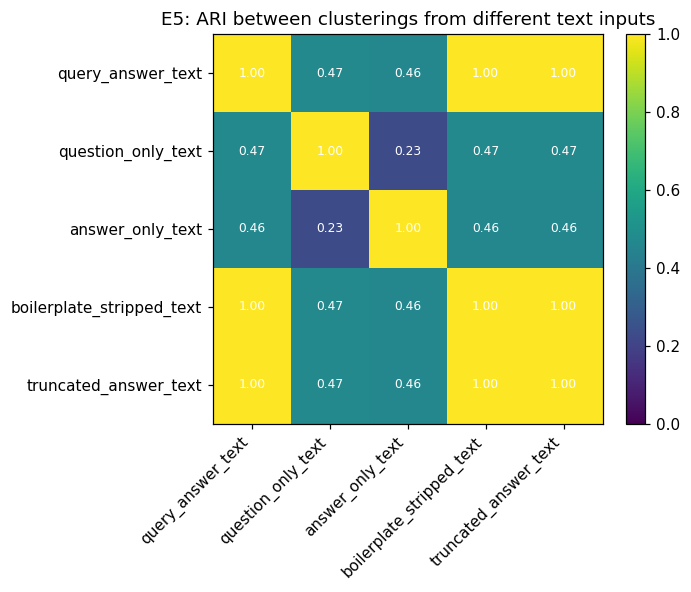

In [50]:
def run_pipeline(raw_vectors, algo, reduce, param, seed=RANDOM_SEED):
    """Full clustering pipeline: [UMAP] -> algorithm -> noise assignment. `param` = K, or min_cluster_size for HDBSCAN."""
    space = umap_reduce(raw_vectors, UMAP_DIM, seed) if reduce == "umap" else raw_vectors
    if algo == "hdbscan":
        labels, _ = hdbscan_labels(space, param)
    else:
        labels = labels_for_k(space, algo, param, seed=seed)
    return finalize_labels(space, labels)

best_t_cfg = GRID[BEST_TRANSFORMER["config"]]["cfg"]
best_t_param = GRID[BEST_TRANSFORMER["config"]]["param"]
print("E5 pipeline:", BEST_TRANSFORMER["config"], "| param =", best_t_param)

main_labels_t = GRID[BEST_TRANSFORMER["config"]]["labels"]
e5_rows, e5_labels = [], {}
for variant in TEXT_COLUMNS:
    texts = df[variant].fillna("").tolist()
    tag = "main" if variant == "query_answer_text" else f"E5_{variant}"
    vecs = get_hf_embeddings(texts, best_t_cfg["encoder"], tag=tag)
    labels = run_pipeline(vecs, best_t_cfg["algo"], best_t_cfg["reduce"], best_t_param)
    e5_labels[variant] = labels
    own_index = COH_INDEX if variant == "query_answer_text" else build_coherence_index(texts)
    e5_rows.append({"variant": variant, "n_clusters": int(len(np.unique(labels))), "max_cluster_share": max_cluster_share(labels),
                    "npmi_on_main_corpus": npmi_coherence(labels, COH_INDEX), "npmi_on_own_corpus": npmi_coherence(labels, own_index),
                    "ARI_vs_main": adjusted_rand_score(main_labels_t, labels), "AMI_vs_main": adjusted_mutual_info_score(main_labels_t, labels)})
e5_results = pd.DataFrame(e5_rows)
display(e5_results)
save_df(e5_results, "E5", "E5_text_variants", "Sensitivity of the best transformer pipeline to the text input")
save_df(pd.DataFrame(e5_labels).assign(query_id=df["query_id"].values), "E5", "E5_labels", "Cluster labels per text variant")

agree = pd.DataFrame([[adjusted_rand_score(e5_labels[a], e5_labels[b]) for b in TEXT_COLUMNS] for a in TEXT_COLUMNS], index=TEXT_COLUMNS, columns=TEXT_COLUMNS)
fig = heatmap(agree, "E5: ARI between clusterings from different text inputs", vmin=0, vmax=1)
save_fig(fig, "E5", "E5_variant_agreement", "ARI agreement between text variants")

## Stage 12 — Experiment E6: stability of the overall winner
A good clustering should not change much when the random seed or the data subset changes.
* **Seed stability** re-runs the *entire* pipeline (including a new UMAP projection if the winner uses UMAP) with 5 different seeds.
* **Resampling stability** (80% subsets) was already computed in Stage 9 and is repeated here for reference.
ARI / AMI = 1 means identical clusterings; ≈ 0 means unrelated.

Winner: minilm | kmeans | param = 5


,seed_a,seed_b,ARI,AMI
0,0,1,0.999487,0.997896
1,0,2,0.998055,0.994531
2,0,3,0.998865,0.997700
3,0,4,0.998222,0.995730
4,1,2,0.998568,0.996634
5,1,3,0.998352,0.995596
6,1,4,0.997709,0.993626
7,2,3,0.999190,0.996831
8,2,4,0.998005,0.994692
9,3,4,0.998222,0.995730


Mean ARI: 0.998 | Mean AMI: 0.996
Resampling ARI (80% subsets, from Stage 9): 0.990 +- 0.002
  [saved csv  ] experiment_outputs/12_E6_stability/E6_seed_stability.csv  (0.4 KB)
  [saved csv  ] experiment_outputs/12_E6_stability/E6_labels_by_seed.csv  (92.8 KB)
  [saved png  ] experiment_outputs/12_E6_stability/E6_seed_ari_heatmap.png  (36.2 KB)


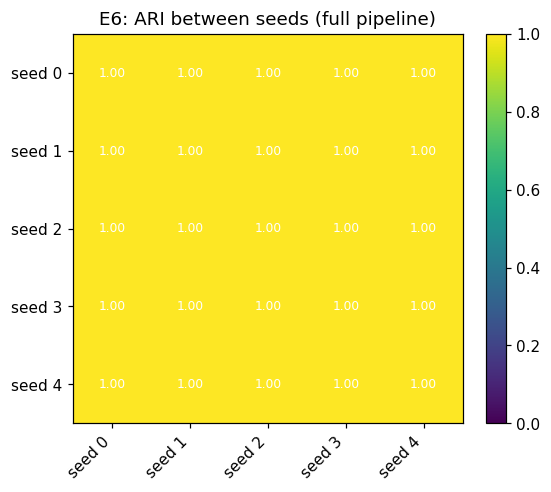

In [51]:
final_cfg = GRID[BEST_OVERALL["config"]]["cfg"]
final_param = GRID[BEST_OVERALL["config"]]["param"]
final_raw = EMBEDDINGS[final_cfg["encoder"]]
print("Winner:", BEST_OVERALL["config"], "| param =", final_param)

labels_by_seed = {s: run_pipeline(final_raw, final_cfg["algo"], final_cfg["reduce"], final_param, seed=s) for s in range(N_STABILITY_SEEDS)}
seeds = list(labels_by_seed)
seed_rows = [{"seed_a": a, "seed_b": b, "ARI": adjusted_rand_score(labels_by_seed[a], labels_by_seed[b]),
              "AMI": adjusted_mutual_info_score(labels_by_seed[a], labels_by_seed[b])} for i, a in enumerate(seeds) for b in seeds[i + 1:]]
e6_results = pd.DataFrame(seed_rows)
display(e6_results)
print("Mean ARI: {:.3f} | Mean AMI: {:.3f}".format(e6_results["ARI"].mean(), e6_results["AMI"].mean()))
print("Resampling ARI (80% subsets, from Stage 9): {:.3f} +- {:.3f}".format(BEST_OVERALL["stability_ari"], BEST_OVERALL["stability_ari_std"]))
save_df(e6_results, "E6", "E6_seed_stability", "ARI/AMI between full-pipeline runs with different seeds")
save_df(pd.DataFrame(labels_by_seed).assign(query_id=df["query_id"].values), "E6", "E6_labels_by_seed", "Cluster labels for each seed")

seed_matrix = pd.DataFrame([[adjusted_rand_score(labels_by_seed[a], labels_by_seed[b]) for b in seeds] for a in seeds],
                           index=[f"seed {s}" for s in seeds], columns=[f"seed {s}" for s in seeds])
fig = heatmap(seed_matrix, "E6: ARI between seeds (full pipeline)", vmin=0, vmax=1)
save_fig(fig, "E6", "E6_seed_ari_heatmap", "Seed-by-seed ARI heatmap")

## Stage 13 — Experiment E7: do the different representations agree?
For every vector space, its **best-ranked configuration** is taken from the leaderboard and the resulting clusterings are compared pairwise.
High agreement between very different models (e.g. Doc2Vec vs BGE) suggests the cluster structure is **real** and not an artefact of one model.

,space,best_config
0,tfidf_svd,tfidf_svd | ward
1,doc2vec,doc2vec | kmeans
2,glove_avg,glove_avg | kmeans
3,minilm,minilm | kmeans
4,mpnet,mpnet+umap | kmeans
5,e5,e5+umap | ward
6,bge,bge+umap | gmm
7,gte,gte | kmeans
8,agri_st,agri_st+umap | ward
9,agribert,agribert+umap | ward


,space_a,space_b,ARI,AMI
60,agri_st,agribert,0.837726,0.734412
39,mpnet,bge,0.744911,0.754163
51,bge,gte,0.715515,0.747809
35,minilm,agribert,0.672046,0.586480
34,minilm,agri_st,0.660329,0.559053
...,...,...,...,...
9,tfidf_svd,scibert,0.073097,0.254820
11,doc2vec,glove_avg,0.062013,0.125572
14,doc2vec,e5,0.052802,0.182838
19,doc2vec,scibert,0.041396,0.099618


  [saved csv  ] experiment_outputs/13_E7_encoder_agreement/E7_encoder_agreement.csv  (3.4 KB)
  [saved png  ] experiment_outputs/13_E7_encoder_agreement/E7_ari_heatmap.png  (181.9 KB)


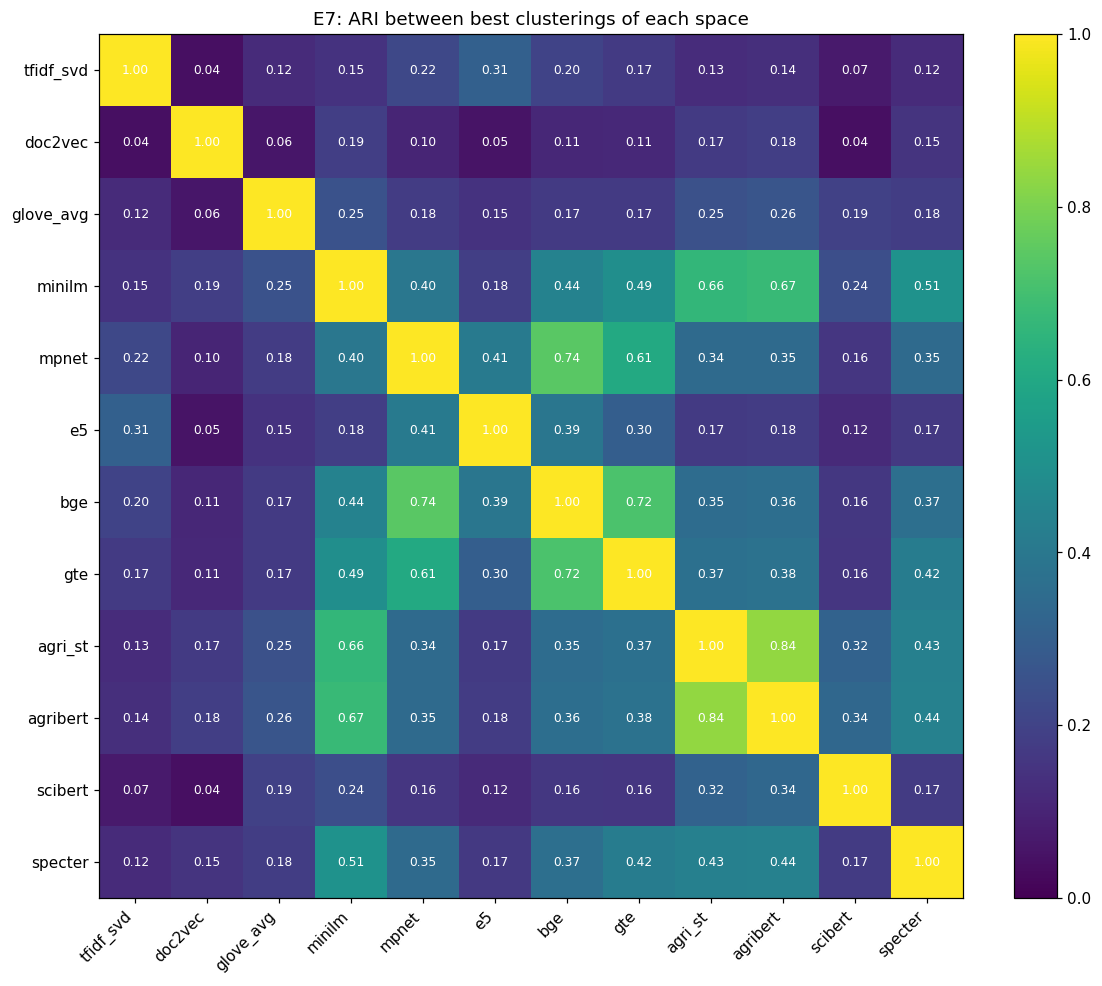

  [saved csv  ] experiment_outputs/13_E7_encoder_agreement/E7_ari_matrix.csv  (2.8 KB)


,mean_ARI
minilm,0.380254
agribert,0.375268
agri_st,0.366288
bge,0.365431
gte,0.354293
mpnet,0.350243
specter,0.300360
e5,0.220402
glove_avg,0.180782
scibert,0.179220


In [52]:
best_per_space = {}
for space in EMBEDDINGS:
    sub = ranked[ranked["encoder"] == space]
    if len(sub):
        best_per_space[space] = sub.iloc[0]["config"]
labels_by_model = {sp: GRID[cfg_name]["labels"] for sp, cfg_name in best_per_space.items()}
names_sp = list(labels_by_model)
pair_rows = [{"space_a": a, "space_b": b, "ARI": adjusted_rand_score(labels_by_model[a], labels_by_model[b]),
              "AMI": adjusted_mutual_info_score(labels_by_model[a], labels_by_model[b])} for i, a in enumerate(names_sp) for b in names_sp[i + 1:]]
e7_results = pd.DataFrame(pair_rows)
display(pd.DataFrame({"space": list(best_per_space), "best_config": list(best_per_space.values())}))
display(e7_results.sort_values("ARI", ascending=False))
save_df(e7_results, "E7", "E7_encoder_agreement", "Pairwise ARI/AMI between best clusterings of each space")

ari_matrix = pd.DataFrame([[adjusted_rand_score(labels_by_model[a], labels_by_model[b]) for b in names_sp] for a in names_sp], index=names_sp, columns=names_sp)
fig = heatmap(ari_matrix, "E7: ARI between best clusterings of each space", vmin=0, vmax=1)
save_fig(fig, "E7", "E7_ari_heatmap", "ARI heatmap between spaces")
save_df(ari_matrix.reset_index().rename(columns={"index": "space"}), "E7", "E7_ari_matrix", "ARI matrix")
mean_agree = (ari_matrix.sum() - 1) / max(1, (len(names_sp) - 1))
display(mean_agree.sort_values(ascending=False).rename("mean_ARI").to_frame())

## Stage 14 — Experiment E11: extracting a topic for every record
To test whether **adding a topic to the input** helps, a topic must first be extracted. Two independent methods are used so the answer does not depend on one technique:

| Method | Type | How it works | Why |
|---|---|---|---|
| **NMF topics** | statistical | Non-negative matrix factorisation of TF-IDF; every record gets its dominant topic, written as the topic's top 4 words | Short texts + TF-IDF weights suit NMF; `nndsvd` start makes it deterministic. The number of topics is **not assumed**: 5…20 topics are tried and the one with the best NPMI coherence (and not degenerate) is chosen |
| **Agri key-phrases** | transformer | KeyBERT-style: candidate 1–2-word phrases that occur in the record are ranked by cosine similarity to the record's embedding from the **agriculture-trained encoder**; top 3 non-overlapping phrases kept | Uses a domain model to decide what each record is *about*, at record level (NMF gives one of K shared topics) |

**Two traps, and how they are handled**
1. *Circularity.* NMF topics come from the same word statistics the clustering will see, and key-phrases come from an encoder's own geometry. A gain could simply mean "we told the model its own answer". So every topic input gets a **shuffled-topic control**: the same topic strings randomly reassigned to other records. If the real topic beats the control, the content of the topic matters; if not, it does not.
2. *Truncation.* The topic is placed **between question and answer** (`question: … topic: … answer: …`) so long answers cannot cut it off.

TF-IDF matrix for NMF: (5000, 1121)


,n_topics,reconstruction_error,npmi_coherence,topics_used,max_topic_share
0,5,65.703516,0.164704,5,0.2966
1,6,65.305883,0.198447,6,0.2476
2,7,64.937046,0.191244,7,0.1808
3,8,64.575579,0.210115,8,0.1648
4,9,64.206250,0.194613,9,0.1562
5,10,63.894041,0.186501,10,0.1512
6,11,63.596754,0.178762,11,0.1194
7,12,63.283554,0.207000,12,0.1180
8,13,62.977192,0.232280,13,0.1112
9,14,62.676249,0.232102,14,0.1062


Chosen number of NMF topics = 16 (max NPMI among non-degenerate). Elbow of reconstruction error = 10 (strength 0.06).
  [saved csv  ] experiment_outputs/14_E11_topic_extraction/E11_nmf_topic_count_sweep.csv  (0.8 KB)
  [saved png  ] experiment_outputs/14_E11_topic_extraction/E11_nmf_topic_count_plot.png  (61.7 KB)


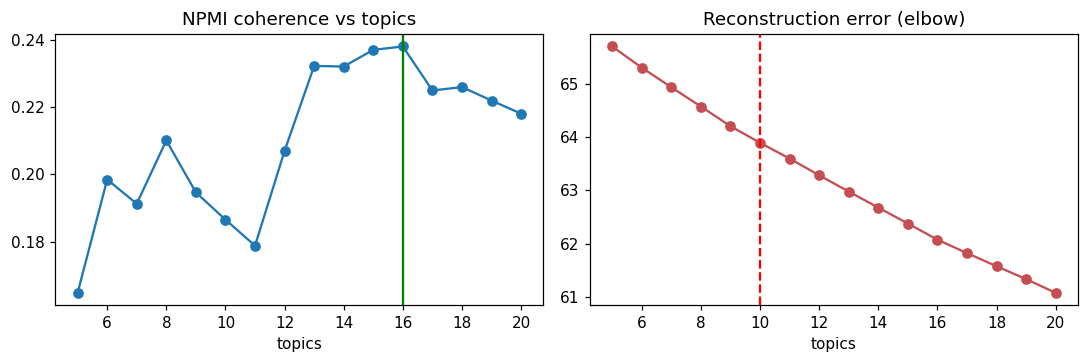

In [53]:
# ---- 14.1 NMF topic model: try 5..20 topics, pick by NPMI coherence
topic_vec = TfidfVectorizer(stop_words=STOP_WORDS, min_df=5, max_df=0.5, max_features=10000, token_pattern=r"(?u)\b[a-z][a-z]+\b")
Xt = topic_vec.fit_transform(main_texts)
topic_terms = np.array(topic_vec.get_feature_names_out())
print("TF-IDF matrix for NMF:", Xt.shape)

topic_k_candidates = [k for k in TOPIC_K_RANGE if k < min(Xt.shape)]
nmf_rows, NMF_FITS = [], {}
for kt in topic_k_candidates:
    nmf = NMF(n_components=kt, init="nndsvd", random_state=RANDOM_SEED, max_iter=500)
    W = nmf.fit_transform(Xt)
    dom = W.argmax(axis=1)
    NMF_FITS[kt] = (nmf, W)
    nmf_rows.append({"n_topics": kt, "reconstruction_error": float(nmf.reconstruction_err_), "npmi_coherence": npmi_coherence(dom, COH_INDEX),
                     "topics_used": int(len(np.unique(dom))), "max_topic_share": max_cluster_share(dom)})
nmf_sweep = pd.DataFrame(nmf_rows)
display(nmf_sweep)
ok = nmf_sweep[(nmf_sweep["topics_used"] == nmf_sweep["n_topics"]) & (nmf_sweep["max_topic_share"] <= DEGENERATE_SHARE)]
if ok.empty:
    ok = nmf_sweep
N_TOPICS = int(ok.loc[ok["npmi_coherence"].idxmax(), "n_topics"])
elbow_topics, elbow_topics_strength = elbow_k(nmf_sweep["n_topics"].values, nmf_sweep["reconstruction_error"].values)
print(f"Chosen number of NMF topics = {N_TOPICS} (max NPMI among non-degenerate). Elbow of reconstruction error = {elbow_topics} (strength {elbow_topics_strength:.2f}).")
save_df(nmf_sweep, "E11", "E11_nmf_topic_count_sweep", "NMF: NPMI coherence and reconstruction error for every topic count")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(nmf_sweep["n_topics"], nmf_sweep["npmi_coherence"], "o-"); axes[0].axvline(N_TOPICS, color="green"); axes[0].set_title("NPMI coherence vs topics"); axes[0].set_xlabel("topics")
axes[1].plot(nmf_sweep["n_topics"], nmf_sweep["reconstruction_error"], "o-", color="#C44E52"); axes[1].axvline(elbow_topics, color="red", ls="--"); axes[1].set_title("Reconstruction error (elbow)"); axes[1].set_xlabel("topics")
fig.tight_layout()
save_fig(fig, "E11", "E11_nmf_topic_count_plot", "NMF topic-count selection")

In [54]:
# ---- 14.2 Read the chosen NMF topics
nmf_model, W_nmf = NMF_FITS[N_TOPICS]
H_nmf = nmf_model.components_
nmf_topic_words = {t: " ".join(topic_terms[np.argsort(-H_nmf[t])[:TOPIC_WORDS_PER_NMF_TOPIC]]) for t in range(N_TOPICS)}
dominant = W_nmf.argmax(axis=1)
df["topic_nmf"] = [nmf_topic_words[t] if W_nmf[i].sum() > 0 else "general" for i, t in enumerate(dominant)]
nmf_topic_table = pd.DataFrame({"topic": range(N_TOPICS), "size": np.bincount(dominant, minlength=N_TOPICS),
                                "top_10_words": [", ".join(topic_terms[np.argsort(-H_nmf[t])[:10]]) for t in range(N_TOPICS)],
                                "topic_string_used_in_input": [nmf_topic_words[t] for t in range(N_TOPICS)]})
display(nmf_topic_table)
save_df(nmf_topic_table, "E11", "E11_nmf_topics", "Chosen NMF topics, sizes and words")

,topic,size,top_10_words,topic_string_used_in_input
0,0,258,"malathion, ec, fruit, ml, litre, water, fly, g...",malathion ec fruit ml
1,1,442,"kg, bigha, urea, dose, fertilizer, mop, ssp, a...",kg bigha urea dose
2,2,250,"explained, details, cultural, practices, pract...",explained details cultural practices
3,3,330,"days, interval, times, spray, recommended, wat...",days interval times spray
4,4,384,"query, regarding, advised, lit, application, a...",query regarding advised lit
5,5,376,"wilt, bavistin, litre, fungal, advised, gram, ...",wilt bavistin litre fungal
6,6,405,"kisan, agriculture, office, pm, contact, distr...",kisan agriculture office pm
7,7,319,"plant, gm, fertilizer, coconut, borax, apply, ...",plant gm fertilizer coconut
8,8,357,"daily, treatment, suggested, administer, twice...",daily treatment suggested administer
9,9,308,"borer, stem, rice, ml, paddy, tricel, classic,...",borer stem rice ml


  [saved csv  ] experiment_outputs/14_E11_topic_extraction/E11_nmf_topics.csv  (1.9 KB)


PosixPath('experiment_outputs/14_E11_topic_extraction/E11_nmf_topics.csv')

In [55]:
# ---- 14.3 Agri-encoder key-phrases (KeyBERT-style)
TOPIC_ENCODER = next((e for e in TOPIC_ENCODER_PREFERENCE if e in EMBEDDINGS), BEST_DOMAIN["encoder"])
print("Encoder used to rank key-phrases:", TOPIC_ENCODER, "-", HF_ENCODER_MODELS[TOPIC_ENCODER], f"(group: {ENCODER_GROUP[TOPIC_ENCODER]})")

phrase_vec = CountVectorizer(ngram_range=(1, 2), stop_words=STOP_WORDS, min_df=5, max_df=0.3, binary=True, token_pattern=r"(?u)\b[a-z][a-z]+\b")
B_phr = phrase_vec.fit_transform(main_texts).tocsr()
phrases = np.array(phrase_vec.get_feature_names_out())
print("Candidate phrases:", len(phrases))
P_emb = get_hf_embeddings(list(phrases), TOPIC_ENCODER, tag="E11_phrases")
D_emb = EMBEDDINGS[TOPIC_ENCODER]

key_rows = []
for i in range(B_phr.shape[0]):
    idx = B_phr.indices[B_phr.indptr[i]:B_phr.indptr[i + 1]]
    if len(idx) == 0:
        key_rows.append("general")
        continue
    sims = P_emb[idx] @ D_emb[i]
    chosen, used = [], set()
    for j in np.argsort(-sims):
        words = set(phrases[idx[j]].split())
        if words & used:                       # skip phrases that repeat a word already chosen (keeps the 3 topics distinct)
            continue
        chosen.append(phrases[idx[j]]); used |= words
        if len(chosen) == KEYPHRASES_PER_DOC:
            break
    key_rows.append(", ".join(chosen))
df["topic_keyphrase"] = key_rows
print("Records with no candidate phrase:", int((df["topic_keyphrase"] == "general").sum()))
display(df[["representative_question", "topic_nmf", "topic_keyphrase"]].sample(10, random_state=RANDOM_SEED))
top_phr = pd.Series(", ".join(df["topic_keyphrase"]).split(", ")).value_counts().head(25).rename_axis("keyphrase").reset_index(name="records")
display(top_phr)
save_df(df[["query_id", "representative_question", "topic_nmf", "topic_keyphrase"]], "E11", "E11_topics_per_record", "NMF topic and key-phrases assigned to every record")
save_df(top_phr, "E11", "E11_top_keyphrases", "Most frequent key-phrases")

Encoder used to rank key-phrases: agri_st - recobo/agri-sentence-transformer (group: agriculture)
Candidate phrases: 2932


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/46 [00:00<?, ?it/s]

  encoded 2932 texts with agri_st in 1.4s -> shape (2932, 768)
  [saved npy  ] experiment_outputs/05_embeddings/hf_agri_st_E11_phrases_9d82ce73ac.npy  (8796.1 KB)
Records with no candidate phrase: 7


,representative_question,topic_nmf,topic_keyphrase
1501,asking about extension programe,kisan agriculture office pm,"kvk, extension"
2586,asking for the insect pest management in paddy.,tracel nutrient spray water,"management paddy, spray malathion, insect pest"
2653,asking about the govt. scheme,kisan agriculture office pm,"advised contact, asking govt, kvk"
1055,asking about brinjal shoot borer problem,borer stem rice ml,"spray rocket, brinjal shoot, borer problem"
705,asking about the recommended fym dose for ginger,kg bigha urea dose,"ginger, fym, dose"
106,anthracnose desease of chilly.,wilt bavistin litre fungal,"anthracnose desease, chilly advised, spray captan"
589,wilting in bhut jolokia,control measure lit spray,"bhut jolokia, spray captaf, wilting"
2468,asking about treatment worms infestation in pig.,daily treatment suggested administer,"panacur mg, treatment worms, pig suggested"
2413,asking about cultural parctices of pumkin,explained details cultural practices,"pumkin, asking cultural, details"
1600,problem of rice stem borer.,borer stem rice ml,"stem borer, problem rice, classic ml"


,keyphrase,records
0,control measure,186
1,control,183
2,spray malathion,162
3,apply urea,160
4,spray rogor,137
5,apply,124
6,details,117
7,fertilizer,112
8,fertilizer dose,110
9,chilli,97


  [saved csv  ] experiment_outputs/14_E11_topic_extraction/E11_topics_per_record.csv  (579.3 KB)
  [saved csv  ] experiment_outputs/14_E11_topic_extraction/E11_top_keyphrases.csv  (0.4 KB)


PosixPath('experiment_outputs/14_E11_topic_extraction/E11_top_keyphrases.csv')

In [56]:
# ---- 14.4 Build the input variants (+ shuffled controls)
def build_text_with_topic(q, t, a):
    return ("question: " + q + " topic: " + t + (" answer: " + a if a else "")).strip()

perm = np.random.default_rng(RANDOM_SEED).permutation(len(df))
df["topic_nmf_shuffled"] = df["topic_nmf"].values[perm]
df["topic_keyphrase_shuffled"] = df["topic_keyphrase"].values[perm]
df["qr_nmf_text"] = [build_text_with_topic(q, t, a) for q, t, a in zip(df["representative_clean"], df["topic_nmf"], df["answer_text"])]
df["qr_keyphrase_text"] = [build_text_with_topic(q, t, a) for q, t, a in zip(df["representative_clean"], df["topic_keyphrase"], df["answer_text"])]
df["qr_nmf_shuffled_text"] = [build_text_with_topic(q, t, a) for q, t, a in zip(df["representative_clean"], df["topic_nmf_shuffled"], df["answer_text"])]
df["qr_keyphrase_shuffled_text"] = [build_text_with_topic(q, t, a) for q, t, a in zip(df["representative_clean"], df["topic_keyphrase_shuffled"], df["answer_text"])]

INPUT_VARIANTS = {"qr": "query_answer_text", "qr+nmf": "qr_nmf_text", "qr+keyphrase": "qr_keyphrase_text",
                  "qr+nmf (shuffled control)": "qr_nmf_shuffled_text", "qr+keyphrase (shuffled control)": "qr_keyphrase_shuffled_text"}
CONTROL_OF = {"qr+nmf": "qr+nmf (shuffled control)", "qr+keyphrase": "qr+keyphrase (shuffled control)"}
display(df[["query_answer_text", "qr_nmf_text", "qr_keyphrase_text"]].head(2).T)
save_df(df[["query_id"] + list(INPUT_VARIANTS.values())], "E11", "E11_input_variants", "All five input variants for every record")

,0,1
query_answer_text,"question: query regarding some local chicken, ...",question: asking about the control of leaf cur...
qr_nmf_text,"question: query regarding some local chicken, ...",question: asking about the control of leaf cur...
qr_keyphrase_text,"question: query regarding some local chicken, ...",question: asking about the control of leaf cur...


  [saved csv  ] experiment_outputs/14_E11_topic_extraction/E11_input_variants.csv  (4217.8 KB)


PosixPath('experiment_outputs/14_E11_topic_extraction/E11_input_variants.csv')

## Stage 15 — Experiment E12: Query + Response vs Query + Response + Topic
**Question:** does adding a topic to the input produce better clusters?

**Design**
* Encoders tested: the overall winner's encoder and the best agriculture/science-trained encoder (from Stages 9–10), each with **its own best pipeline** (same algorithm family as in the leaderboard).
* Five inputs per encoder: `qr` (baseline), `qr+nmf`, `qr+keyphrase`, and one **shuffled control** per topic type.
* K is **re-chosen for every input** with the same rule as before (K is not carried over).
* Each clustering is re-run with `N_INPUT_SEEDS` seeds (new UMAP projection and new silhouette subset each time) to measure noise.

**Scoring (all computed in representations that did NOT see the topic)**
* `consensus_z` — cross-space silhouette in the *Query + Response* reference spaces (own encoder excluded), z-scored exactly as in the leaderboard.
* `stability_ari` — 80 % subsample stability.
* `npmi_main`, `lexical_f1` — word-based scores. Shown, but **not used for the decision**, because topic words are themselves word statistics (circular).

**Decision rule for adopting a topic input (all three must hold):**
1. `consensus_z` gain over baseline is larger than the larger seed-to-seed standard deviation of the two runs (so it is not noise);
2. stability is not lower than baseline by more than that run's stability std;
3. `consensus_z` is higher than that topic's **shuffled control**.
Otherwise the baseline Query + Response stays the final input.

In [57]:
INPUT_TEST_ENCODERS = []
first = BEST_OVERALL["encoder"] if BEST_OVERALL["encoder"] in TRANSFORMER_SPACES else BEST_TRANSFORMER["encoder"]
for e in [first, BEST_DOMAIN["encoder"]]:
    if e not in INPUT_TEST_ENCODERS:
        INPUT_TEST_ENCODERS.append(e)
print("Encoders used for the input comparison:", INPUT_TEST_ENCODERS)

E12_rows, INPUT_LABELS, INPUT_EMB, E12_SWEEPS = [], {}, {}, []
for enc in INPUT_TEST_ENCODERS:
    base_name = ranked[ranked["encoder"] == enc].iloc[0]["config"]
    cfg = GRID[base_name]["cfg"]
    print(f"\n=== {enc}: pipeline {base_name} ===")
    for vname, col in INPUT_VARIANTS.items():
        t0 = time.time()
        if vname == "qr":
            raw, param, labels0 = EMBEDDINGS[enc], GRID[base_name]["param"], GRID[base_name]["labels"]
            space0, k_used = SPACE_VEC[cfg["space_key"]], GRID[base_name]["k"]
        else:
            raw = get_hf_embeddings(df[col].fillna("").tolist(), enc, tag=f"E12_{col}")
            res = auto_cluster(raw, cfg["algo"], cfg["reduce"], seed=RANDOM_SEED, tag=f"E12|{enc}|{vname}")
            param, labels0, space0, k_used = res["param"], res["labels"], res["space"], res["k"]
            E12_SWEEPS.append(res["sweep"].assign(encoder=enc, variant=vname))
        INPUT_EMB[(enc, vname)], INPUT_LABELS[(enc, vname)] = raw, labels0
        per_seed = []
        for s in range(N_INPUT_SEEDS):
            labs = labels0 if s == 0 else run_pipeline(raw, cfg["algo"], cfg["reduce"], param, seed=RANDOM_SEED + s)
            z, rawc = zscore_consensus(labs, enc, seed=RANDOM_SEED + s)
            per_seed.append({"consensus_z": z, "consensus_raw": rawc, "npmi_main": npmi_coherence(labs, COH_INDEX)})
        ps = pd.DataFrame(per_seed)
        stab_m, stab_s = stability_resampling(cfg, labels0, param, space0)
        rec = recoverability(labels0, sparse)
        E12_rows.append({"encoder": enc, "variant": vname, "pipeline": base_name, "k": int(k_used),
                         "consensus_z": ps["consensus_z"].mean(), "consensus_z_std": ps["consensus_z"].std(ddof=0),
                         "consensus_raw": ps["consensus_raw"].mean(), "npmi_main": ps["npmi_main"].mean(), "npmi_main_std": ps["npmi_main"].std(ddof=0),
                         "stability_ari": stab_m, "stability_ari_std": stab_s, "max_cluster_share": max_cluster_share(labels0),
                         "lexical_f1": rec["macro_f1"] if rec else np.nan})
        print(f"  {vname:34s} K={k_used:>2d}  consensus_z={ps['consensus_z'].mean():+.3f} (+-{ps['consensus_z'].std(ddof=0):.3f})  ({time.time() - t0:.0f}s)")

E12 = pd.DataFrame(E12_rows)
E12["ARI_vs_baseline"] = [adjusted_rand_score(INPUT_LABELS[(r.encoder, "qr")], INPUT_LABELS[(r.encoder, r.variant)]) for r in E12.itertuples()]
display(E12)
save_df(E12, "E12", "E12_input_comparison", "Every input variant x encoder: K, consensus, stability, word-based scores, agreement with baseline")
if E12_SWEEPS:
    save_df(pd.concat(E12_SWEEPS, ignore_index=True), "E12", "E12_k_sweeps_per_input", "K (or HDBSCAN) sweeps for every input variant")

Encoders used for the input comparison: ['minilm', 'specter']

=== minilm: pipeline minilm | kmeans ===
  qr                                 K= 5  consensus_z=+1.360 (+-0.026)  (13s)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

  encoded 5000 texts with minilm in 3.2s -> shape (5000, 384)
  [saved npy  ] experiment_outputs/05_embeddings/hf_minilm_E12_qr_nmf_text_ffc48ca9e7.npy  (7500.1 KB)
  qr+nmf                             K=14  consensus_z=+0.006 (+-0.069)  (76s)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

... (17 outputs left out)

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

  encoded 5000 texts with specter in 20.1s -> shape (5000, 768)
  [saved npy  ] experiment_outputs/05_embeddings/hf_specter_E12_qr_keyphrase_shuffled_text_9cadfe0aaa.npy  (15000.1 KB)
  qr+keyphrase (shuffled control)    K= 5  consensus_z=-0.828 (+-0.043)  (155s)


,encoder,variant,pipeline,k,consensus_z,consensus_z_std,consensus_raw,npmi_main,npmi_main_std,stability_ari,stability_ari_std,max_cluster_share,lexical_f1,ARI_vs_baseline
0,minilm,qr,minilm | kmeans,5,1.359557,0.025734,0.124585,0.185533,0.000060,0.990278,0.001736,0.4500,0.918175,1.000000
1,minilm,qr+nmf,minilm | kmeans,14,0.006058,0.068758,0.033387,0.240096,0.004205,0.889939,0.072302,0.1108,0.885227,0.200665
2,minilm,qr+keyphrase,minilm | kmeans,5,1.340061,0.021400,0.123458,0.175773,0.000217,0.977896,0.004993,0.4478,0.916185,0.903659
3,minilm,qr+nmf (shuffled control),minilm | kmeans,6,-0.070261,0.090239,0.035345,0.214621,0.001608,0.955118,0.023942,0.3574,0.756948,0.526355
4,minilm,qr+keyphrase (shuffled control),minilm | kmeans,5,0.859621,0.075188,0.093778,0.200785,0.000061,0.977665,0.002654,0.4288,0.814889,0.678693
5,specter,qr,specter | kmeans,5,0.669633,0.017478,0.084207,0.220550,0.000009,0.913954,0.092147,0.3612,0.866308,1.000000
6,specter,qr+nmf,specter | kmeans,5,0.618889,0.023536,0.080932,0.223405,0.000146,0.986912,0.003270,0.3876,0.862551,0.688584
7,specter,qr+keyphrase,specter | kmeans,15,-0.490955,0.070060,0.009794,0.175820,0.002868,0.765408,0.037013,0.1736,0.794435,0.362193
8,specter,qr+nmf (shuffled control),specter | kmeans,5,0.122957,0.029510,0.052623,0.114983,0.005914,0.940710,0.041620,0.3598,0.714807,0.567736
9,specter,qr+keyphrase (shuffled control),specter | kmeans,5,-0.827521,0.043321,-0.005638,0.152900,0.001239,0.876025,0.050748,0.2800,0.630986,0.355529


  [saved csv  ] experiment_outputs/15_E12_input_with_topic/E12_input_comparison.csv  (2.4 KB)
  [saved csv  ] experiment_outputs/15_E12_input_with_topic/E12_k_sweeps_per_input.csv  (21.0 KB)


In [58]:
# ---- Decision rule (see the markdown above)
dec_rows = []
for enc in INPUT_TEST_ENCODERS:
    sub_e = E12[E12["encoder"] == enc].set_index("variant")
    base = sub_e.loc["qr"]
    for v, ctrl_name in CONTROL_OF.items():
        row, ctrl = sub_e.loc[v], sub_e.loc[ctrl_name]
        gain = row["consensus_z"] - base["consensus_z"]
        noise = max(base["consensus_z_std"], row["consensus_z_std"])
        cond1 = gain > noise
        cond2 = row["stability_ari"] >= base["stability_ari"] - max(base["stability_ari_std"], row["stability_ari_std"])
        cond3 = row["consensus_z"] > ctrl["consensus_z"]
        dec_rows.append({"encoder": enc, "variant": v, "gain_consensus_z": gain, "seed_noise": noise, "1_gain_beats_noise": bool(cond1),
                         "2_stability_ok": bool(cond2), "3_beats_shuffled_control": bool(cond3),
                         "gain_vs_control": row["consensus_z"] - ctrl["consensus_z"],
                         "decision": "ADOPT topic" if (cond1 and cond2 and cond3) else "keep Query+Response"})
E12_decision = pd.DataFrame(dec_rows)
display(E12_decision)
save_df(E12_decision, "E12", "E12_decision", "Adoption decision per encoder and topic type")

FINAL_ENC = first
adopt = E12_decision[(E12_decision["encoder"] == FINAL_ENC) & (E12_decision["decision"] == "ADOPT topic")]
if len(adopt):
    FINAL_INPUT = max(adopt["variant"], key=lambda v: E12[(E12["encoder"] == FINAL_ENC) & (E12["variant"] == v)]["consensus_z"].iloc[0])
else:
    FINAL_INPUT = "qr"
FINAL_LABELS, FINAL_VECTORS = INPUT_LABELS[(FINAL_ENC, FINAL_INPUT)], INPUT_EMB[(FINAL_ENC, FINAL_INPUT)]
print(f"\nFINAL INPUT for {FINAL_ENC}: {FINAL_INPUT}  ->  {'topic input adopted (beats noise, stability and shuffled control)' if FINAL_INPUT != 'qr' else 'Query + Response only (no topic input passed all three tests)'}")
save_json({"FINAL_ENC": FINAL_ENC, "FINAL_INPUT": FINAL_INPUT}, "E12", "E12_final_input", "Input variant used for the final clusters")

,encoder,variant,gain_consensus_z,seed_noise,1_gain_beats_noise,2_stability_ok,3_beats_shuffled_control,gain_vs_control,decision
0,minilm,qr+nmf,-1.353499,0.068758,False,False,True,0.076319,keep Query+Response
1,minilm,qr+keyphrase,-0.019496,0.025734,False,False,True,0.480440,keep Query+Response
2,specter,qr+nmf,-0.050744,0.023536,False,True,True,0.495932,keep Query+Response
3,specter,qr+keyphrase,-1.160587,0.070060,False,False,True,0.336566,keep Query+Response


  [saved csv  ] experiment_outputs/15_E12_input_with_topic/E12_decision.csv  (0.6 KB)

FINAL INPUT for minilm: qr  ->  Query + Response only (no topic input passed all three tests)
  [saved json ] experiment_outputs/15_E12_input_with_topic/E12_final_input.json  (0.0 KB)


PosixPath('experiment_outputs/15_E12_input_with_topic/E12_final_input.json')

  [saved png  ] experiment_outputs/15_E12_input_with_topic/E12_input_consensus_bars.png  (53.3 KB)


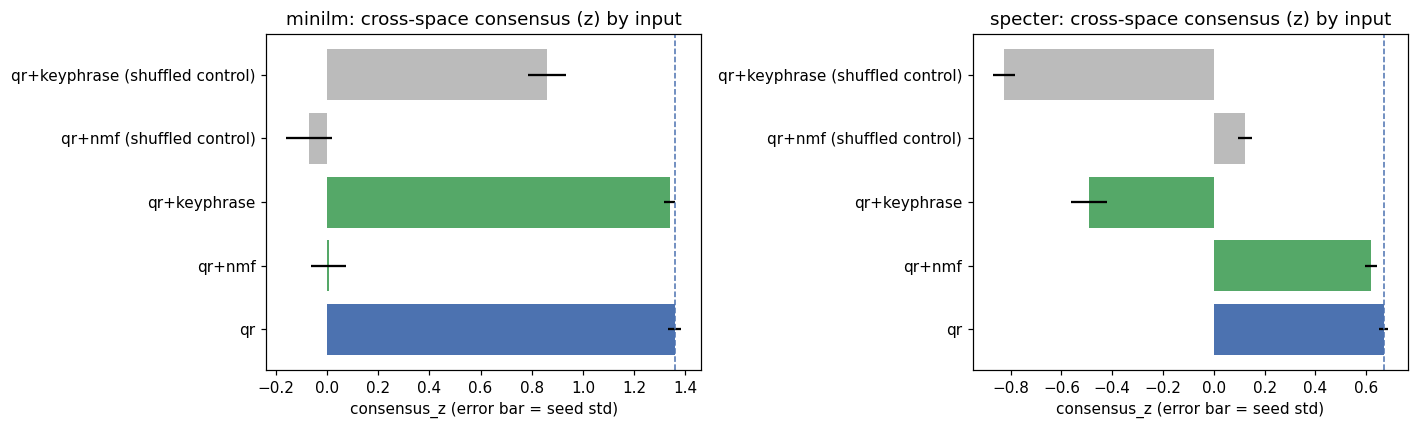


minilm: share of each baseline cluster that lands in each cluster of 'qr+nmf'


col_0,0,1,2,3,4,5,6,7,8,9,10,11,12,13
row_0,,,,,,,,,,,,,,
0,0.10,0.01,0.18,0.03,0.00,0.00,0.12,0.11,0.00,0.15,0.00,0.08,0.11,0.10
1,0.00,0.00,0.00,0.00,0.00,0.06,0.00,0.00,0.92,0.00,0.00,0.00,0.01,0.00
2,0.00,0.57,0.01,0.30,0.00,0.05,0.00,0.00,0.00,0.00,0.00,0.03,0.01,0.03
3,0.07,0.03,0.04,0.05,0.05,0.42,0.00,0.01,0.07,0.02,0.13,0.03,0.06,0.02
4,0.01,0.02,0.03,0.02,0.71,0.04,0.00,0.00,0.01,0.04,0.07,0.01,0.04,0.02


  [saved csv  ] experiment_outputs/15_E12_input_with_topic/E12_cluster_movement_minilm_qr_nmf.csv  (0.4 KB)

minilm: share of each baseline cluster that lands in each cluster of 'qr+keyphrase'


col_0,0,1,2,3,4
row_0,,,,,
0,0.00,0.00,0.01,0.98,0.01
1,0.96,0.00,0.00,0.00,0.04
2,0.00,0.96,0.00,0.01,0.03
3,0.01,0.01,0.01,0.01,0.97
4,0.00,0.00,0.83,0.03,0.14


  [saved csv  ] experiment_outputs/15_E12_input_with_topic/E12_cluster_movement_minilm_qr_keyphrase.csv  (0.1 KB)

specter: share of each baseline cluster that lands in each cluster of 'qr+nmf'


col_0,0,1,2,3,4
row_0,,,,,
0,0.83,0.03,0.03,0.01,0.10
1,0.04,0.00,0.02,0.83,0.10
2,0.03,0.00,0.00,0.03,0.94
3,0.00,0.06,0.93,0.01,0.00
4,0.05,0.50,0.36,0.05,0.04


  [saved csv  ] experiment_outputs/15_E12_input_with_topic/E12_cluster_movement_specter_qr_nmf.csv  (0.1 KB)

specter: share of each baseline cluster that lands in each cluster of 'qr+keyphrase'


col_0,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
row_0,,,,,,,,,,,,,,,
0,0.02,0.49,0.00,0.00,0.00,0.00,0.00,0.30,0.00,0.03,0.01,0.00,0.08,0.06,0.00
1,0.00,0.00,0.22,0.00,0.33,0.08,0.05,0.00,0.04,0.00,0.01,0.00,0.24,0.04,0.00
2,0.46,0.00,0.00,0.00,0.00,0.03,0.28,0.02,0.00,0.00,0.14,0.00,0.06,0.00,0.00
3,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.06,0.29,0.00,0.44,0.00,0.01,0.19
4,0.00,0.00,0.00,0.24,0.00,0.01,0.01,0.09,0.45,0.10,0.00,0.00,0.01,0.09,0.00


  [saved csv  ] experiment_outputs/15_E12_input_with_topic/E12_cluster_movement_specter_qr_keyphrase.csv  (0.4 KB)


In [59]:
fig, axes = plt.subplots(1, len(INPUT_TEST_ENCODERS), figsize=(6.5 * len(INPUT_TEST_ENCODERS), 4), squeeze=False)
for ax, enc in zip(axes[0], INPUT_TEST_ENCODERS):
    sub_e = E12[E12["encoder"] == enc]
    cols = ["#4C72B0" if v == "qr" else ("#BBBBBB" if "control" in v else "#55A868") for v in sub_e["variant"]]
    ax.barh(sub_e["variant"], sub_e["consensus_z"], xerr=sub_e["consensus_z_std"], color=cols)
    ax.axvline(float(sub_e[sub_e["variant"] == "qr"]["consensus_z"].iloc[0]), color="#4C72B0", ls="--", lw=1)
    ax.set_title(f"{enc}: cross-space consensus (z) by input"); ax.set_xlabel("consensus_z (error bar = seed std)")
fig.tight_layout()
save_fig(fig, "E12", "E12_input_consensus_bars", "Consensus z per input variant, with seed noise")

# How do clusters move when the topic is added? (rows = baseline cluster, columns = topic-input cluster)
for enc in INPUT_TEST_ENCODERS:
    for v in ["qr+nmf", "qr+keyphrase"]:
        ct = pd.crosstab(INPUT_LABELS[(enc, "qr")], INPUT_LABELS[(enc, v)], normalize="index").round(2)
        print(f"\n{enc}: share of each baseline cluster that lands in each cluster of '{v}'")
        display(ct)
        save_df(ct.reset_index(), "E12", f"E12_cluster_movement_{enc}_{v.replace('+', '_')}", f"Baseline cluster -> {v} cluster movement for {enc}")

## Stage 16 — Experiment E8: final clusters, keywords and representative records
Uses the **overall winner** from Stage 9 **and the input variant decided in Stage 15** (Query + Response unless a topic input passed all three adoption tests).
### 16.1 Final labels and cluster profile

Final configuration: minilm | kmeans | input: qr | encoder: minilm | clusters: 5


,cluster,n_queries,total_records,mean_unique_answers,mean_answer_words,share_of_queries_pct,share_of_records_pct
0,0,2250,2250,1.0,12.402222,45.0,45.0
1,1,408,408,1.0,20.936275,8.2,8.2
2,2,668,668,1.0,20.091317,13.4,13.4
3,3,1116,1116,1.0,8.147849,22.3,22.3
4,4,558,558,1.0,15.168459,11.2,11.2


  [saved csv  ] experiment_outputs/16_E8_final_clusters/E8_clustered_records.csv  (655.8 KB)
  [saved csv  ] experiment_outputs/16_E8_final_clusters/E8_cluster_profile.csv  (0.3 KB)
  [saved npy  ] experiment_outputs/16_E8_final_clusters/E8_final_labels.npy  (19.7 KB)
  [saved png  ] experiment_outputs/16_E8_final_clusters/E8_cluster_sizes.png  (19.4 KB)


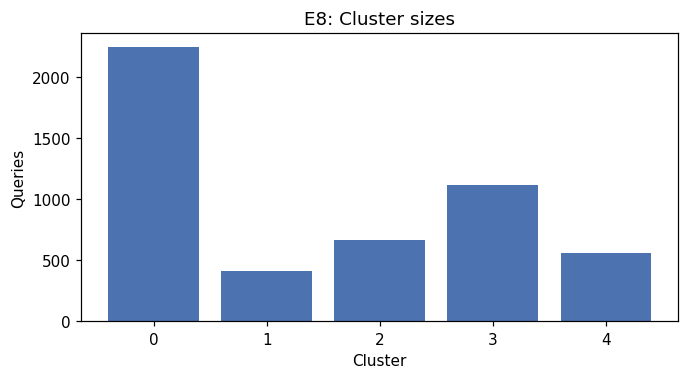

In [60]:
final_labels = FINAL_LABELS                                  # labels from Stage 15 (baseline Query+Response unless a topic input was adopted)
final_vectors = FINAL_VECTORS                                # the matching raw embeddings (used for "central" examples)
labelled_df = df.copy()
labelled_df["cluster"] = final_labels
print("Final configuration:", BEST_OVERALL["config"], "| input:", FINAL_INPUT, "| encoder:", FINAL_ENC, "| clusters:", len(np.unique(final_labels)))

profile = (labelled_df.groupby("cluster").agg(
    n_queries=("query_id", "count"), total_records=("record_count", "sum"),
    mean_unique_answers=("unique_answer_count", "mean"),
    mean_answer_words=("answer_text", lambda s: s.str.split().str.len().mean())).reset_index())
profile["share_of_queries_pct"] = (100 * profile["n_queries"] / profile["n_queries"].sum()).round(1)
profile["share_of_records_pct"] = (100 * profile["total_records"] / profile["total_records"].sum()).round(1)
display(profile)
save_df(labelled_df[["query_id", "representative_question", "answer_text", "record_count", "cluster"]], "E8", "E8_clustered_records", "Every row with its final cluster")
save_df(profile, "E8", "E8_cluster_profile", "Size and character of each cluster")
save_npy(final_labels, "E8", "E8_final_labels", "Final cluster labels (array)")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(profile["cluster"].astype(str), profile["n_queries"], color="#4C72B0")
ax.set_xlabel("Cluster"); ax.set_ylabel("Queries"); ax.set_title("E8: Cluster sizes")
save_fig(fig, "E8", "E8_cluster_sizes", "Bar chart of final cluster sizes")

  [saved png  ] experiment_outputs/16_E8_final_clusters/E8_umap_2d_map.png  (192.3 KB)


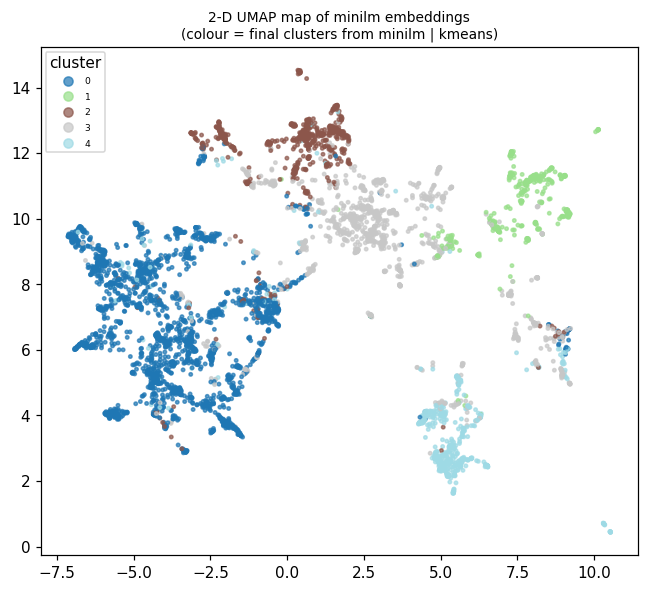

  [saved csv  ] experiment_outputs/16_E8_final_clusters/E8_umap_2d_coords.csv  (150.0 KB)


PosixPath('experiment_outputs/16_E8_final_clusters/E8_umap_2d_coords.csv')

In [61]:
# 2-D map for visualisation only (never used for scoring).
import umap as _umap_vis
coords2d = _umap_vis.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric="cosine", random_state=RANDOM_SEED).fit_transform(final_vectors)
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(coords2d[:, 0], coords2d[:, 1], c=final_labels, cmap="tab20", s=5, alpha=0.7)
ax.set_title(f"2-D UMAP map of {final_cfg['encoder']} embeddings\n(colour = final clusters from {BEST_OVERALL['config']})", fontsize=9)
if len(np.unique(final_labels)) <= 20:
    ax.legend(*sc.legend_elements(), title="cluster", fontsize=6, loc="best")
save_fig(fig, "E8", "E8_umap_2d_map", "2-D UMAP scatter coloured by final cluster")
save_df(pd.DataFrame({"query_id": df["query_id"], "x": coords2d[:, 0], "y": coords2d[:, 1], "cluster": final_labels}), "E8", "E8_umap_2d_coords", "2-D coordinates + cluster")

### 16.2 Keywords per cluster (TF-IDF)

In [62]:
cluster_keywords = top_terms(labelled_df["query_answer_text"].tolist(), final_labels, top_n=10)
display(cluster_keywords)
save_df(cluster_keywords, "E8", "E8_cluster_keywords", "Top TF-IDF terms per cluster")

,cluster,size,top_terms
0,0,2250,"water, spray, control, litre, litre water, ask..."
1,1,408,"kisan, contact, pm, pm kisan, office, agricult..."
2,2,668,"kg, fertilizer, urea, bigha, dose, mop, ssp, f..."
3,3,1116,"details, asking, explained, practices, explain..."
4,4,558,"daily, treatment, asking treatment, administer..."


  [saved csv  ] experiment_outputs/16_E8_final_clusters/E8_cluster_keywords.csv  (0.5 KB)


PosixPath('experiment_outputs/16_E8_final_clusters/E8_cluster_keywords.csv')

### 16.3 Representative records
* **Most frequent** – highest `record_count` (what farmers ask about most).
* **Most central** – closest to the cluster centroid (the "typical" member).

In [63]:
examples = []
for cluster_id in sorted(labelled_df["cluster"].unique()):
    member_idx = np.where(final_labels == cluster_id)[0]
    centroid = final_vectors[member_idx].mean(axis=0)
    centroid = centroid / (np.linalg.norm(centroid) + 1e-12)
    central_idx = member_idx[np.argsort(-(final_vectors[member_idx] @ centroid))[:3]]
    frequent_idx = labelled_df.loc[member_idx].sort_values("record_count", ascending=False).head(3).index
    for kind, idxs in [("most_central", central_idx), ("most_frequent", frequent_idx)]:
        for i in idxs:
            examples.append({"cluster": int(cluster_id), "view": kind, "query_id": df.loc[i, "query_id"],
                             "question": df.loc[i, "representative_question"], "answer": df.loc[i, "answer_text"][:500],
                             "record_count": int(df.loc[i, "record_count"])})
cluster_examples = pd.DataFrame(examples)
display(cluster_examples.head(12))
save_df(cluster_examples, "E8", "E8_representative_records", "Central and frequent examples per cluster")

,cluster,view,query_id,question,answer,record_count
0,0,most_central,Q_172531,asking about trhe control of pest in brinjal.,suggested to apply malathion 5oec 2 ml per lit...,1
1,0,most_central,Q_061254,asking about the control of fruit borer pest a...,advised to spray fluton 1 ml per 2 litres of w...,1
2,0,most_central,Q_083879,pest control,apply malathion 50ec 2ml/litre of water,1
3,0,most_frequent,Q_075996,asking about the control of leaf curl disease ...,suggested him to spray rogor 2ml/litre of water,1
4,0,most_frequent,Q_028049,asking about the vitamin for tomato,advised him to spray tracel 2 2gm/litre of water,1
5,0,most_frequent,Q_116261,becterial wilt problem in tomato,suggested to soil drenching with streptocyclin...,1
6,1,most_central,Q_080515,asking about the reason for not availing pm ki...,adhaar card and visit district agriculture office,1
7,1,most_central,Q_057532,asking about pm kisan samman nidhi yojana tran...,visit district agriculture office for further ...,1
8,1,most_central,Q_036577,asking about pm kisan samman nidhi yojana.,contact with your district agriculture office,1
9,1,most_frequent,Q_146125,asking about pm kisan samman nidhi yojana.,please wait.,1


  [saved csv  ] experiment_outputs/16_E8_final_clusters/E8_representative_records.csv  (4.5 KB)


PosixPath('experiment_outputs/16_E8_final_clusters/E8_representative_records.csv')

### 16.4 (Optional) Name the clusters with a small open-source LLM
A Hugging Face instruction model reads each cluster's keywords + 3 central questions and proposes a short topic name.
**Always check the names manually** — small LLMs can be wrong. If the model cannot load, the top-3 keywords are used instead.

In [64]:
cluster_names = {int(c): ", ".join(k.split(", ")[:3]) for c, k in zip(cluster_keywords["cluster"], cluster_keywords["top_terms"])}

if RUN_LLM_LABELS:
    try:
        from transformers import pipeline
        dtype = torch.float16 if DEVICE == "cuda" else torch.float32
        try:
            generator = pipeline("text-generation", model=LLM_LABEL_MODEL, device_map="auto", dtype=dtype)
        except TypeError:
            generator = pipeline("text-generation", model=LLM_LABEL_MODEL, device_map="auto", torch_dtype=dtype)
        for _, row in cluster_keywords.iterrows():
            cid = int(row["cluster"])
            questions = cluster_examples[(cluster_examples["cluster"] == cid) & (cluster_examples["view"] == "most_central")]["question"].tolist()
            prompt = (f"These farmer questions belong to one topic.\nKeywords: {row['top_terms']}\nExample questions:\n- " +
                      "\n- ".join(q[:150] for q in questions) + "\nGive a short topic name (max 5 words). Reply with the name only.")
            out = generator([{"role": "user", "content": prompt}], max_new_tokens=20, do_sample=False)
            cluster_names[cid] = out[0]["generated_text"][-1]["content"].strip().strip('"')
            print(f"cluster {cid}: {cluster_names[cid]}")
        del generator
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
    except Exception as exc:
        print("LLM naming skipped, using keyword names instead:", repr(exc))

names_df = pd.DataFrame({"cluster": list(cluster_names), "name": list(cluster_names.values())})
display(names_df)
save_df(names_df, "E8", "E8_cluster_names", "Human-readable cluster names (LLM or keyword fallback)")
labelled_df["cluster_name"] = labelled_df["cluster"].map(cluster_names)
save_df(labelled_df[["query_id", "representative_question", "answer_text", "cluster", "cluster_name", "record_count"]], "E8", "E8_final_dataset_with_names", "Final dataset: row + cluster + name")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

... (3 outputs left out)

cluster 0: Fruit Pest Control
cluster 1: PM KISAN
cluster 2: Fertilizer Dose Queries
cluster 3: Farmer Knowledge
cluster 4: Veterinary Treatment


,cluster,name
0,0,Fruit Pest Control
1,1,PM KISAN
2,2,Fertilizer Dose Queries
3,3,Farmer Knowledge
4,4,Veterinary Treatment


  [saved csv  ] experiment_outputs/16_E8_final_clusters/E8_cluster_names.csv  (0.1 KB)
  [saved csv  ] experiment_outputs/16_E8_final_clusters/E8_final_dataset_with_names.csv  (746.8 KB)


PosixPath('experiment_outputs/16_E8_final_clusters/E8_final_dataset_with_names.csv')

## Stage 17 — Experiment E13: how well differentiated are the final clusters?
Four independent views, because one view can mislead:

1. **Silhouette per cluster** (cosine, in the clustering space): average and the share of records that are *closer to another cluster than to their own* (negative silhouette).
2. **Centroid geometry:** cosine between cluster centres, and each record's *margin* = similarity to its own centre minus similarity to the nearest other centre. A small margin = boundary record.
3. **Hierarchy:** a dendrogram of the cluster centres shows which clusters would merge first.
4. **Cross-representation recoverability:** a classifier is trained to predict each record's cluster from (a) its **words** (TF-IDF) and (b) a **different encoder**. Clusters it confuses are clusters that look alike in that representation. This is more informative than testing inside the clustering space, where KMeans clusters are separable by construction.

Finally, a **differentiation scorecard** applies the same neutral measures to the best clustering of every encoder, so models can be compared on *how distinct their clusters are*, not just on the leaderboard rank.

,cluster,name,size,mean_silhouette,share_negative_silhouette,mean_own_centroid_cosine,mean_margin,nearest_cluster_by_centroid,centroid_cosine_to_nearest
0,0,Fruit Pest Control,2250,0.167797,0.047111,0.673216,0.171905,2,0.685853
1,1,PM KISAN,408,0.212170,0.012255,0.647474,0.235896,3,0.623567
2,2,Fertilizer Dose Queries,668,0.293779,0.000000,0.731840,0.202352,3,0.686805
3,3,Farmer Knowledge,1116,0.030022,0.391577,0.573238,0.125369,2,0.686805
4,4,Veterinary Treatment,558,0.055437,0.224014,0.569705,0.139730,0,0.677732


Overall: {'mean_silhouette': 0.145, 'share_negative_silhouette': 0.135, 'mean_margin': 0.167, 'share_nonpositive_margin': 0.022, 'mean_centroid_cosine': 0.594, 'max_centroid_cosine': 0.687}
  [saved csv  ] experiment_outputs/17_E13_differentiation/E13_per_cluster_separation.csv  (0.7 KB)
  [saved json ] experiment_outputs/17_E13_differentiation/E13_overall_differentiation.json  (0.2 KB)
  [saved png  ] experiment_outputs/17_E13_differentiation/E13_centroid_cosine_heatmap.png  (64.0 KB)


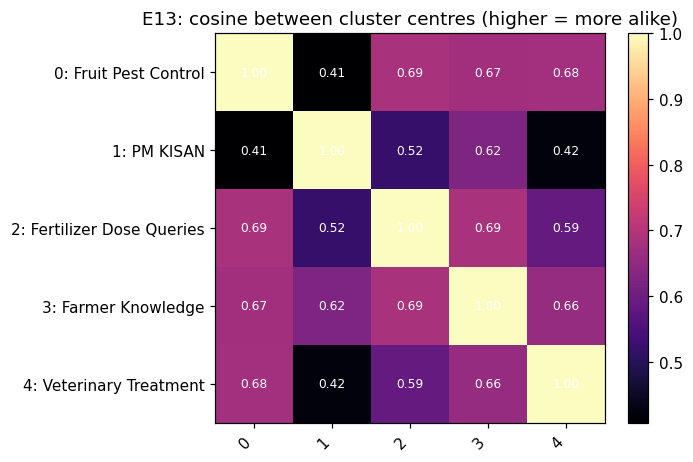

In [65]:
cname = lambda c: f"{c}: {cluster_names.get(int(c), '')}"[:34]
sil_final = silhouette_samples(final_vectors, final_labels, metric="cosine")
ids_f, cents_f, own_sim_f, nearest_f, margin_f = margin_to_other_centroids(final_vectors, final_labels)
cc_f = cents_f @ cents_f.T
cc_off = cc_f.copy(); np.fill_diagonal(cc_off, -np.inf)

sep_rows = []
for i, c in enumerate(ids_f):
    m = final_labels == c
    j = int(cc_off[i].argmax())
    sep_rows.append({"cluster": int(c), "name": cluster_names.get(int(c), ""), "size": int(m.sum()), "mean_silhouette": float(sil_final[m].mean()),
                     "share_negative_silhouette": float((sil_final[m] < 0).mean()), "mean_own_centroid_cosine": float(own_sim_f[m].mean()),
                     "mean_margin": float(margin_f[m].mean()), "nearest_cluster_by_centroid": int(ids_f[j]), "centroid_cosine_to_nearest": float(cc_f[i, j])})
separation = pd.DataFrame(sep_rows)
display(separation)
overall = differentiation_metrics(final_labels, final_vectors)
print("Overall:", {k: round(v, 3) for k, v in overall.items()})
save_df(separation, "E13", "E13_per_cluster_separation", "Silhouette, margin and nearest cluster for every final cluster")
save_json(overall, "E13", "E13_overall_differentiation", "Overall differentiation metrics of the final clustering")

fig = heatmap(pd.DataFrame(cc_f, index=[cname(c) for c in ids_f], columns=[str(c) for c in ids_f]), "E13: cosine between cluster centres (higher = more alike)", cmap="magma")
save_fig(fig, "E13", "E13_centroid_cosine_heatmap", "Cosine similarity between cluster centres")

  [saved png  ] experiment_outputs/17_E13_differentiation/E13_cluster_dendrogram.png  (61.7 KB)


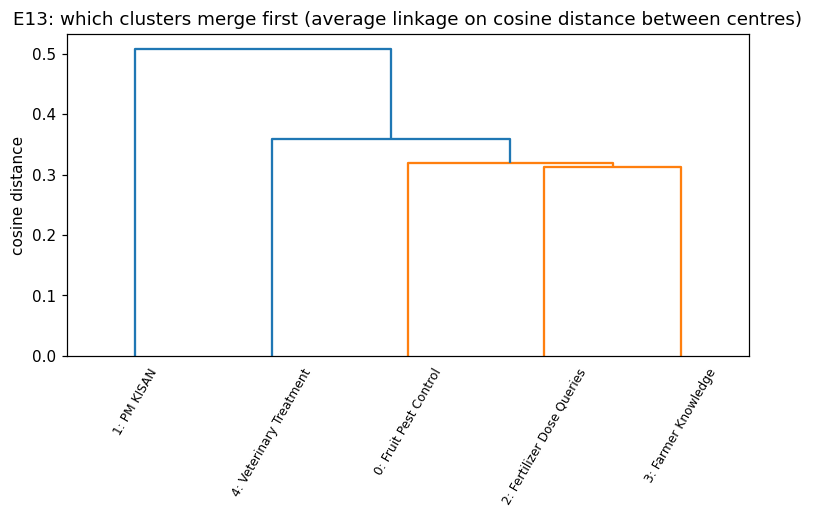

,left,right,distance,size
0,2,3,0.313195,2.0
1,0,5,0.319705,3.0
2,4,6,0.359196,4.0
3,1,7,0.507276,5.0


  [saved csv  ] experiment_outputs/17_E13_differentiation/E13_merge_order.csv  (0.1 KB)


PosixPath('experiment_outputs/17_E13_differentiation/E13_merge_order.csv')

In [66]:
from scipy.cluster.hierarchy import dendrogram
Z_c = linkage(cents_f, method="average", metric="cosine")
fig, ax = plt.subplots(figsize=(8, 3.8))
dendrogram(Z_c, labels=[cname(c) for c in ids_f], leaf_rotation=60, leaf_font_size=8, ax=ax)
ax.set_title("E13: which clusters merge first (average linkage on cosine distance between centres)"); ax.set_ylabel("cosine distance")
save_fig(fig, "E13", "E13_cluster_dendrogram", "Dendrogram of the final cluster centres")
merge_order = pd.DataFrame(Z_c, columns=["left", "right", "distance", "size"])
merge_order["left"] = merge_order["left"].astype(int); merge_order["right"] = merge_order["right"].astype(int)
display(merge_order.head(5))
save_df(merge_order, "E13", "E13_merge_order", "Scipy linkage matrix of cluster centres (leaf ids = position in sorted cluster list)")

,representation,accuracy,macro_f1
0,TF-IDF words,0.9304,0.918175
1,other encoder (e5),0.9464,0.937938


Chance level for the biggest cluster alone: 0.45
  [saved png  ] experiment_outputs/17_E13_differentiation/E13_confusion_words.png  (71.5 KB)


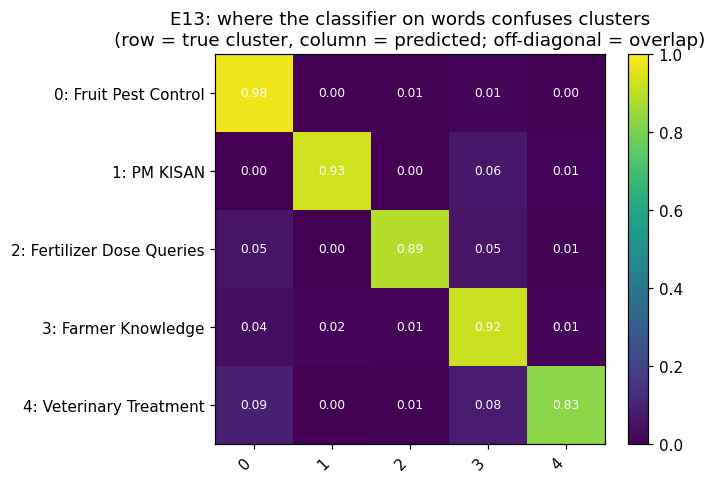

  [saved csv  ] experiment_outputs/17_E13_differentiation/E13_confusion_words_table.csv  (0.6 KB)


,precision,recall,f1-score,support
0: Fruit Pest Control,0.945,0.975,0.960,2250.0
1: PM KISAN,0.947,0.926,0.937,408.0
2: Fertilizer Dose Queries,0.947,0.888,0.917,668.0
3: Farmer Knowledge,0.885,0.919,0.902,1116.0
4: Veterinary Treatment,0.931,0.826,0.876,558.0


  [saved csv  ] experiment_outputs/17_E13_differentiation/E13_recoverability_words.csv  (0.5 KB)
  [saved png  ] experiment_outputs/17_E13_differentiation/E13_confusion_other_encoder.png  (72.1 KB)


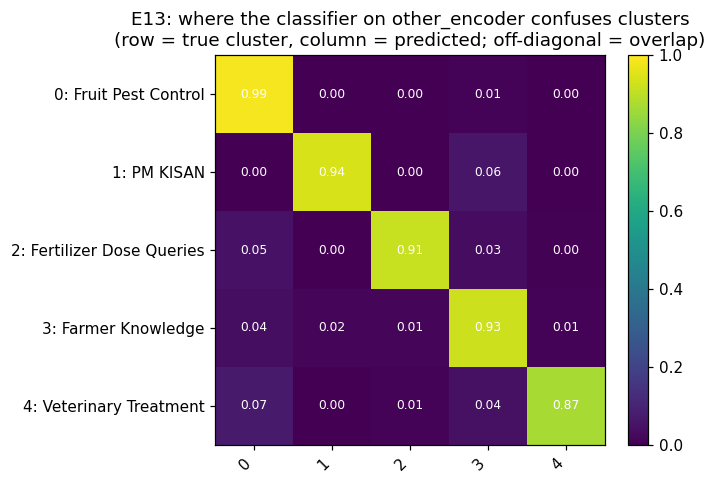

  [saved csv  ] experiment_outputs/17_E13_differentiation/E13_confusion_other_encoder_table.csv  (0.5 KB)


,precision,recall,f1-score,support
0: Fruit Pest Control,0.951,0.986,0.968,2250.0
1: PM KISAN,0.953,0.941,0.947,408.0
2: Fertilizer Dose Queries,0.958,0.915,0.936,668.0
3: Farmer Knowledge,0.918,0.926,0.922,1116.0
4: Veterinary Treatment,0.968,0.871,0.917,558.0


  [saved csv  ] experiment_outputs/17_E13_differentiation/E13_recoverability_other_encoder.csv  (0.5 KB)


In [67]:
# Recoverability from words (TF-IDF of Query+Response) and from a different encoder
rec_lex = recoverability(final_labels, sparse)
ALT_ENC = next((e for e in ranked["encoder"] if e in TRANSFORMER_SPACES and e != FINAL_ENC), None)
rec_alt = recoverability(final_labels, EMBEDDINGS[ALT_ENC]) if ALT_ENC else None
rec_rows = [{"representation": "TF-IDF words", "accuracy": rec_lex["accuracy"], "macro_f1": rec_lex["macro_f1"]}] if rec_lex else []
if rec_alt:
    rec_rows.append({"representation": f"other encoder ({ALT_ENC})", "accuracy": rec_alt["accuracy"], "macro_f1": rec_alt["macro_f1"]})
display(pd.DataFrame(rec_rows))
print("Chance level for the biggest cluster alone:", round(max_cluster_share(final_labels), 3))

confusions = {}
for rep_name, rec in [("words", rec_lex), ("other_encoder", rec_alt)]:
    if rec is None:
        continue
    cm = confusion_matrix(final_labels, rec["pred"], labels=ids_f)
    cmn = pd.DataFrame(cm / cm.sum(axis=1, keepdims=True), index=[cname(c) for c in ids_f], columns=[str(c) for c in ids_f])
    confusions[rep_name] = cmn
    fig = heatmap(cmn, f"E13: where the classifier on {rep_name} confuses clusters\n(row = true cluster, column = predicted; off-diagonal = overlap)", vmin=0, vmax=1)
    save_fig(fig, "E13", f"E13_confusion_{rep_name}", f"Normalised confusion matrix, classifier on {rep_name}")
    save_df(cmn.reset_index(), "E13", f"E13_confusion_{rep_name}_table", f"Confusion matrix values, classifier on {rep_name}")
    report = pd.DataFrame(classification_report(final_labels, rec["pred"], labels=ids_f, output_dict=True, zero_division=0)).T.iloc[:len(ids_f)]
    report.index = [cname(c) for c in ids_f]
    display(report[["precision", "recall", "f1-score", "support"]].round(3))
    save_df(report.reset_index().rename(columns={"index": "cluster"}), "E13", f"E13_recoverability_{rep_name}", f"Per-cluster precision/recall from {rep_name}")

In [68]:
# Differentiation scorecard: the SAME neutral measures for the best clustering of every encoder (and the best classical one)
rng_s = np.random.default_rng(RANDOM_SEED)
sc_idx = np.sort(rng_s.choice(len(df), size=min(2500, len(df)), replace=False))
score_rows = []
cands = [(enc, ranked[ranked["encoder"] == enc].iloc[0]["config"]) for enc in EMBEDDINGS if (ranked["encoder"] == enc).any()]
for enc, cfg_name in cands:
    labs = GRID[cfg_name]["labels"]
    if len(np.unique(labs[sc_idx])) < 2:
        continue
    neg, msil = [], []
    for ref_name, ref_vecs in EMBEDDINGS.items():
        if ref_name == enc:
            continue
        s_ = silhouette_samples(ref_vecs[sc_idx], labs[sc_idx], metric="cosine")
        neg.append((s_ < 0).mean()); msil.append(s_.mean())
    ts = cluster_term_sets(labs)
    ids_t = sorted(ts)
    jac = [jaccard(ts[a]["terms"], ts[b]["terms"]) for i, a in enumerate(ids_t) for b in ids_t[i + 1:]]
    rec_l = recoverability(labs, sparse)
    score_rows.append({"encoder": enc, "group": ENCODER_GROUP.get(enc, "classical"), "config": cfg_name, "k": GRID[cfg_name]["k"],
                       "neutral_mean_silhouette": float(np.mean(msil)), "neutral_share_negative_silhouette": float(np.mean(neg)),
                       "mean_top_term_jaccard": float(np.mean(jac)), "max_top_term_jaccard": float(np.max(jac)),
                       "lexical_recoverability_f1": rec_l["macro_f1"] if rec_l else np.nan})
scorecard = pd.DataFrame(score_rows).sort_values("neutral_mean_silhouette", ascending=False).reset_index(drop=True)
display(scorecard)
save_df(scorecard, "E13", "E13_model_differentiation_scorecard", "Neutral differentiation measures for the best clustering of every encoder")
print("Notes: 'neutral' = measured in every OTHER encoder's space on a fixed 2,500-record subset. Lower Jaccard = more distinct vocabularies.")
print("TF-IDF-based clusterings are lexical by construction, so their lexical_recoverability_f1 is inflated.")

,encoder,group,config,k,neutral_mean_silhouette,neutral_share_negative_silhouette,mean_top_term_jaccard,max_top_term_jaccard,lexical_recoverability_f1
0,minilm,general,minilm | kmeans,5,0.126548,0.204473,0.083643,0.136364,0.918175
1,agribert,agriculture,agribert+umap | ward,5,0.106328,0.206582,0.090215,0.136364,0.966624
2,agri_st,agriculture,agri_st+umap | ward,5,0.100940,0.237527,0.075546,0.190476,0.940931
3,specter,science,specter | kmeans,5,0.088410,0.278291,0.088431,0.219512,0.866308
4,gte,general,gte | kmeans,7,0.064241,0.272982,0.086244,0.282051,0.920470
5,e5,general,e5+umap | ward,25,0.048085,0.397636,0.087202,0.470588,0.919521
6,bge,general,bge+umap | gmm,10,0.045044,0.336582,0.081978,0.282051,0.940874
7,mpnet,general,mpnet+umap | kmeans,12,0.039118,0.350291,0.082044,0.315789,0.913950
8,glove_avg,classical,glove_avg | kmeans,7,0.020720,0.487018,0.121377,0.428571,0.833282
9,tfidf_svd,classical,tfidf_svd | ward,25,-0.028664,0.580800,0.077559,0.428571,0.916566


  [saved csv  ] experiment_outputs/17_E13_differentiation/E13_model_differentiation_scorecard.csv  (1.7 KB)
Notes: 'neutral' = measured in every OTHER encoder's space on a fixed 2,500-record subset. Lower Jaccard = more distinct vocabularies.
TF-IDF-based clusterings are lexical by construction, so their lexical_recoverability_f1 is inflated.


## Stage 18 — Experiment E14: where do clusters overlap, and why?
**Two notions of overlap, kept separate:**
* **Hard overlap (absolute):** a record whose similarity to another cluster's centre is *higher* than to its own (margin ≤ 0). If this is ~0 %, the clusters are cleanly separated in this space.
* **Ambiguity (relative):** the 25 % of records with the *smallest margin*. Quartiles keep the group size fixed and independent of the space's overall similarity level (E5/GTE have high baseline cosine), but they **always** flag some records, even in a perfect clustering. So every pair is labelled `HARD` or `soft` so relative weak spots are never mistaken for real overlap. **Core records** = the 25 % with the *largest* margin.

* **Flow matrix** `flow[a, b]` = ambiguous records of cluster `a` whose nearest other cluster is `b`.
* **Pair overlap rate** = (flow a→b + flow b→a) / (size a + size b).

**Reasons are tested, not guessed.** For every cluster pair four candidate causes are measured and tagged only when the pair is in the top quartile (P75) of all pairs **and** the pair has ambiguous records:

| Tag | Evidence measured |
|---|---|
| `shared_vocabulary` | Jaccard overlap of the two clusters' top-25 distinctive words |
| `close_centroids` | cosine between the two cluster centres |
| `mixed_content_queries` | share of the pair's ambiguous records that contain ≥ 2 distinctive words of *another* cluster (≥ 2 = more than one stray word) |
| `short_generic_queries` | share of the pair's ambiguous records whose query has no more distinctive words than the shortest quartile of all queries |

These tags are **diagnostic heuristics** derived from measurable evidence; the example records printed below let you verify each one by reading.

Margin quartiles: P25 = 0.0909, P75 = 0.2402 | records with margin <= 0 (nearer another centre): 2.2%
Context: 'ambiguous' is RELATIVE (weakest quarter of records), so it always flags some records. 'Hard' overlap (margin <= 0) is ABSOLUTE.
If the hard-overlap share is ~0%, the clusters are cleanly separated in this space and the analysis below describes relative weak spots only.


,0,1,2,3,4
0: Fruit Pest Control,0,0,195,126,114
1: PM KISAN,1,0,5,52,1
2: Fertilizer Dose Queries,62,1,0,63,4
3: Farmer Knowledge,115,99,159,0,62
4: Veterinary Treatment,79,2,21,89,0


  [saved csv  ] experiment_outputs/18_E14_overlap_reasons/E14_ambiguous_flow_matrix.csv  (0.2 KB)
  [saved png  ] experiment_outputs/18_E14_overlap_reasons/E14_flow_heatmap.png  (66.7 KB)


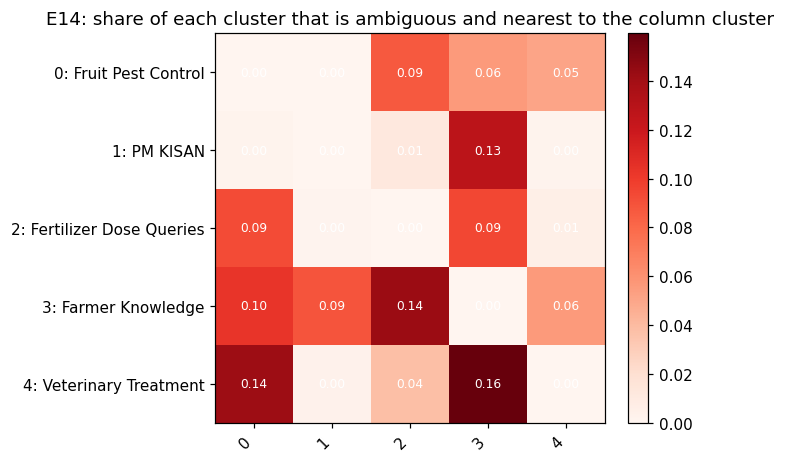

,cluster,name,size,ambiguous_share,hard_overlap_share
3,3,Farmer Knowledge,1116,0.389785,0.063620
4,4,Veterinary Treatment,558,0.342294,0.050179
2,2,Fertilizer Dose Queries,668,0.194611,0.001497
0,0,Fruit Pest Control,2250,0.193333,0.005333
1,1,PM KISAN,408,0.144608,0.000000


  [saved csv  ] experiment_outputs/18_E14_overlap_reasons/E14_ambiguous_share_per_cluster.csv  (0.4 KB)


PosixPath('experiment_outputs/18_E14_overlap_reasons/E14_ambiguous_share_per_cluster.csv')

In [69]:
labels_f = np.asarray(final_labels)
K_f = len(ids_f)
pos_of = {int(c): i for i, c in enumerate(ids_f)}
q25, q75 = np.percentile(margin_f, [25, 75])
ambiguous = margin_f <= q25
core = margin_f >= q75
hard = margin_f <= 0                      # records that are actually closer to ANOTHER cluster's centre than to their own
print(f"Margin quartiles: P25 = {q25:.4f}, P75 = {q75:.4f} | records with margin <= 0 (nearer another centre): {hard.mean():.1%}")
print("Context: 'ambiguous' is RELATIVE (weakest quarter of records), so it always flags some records. 'Hard' overlap (margin <= 0) is ABSOLUTE.")
print("If the hard-overlap share is ~0%, the clusters are cleanly separated in this space and the analysis below describes relative weak spots only.")

flow = np.zeros((K_f, K_f), dtype=int)
for i in np.where(ambiguous)[0]:
    flow[pos_of[int(labels_f[i])], pos_of[int(nearest_f[i])]] += 1
sizes_f = np.array([(labels_f == c).sum() for c in ids_f])
names_idx = [cname(c) for c in ids_f]

flow_df = pd.DataFrame(flow, index=names_idx, columns=[str(c) for c in ids_f])
display(flow_df)
save_df(flow_df.reset_index().rename(columns={"index": "from_cluster"}), "E14", "E14_ambiguous_flow_matrix", "Ambiguous records of each cluster by nearest other cluster")
fig = heatmap(pd.DataFrame(flow / sizes_f[:, None], index=names_idx, columns=[str(c) for c in ids_f]),
              "E14: share of each cluster that is ambiguous and nearest to the column cluster", cmap="Reds")
save_fig(fig, "E14", "E14_flow_heatmap", "Where ambiguous records of each cluster would go")

amb_share = pd.DataFrame({"cluster": ids_f, "name": [cluster_names.get(int(c), "") for c in ids_f], "size": sizes_f,
                          "ambiguous_share": flow.sum(axis=1) / sizes_f,
                          "hard_overlap_share": [hard[labels_f == c].mean() for c in ids_f]}).sort_values("ambiguous_share", ascending=False)
display(amb_share)
save_df(amb_share, "E14", "E14_ambiguous_share_per_cluster", "Which clusters have the blurriest boundaries (relative and hard)")

In [70]:
# What kind of records are ambiguous? Compare ambiguous vs core records on measurable text properties.
Xb = COH_INDEX["X"]                                                       # binary doc-term matrix (Query+Response)
terms_f = cluster_term_sets(labels_f, top_n=OVERLAP_TOP_TERMS)
q_vec = CountVectorizer(vocabulary=list(COH_INDEX["terms"]), binary=True, token_pattern=r"(?u)\b[a-z][a-z]+\b").fit(["x"])
q_content = np.asarray(q_vec.transform(df["representative_clean"]).sum(axis=1)).ravel()   # distinctive words in the query alone
generic_cut = np.percentile(q_content, 25)
is_generic = q_content <= generic_cut
own_pos_all = np.array([pos_of[int(c)] for c in labels_f])
hits = np.column_stack([np.asarray(Xb[:, terms_f[int(c)]["idx"]].sum(axis=1)).ravel() for c in ids_f])   # words of each cluster's vocabulary present in each record
own_hits = hits[np.arange(len(labels_f)), own_pos_all]
hits_other = hits.copy(); hits_other[np.arange(len(labels_f)), own_pos_all] = -1
multi_topic = hits_other.max(axis=1) >= 2

feat = pd.DataFrame({"query_words": df["representative_clean"].str.split().str.len().values, "answer_words": df["answer_text"].str.split().str.len().values,
                     "query_distinctive_words": q_content, "own_cluster_vocab_hits": own_hits, "unique_answer_count": df["unique_answer_count"].values,
                     "record_count": df["record_count"].values, "is_generic_query": is_generic.astype(int), "mixes_two_cluster_vocabularies": multi_topic.astype(int)})
from scipy.stats import mannwhitneyu
contrast = []
for col in feat.columns:
    a_, c_ = feat.loc[ambiguous, col].values, feat.loc[core, col].values
    try:
        u, p = mannwhitneyu(a_, c_, alternative="two-sided")
        r_rb = 2 * u / (len(a_) * len(c_)) - 1                  # rank-biserial effect size (-1..1; sign = ambiguous higher/lower)
    except ValueError:
        p, r_rb = np.nan, np.nan
    contrast.append({"property": col, "ambiguous_mean": a_.mean(), "core_mean": c_.mean(), "ambiguous_median": np.median(a_), "core_median": np.median(c_),
                     "effect_size_rank_biserial": r_rb, "p_value": p})
contrast_df = pd.DataFrame(contrast).sort_values("effect_size_rank_biserial", key=lambda s: s.abs(), ascending=False)
display(contrast_df.round(4))
save_df(contrast_df, "E14", "E14_ambiguous_vs_core_properties", "Which record properties distinguish boundary records from core records")
print("Reading guide: |effect size| ~0.1 small, ~0.3 medium, ~0.5 large. With ~1,250 records per group even tiny differences are 'significant', so rely on the effect size.")
OVERALL_AMB = {"generic": float(is_generic[ambiguous].mean()), "multi": float(multi_topic[ambiguous].mean())}
print("Overall ambiguous share that is generic:", round(OVERALL_AMB["generic"], 3), "| mixes two vocabularies:", round(OVERALL_AMB["multi"], 3))

,property,ambiguous_mean,core_mean,ambiguous_median,core_median,effect_size_rank_biserial,p_value
3,own_cluster_vocab_hits,2.8024,6.9136,3.0,7.0,-0.8078,0.0000
2,query_distinctive_words,3.3712,3.9624,3.0,4.0,-0.2143,0.0000
7,mixes_two_cluster_vocabularies,0.6720,0.4720,1.0,0.0,0.2000,0.0000
1,answer_words,12.6080,16.0528,9.0,11.0,-0.1651,0.0000
6,is_generic_query,0.5752,0.4480,1.0,0.0,0.1272,0.0000
0,query_words,6.8352,7.1176,6.0,7.0,-0.0704,0.0021
5,record_count,1.0000,1.0000,1.0,1.0,0.0000,1.0000
4,unique_answer_count,1.0000,1.0000,1.0,1.0,0.0000,1.0000


  [saved csv  ] experiment_outputs/18_E14_overlap_reasons/E14_ambiguous_vs_core_properties.csv  (0.7 KB)
Reading guide: |effect size| ~0.1 small, ~0.3 medium, ~0.5 large. With ~1,250 records per group even tiny differences are 'significant', so rely on the effect size.
Overall ambiguous share that is generic: 0.575 | mixes two vocabularies: 0.672


In [71]:
# Pair-level overlap table with evidence and reason tags
pair_rows = []
for i, a in enumerate(ids_f):
    for j in range(i + 1, K_f):
        b = ids_f[j]
        amb_ab = ambiguous & (labels_f == a) & (nearest_f == b)
        amb_ba = ambiguous & (labels_f == b) & (nearest_f == a)
        amb_pair = amb_ab | amb_ba
        hard_n = int((hard & (labels_f == a) & (nearest_f == b)).sum() + (hard & (labels_f == b) & (nearest_f == a)).sum())
        sa, sb = terms_f[int(a)], terms_f[int(b)]
        shared = [t for t in sa["terms"] if t in set(sb["terms"])]
        pair_rows.append({"cluster_a": int(a), "cluster_b": int(b), "name_a": cluster_names.get(int(a), ""), "name_b": cluster_names.get(int(b), ""),
                          "ambiguous_a_to_b": int(amb_ab.sum()), "ambiguous_b_to_a": int(amb_ba.sum()),
                          "overlap_rate": (amb_ab.sum() + amb_ba.sum()) / (sizes_f[i] + sizes_f[j]),
                          "hard_overlap_records": hard_n, "hard_overlap_rate": hard_n / (sizes_f[i] + sizes_f[j]),
                          "centroid_cosine": float(cc_f[i, j]), "top_term_jaccard": jaccard(sa["terms"], sb["terms"]),
                          "n_shared_top_terms": len(shared), "shared_terms": ", ".join(shared[:10]),
                          "share_mixed_vocab": float(multi_topic[amb_pair].mean()) if amb_pair.any() else np.nan,
                          "share_generic_query": float(is_generic[amb_pair].mean()) if amb_pair.any() else np.nan})
pairs = pd.DataFrame(pair_rows)
p75 = {c: pairs[c].quantile(0.75) for c in ["top_term_jaccard", "centroid_cosine", "share_mixed_vocab", "share_generic_query"]}
def tag_row(r):
    if r["ambiguous_a_to_b"] + r["ambiguous_b_to_a"] == 0:
        return "no ambiguous records between these clusters"
    tags = []
    if r["top_term_jaccard"] >= p75["top_term_jaccard"] and r["n_shared_top_terms"] > 0: tags.append("shared_vocabulary")
    if r["centroid_cosine"] >= p75["centroid_cosine"]: tags.append("close_centroids")
    if r["share_mixed_vocab"] >= p75["share_mixed_vocab"] and r["share_mixed_vocab"] > OVERALL_AMB["multi"]: tags.append("mixed_content_queries")
    if r["share_generic_query"] >= p75["share_generic_query"] and r["share_generic_query"] > OVERALL_AMB["generic"]: tags.append("short_generic_queries")
    return ", ".join(tags) if tags else "weak/no dominant cause"
pairs["reason_tags"] = pairs.apply(tag_row, axis=1)
pairs["severity"] = np.where(pairs["hard_overlap_rate"] > 0, "HARD: some records are closer to the other cluster",
                             np.where(pairs["overlap_rate"] > 0, "soft: boundary records only", "none"))
pairs = pairs.sort_values("overlap_rate", ascending=False).reset_index(drop=True)
display(pairs[["cluster_a", "cluster_b", "overlap_rate", "hard_overlap_rate", "severity", "centroid_cosine", "top_term_jaccard", "shared_terms", "reason_tags"]].head(12).round(3))
print("P75 thresholds used for tagging:", {k: round(v, 3) for k, v in p75.items()})
save_df(pairs, "E14", "E14_pair_overlap_table", "Every cluster pair: overlap rate, hard overlap, evidence and reason tags")

,cluster_a,cluster_b,overlap_rate,hard_overlap_rate,severity,centroid_cosine,top_term_jaccard,shared_terms,reason_tags
0,2,3,0.124,0.018,HARD: some records are closer to the other clu...,0.687,0.111,"recommended, suggested, regarding, rice, query","shared_vocabulary, close_centroids"
1,1,3,0.099,0.014,HARD: some records are closer to the other clu...,0.624,0.087,"agriculture, regarding, query, details",short_generic_queries
2,3,4,0.090,0.000,soft: boundary records only,0.657,0.087,"expert, query, regarding, suggested",short_generic_queries
3,0,2,0.088,0.004,HARD: some records are closer to the other clu...,0.686,0.136,"apply, advised, suggested, recommended, gm, query","shared_vocabulary, close_centroids, mixed_cont..."
4,0,3,0.072,0.006,HARD: some records are closer to the other clu...,0.675,0.064,"suggested, recommended, query",weak/no dominant cause
5,0,4,0.069,0.008,HARD: some records are closer to the other clu...,0.678,0.136,"ml, apply, suggested, days, gm, query","shared_vocabulary, close_centroids, mixed_cont..."
6,2,4,0.020,0.004,HARD: some records are closer to the other clu...,0.587,0.111,"apply, suggested, regarding, gm, query","shared_vocabulary, mixed_content_queries, shor..."
7,1,2,0.006,0.000,soft: boundary records only,0.519,0.042,"regarding, query",weak/no dominant cause
8,1,4,0.003,0.001,HARD: some records are closer to the other clu...,0.421,0.042,"regarding, query",weak/no dominant cause
9,0,1,0.000,0.000,soft: boundary records only,0.407,0.020,query,weak/no dominant cause


P75 thresholds used for tagging: {'top_term_jaccard': np.float64(0.111), 'centroid_cosine': np.float64(0.677), 'share_mixed_vocab': np.float64(0.779), 'share_generic_query': np.float64(0.693)}
  [saved csv  ] experiment_outputs/18_E14_overlap_reasons/E14_pair_overlap_table.csv  (2.9 KB)


PosixPath('experiment_outputs/18_E14_overlap_reasons/E14_pair_overlap_table.csv')

In [72]:
# The reasons in plain language + the records themselves (verify the tags by reading)
EXPLAIN = {"shared_vocabulary": "both clusters use many of the same distinctive words",
           "close_centroids": "their semantic centres are close in embedding space",
           "mixed_content_queries": "many boundary records contain vocabulary of both clusters (the question touches two topics)",
           "short_generic_queries": "many boundary records are short or generic queries with few distinctive words"}
top_pairs = pairs.head(TOP_PAIRS)
example_rows = []
for r in top_pairs.itertuples():
    a, b = r.cluster_a, r.cluster_b
    why = "; ".join(EXPLAIN[t] for t in r.reason_tags.split(", ") if t in EXPLAIN) or "no single dominant measurable cause"
    print(f"\n=== Clusters {a} ({r.name_a}) vs {b} ({r.name_b}) | overlap rate {r.overlap_rate:.1%} | hard overlap {r.hard_overlap_rate:.1%} | {r.severity} | tags: {r.reason_tags}")
    print("   Why:", why)
    print("   Shared distinctive words:", r.shared_terms or "(none)")
    for src, dst in [(a, b), (b, a)]:
        sel = np.where(ambiguous & (labels_f == src) & (nearest_f == dst))[0]
        for i in sel[np.argsort(margin_f[sel])][:3]:
            example_rows.append({"pair": f"{a}-{b}", "record_cluster": src, "nearest_other_cluster": dst, "margin": float(margin_f[i]),
                                 "question": df.loc[i, "representative_question"][:160], "answer": df.loc[i, "answer_text"][:260]})
            print(f"   [{src} -> nearest {dst}] Q: {df.loc[i, 'representative_question'][:110]}")
examples_overlap = pd.DataFrame(example_rows)
pairs["why_in_words"] = [("; ".join(EXPLAIN[t] for t in rt.split(", ") if t in EXPLAIN) or "no single dominant measurable cause") for rt in pairs["reason_tags"]]
save_df(pairs, "E14", "E14_pair_overlap_with_explanations", "Pair table with plain-language reasons")
save_df(examples_overlap, "E14", "E14_overlap_example_records", "The most ambiguous records for the top overlapping pairs")


=== Clusters 2 (Fertilizer Dose Queries) vs 3 (Farmer Knowledge) | overlap rate 12.4% | hard overlap 1.8% | HARD: some records are closer to the other cluster | tags: shared_vocabulary, close_centroids
   Why: both clusters use many of the same distinctive words; their semantic centres are close in embedding space
   Shared distinctive words: recommended, suggested, regarding, rice, query
   [2 -> nearest 3] Q: asking about fertilizer doses of sali rice
   [2 -> nearest 3] Q: asking for the fertilizer application of cabbage
   [2 -> nearest 3] Q: asking about the potato sotarage method
   [3 -> nearest 2] Q: query regarding pop of rapeseed.
   [3 -> nearest 2] Q: want to know regarding some good variety of peas
   [3 -> nearest 2] Q: asking about seed rate

=== Clusters 1 (PM KISAN) vs 3 (Farmer Knowledge) | overlap rate 9.9% | hard overlap 1.4% | HARD: some records are closer to the other cluster | tags: short_generic_queries
   Why: many boundary records are short or generic queries

PosixPath('experiment_outputs/18_E14_overlap_reasons/E14_overlap_example_records.csv')

,merge,names,overlap_rate,delta_consensus_z,delta_npmi,noise_z,noise_npmi,merge_supported_by_data
0,2 + 3,Fertilizer Dose Queries + Farmer Knowledge,0.1244,-0.0793,0.0127,0.0257,0.0001,False
1,1 + 3,PM KISAN + Farmer Knowledge,0.0991,-0.1374,-0.0402,0.0257,0.0001,False
2,3 + 4,Farmer Knowledge + Veterinary Treatment,0.0902,-0.2444,-0.0396,0.0257,0.0001,False


A merge is 'supported' only if neither independent measure drops by more than its seed-to-seed noise (E12).
  [saved csv  ] experiment_outputs/18_E14_overlap_reasons/E14_merge_test.csv  (0.5 KB)
  [saved png  ] experiment_outputs/18_E14_overlap_reasons/E14_overlap_drivers_scatter.png  (54.4 KB)


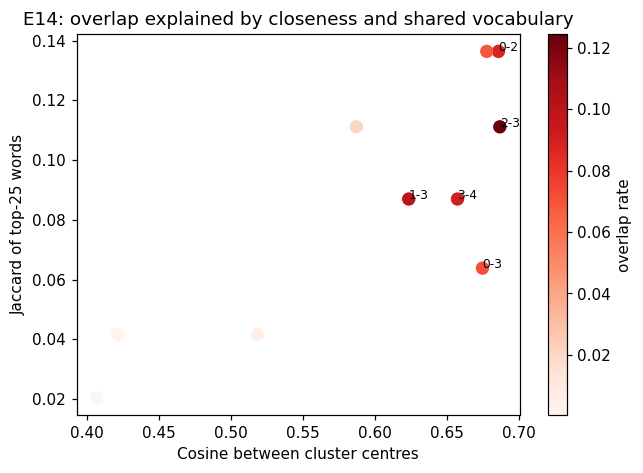

In [73]:
# Merge test: if two clusters really are one topic, merging them should not hurt the independent quality measures.
noise_row = E12[(E12["encoder"] == FINAL_ENC) & (E12["variant"] == FINAL_INPUT)]
NOISE_Z = float(noise_row["consensus_z_std"].iloc[0]) if len(noise_row) else np.nan
NOISE_NPMI = float(noise_row["npmi_main_std"].iloc[0]) if len(noise_row) else np.nan
z0, _ = zscore_consensus(labels_f, FINAL_ENC)
n0 = npmi_coherence(labels_f, COH_INDEX)
merge_rows = []
for r in pairs.head(3).itertuples():
    merged = np.where(labels_f == r.cluster_b, r.cluster_a, labels_f)
    z1, _ = zscore_consensus(merged, FINAL_ENC)
    n1 = npmi_coherence(merged, COH_INDEX)
    supported = bool((z1 - z0 >= -NOISE_Z) and (n1 - n0 >= -NOISE_NPMI)) if not np.isnan(NOISE_Z) else np.nan
    merge_rows.append({"merge": f"{r.cluster_a} + {r.cluster_b}", "names": f"{r.name_a} + {r.name_b}", "overlap_rate": r.overlap_rate,
                       "delta_consensus_z": z1 - z0, "delta_npmi": n1 - n0, "noise_z": NOISE_Z, "noise_npmi": NOISE_NPMI,
                       "merge_supported_by_data": supported})
merge_test = pd.DataFrame(merge_rows)
display(merge_test.round(4))
print("A merge is 'supported' only if neither independent measure drops by more than its seed-to-seed noise (E12).")
save_df(merge_test, "E14", "E14_merge_test", "Would merging the most overlapping pairs hurt quality?")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sc_ = ax.scatter(pairs["centroid_cosine"], pairs["top_term_jaccard"], c=pairs["overlap_rate"], s=60, cmap="Reds")
for r in pairs.head(5).itertuples():
    ax.annotate(f"{r.cluster_a}-{r.cluster_b}", (r.centroid_cosine, r.top_term_jaccard), fontsize=8)
ax.set_xlabel("Cosine between cluster centres"); ax.set_ylabel("Jaccard of top-25 words"); ax.set_title("E14: overlap explained by closeness and shared vocabulary")
fig.colorbar(sc_, label="overlap rate")
save_fig(fig, "E14", "E14_overlap_drivers_scatter", "Cluster pairs by centroid closeness and shared vocabulary, coloured by overlap rate")

## Stage 19 — Experiment E9: intrusion test (human review sheet + automatic check)
For each cluster, 5 genuine members and 1 **intruder** from another cluster are shown. If the cluster is coherent, a reviewer can spot the intruder.
* A **human review CSV** is produced (fill in `reviewer_selected_as_intruder`).
* An **automatic proxy** is also computed: the item least similar to the others in the winner's embedding space is predicted as the intruder. It is **not** a substitute for human review.

In [74]:
rng = np.random.default_rng(RANDOM_SEED)
clusters = sorted(labelled_df["cluster"].unique())
tasks, auto_rows, task_id = [], [], 1
if len(clusters) < 2:
    print("Only one cluster - intrusion test skipped.")
for target in clusters:
    if len(clusters) < 2:
        break
    members = labelled_df[labelled_df["cluster"] == target]
    if len(members) < INTRUSION_PER_CLUSTER:
        continue
    in_cluster = members.sample(n=INTRUSION_PER_CLUSTER, random_state=RANDOM_SEED)
    other = [c for c in clusters if c != target]
    intruder_cluster = int(rng.choice(other))
    intruder = labelled_df[labelled_df["cluster"] == intruder_cluster].sample(n=1, random_state=task_id).iloc[0]
    items = [(int(i), 0) for i in in_cluster.index] + [(int(intruder.name), 1)]
    items = [items[o] for o in rng.permutation(len(items))]
    for position, (row_idx, is_intruder) in enumerate(items, start=1):
        tasks.append({"task_id": task_id, "target_cluster_for_researcher_only": int(target), "item_position": position, "row_index": int(row_idx),
                      "question": labelled_df.loc[row_idx, "representative_question"], "answer": labelled_df.loc[row_idx, "answer_text"][:500],
                      "is_intruder_ground_truth_for_researcher_only": is_intruder, "reviewer_selected_as_intruder": "", "reviewer_notes": ""})
    idxs = [r for r, _ in items]
    sub = final_vectors[idxs]
    sim = sub @ sub.T
    mean_sim = (sim.sum(axis=1) - 1) / (len(idxs) - 1)
    predicted = int(np.argmin(mean_sim))
    truth = [flag for _, flag in items].index(1)
    auto_rows.append({"task_id": task_id, "target_cluster": int(target), "intruder_from_cluster": intruder_cluster,
                      "predicted_position": predicted + 1, "true_position": truth + 1, "auto_correct": int(predicted == truth)})
    task_id += 1

e9_review = pd.DataFrame(tasks)
e9_auto = pd.DataFrame(auto_rows)
if len(e9_review):
    display(e9_review.head(12)); display(e9_auto)
    print(f"Automatic intrusion accuracy: {e9_auto['auto_correct'].mean():.0%}  (random guessing = {1 / (INTRUSION_PER_CLUSTER + 1):.0%})")
    save_df(e9_review, "E9", "E9_human_intrusion_review", "Sheet for human reviewers (contains ground-truth columns - hide before sharing)")
    save_df(e9_auto, "E9", "E9_auto_intrusion_check", "Embedding-based intruder prediction per task")
    reviewer_view = e9_review.drop(columns=["target_cluster_for_researcher_only", "is_intruder_ground_truth_for_researcher_only", "row_index"])
    save_df(reviewer_view, "E9", "E9_reviewer_sheet_blind", "Blind version to send to reviewers")
    display(reviewer_view.head(6))

,task_id,target_cluster_for_researcher_only,item_position,row_index,question,answer,is_intruder_ground_truth_for_researcher_only,reviewer_selected_as_intruder,reviewer_notes
0,1,0,1,556,control measure of ulcer disease of fish,apply 'cifax' 100 ml per bigha of water area,0,,
1,1,0,2,1302,asking for control of leaf curling problem in ...,spray rogor 1.5 ml per litre of water,0,,
2,1,0,3,2046,query regarding application of vitamin in cabbage,recommended to spary tracel 2 2 gm per litr of...,0,,
3,1,0,4,3623,asking about the control measure to control la...,suggested to apply dithane m-45 2.5gram/litre ...,0,,
4,1,0,5,1081,asking about the pest control in ash gourd,apply decis 2ml /litres of water,0,,
5,1,0,6,4582,query regarding pmkisan.,9th installment payment stoped by state on req...,1,,
6,2,1,1,853,asking about the reqruitment procedure of vlew,suggest him to contact with district agricultu...,0,,
7,2,1,2,3175,asking about the govt. scheme of power tiller.,suggested to contact the ado.,0,,
8,2,1,3,281,asking about control of leaf curl in chillie,"spray rogor 2ml/l water , 3 times at 5 days in...",1,,
9,2,1,4,2575,asking for kisan credit card,explain in details.,0,,


,task_id,target_cluster,intruder_from_cluster,predicted_position,true_position,auto_correct
0,1,0,1,6,6,1
1,2,1,0,3,3,1
2,3,2,3,5,5,1
3,4,3,2,2,2,1
4,5,4,1,5,5,1


Automatic intrusion accuracy: 100%  (random guessing = 17%)
  [saved csv  ] experiment_outputs/19_E9_intrusion/E9_human_intrusion_review.csv  (4.1 KB)
  [saved csv  ] experiment_outputs/19_E9_intrusion/E9_auto_intrusion_check.csv  (0.1 KB)
  [saved csv  ] experiment_outputs/19_E9_intrusion/E9_reviewer_sheet_blind.csv  (3.8 KB)


,task_id,item_position,question,answer,reviewer_selected_as_intruder,reviewer_notes
0,1,1,control measure of ulcer disease of fish,apply 'cifax' 100 ml per bigha of water area,,
1,1,2,asking for control of leaf curling problem in ...,spray rogor 1.5 ml per litre of water,,
2,1,3,query regarding application of vitamin in cabbage,recommended to spary tracel 2 2 gm per litr of...,,
3,1,4,asking about the control measure to control la...,suggested to apply dithane m-45 2.5gram/litre ...,,
4,1,5,asking about the pest control in ash gourd,apply decis 2ml /litres of water,,
5,1,6,query regarding pmkisan.,9th installment payment stoped by state on req...,,


## Stage 20 — Final summary
### 20.1 Decision log (every choice and the rule that produced it)

In [75]:
decision_log = {
    "input_text": "question: <representative_question> answer: <all cleaned answers>  (Query + Response)",
    "k_range_tested": [K_RANGE[0], K_RANGE[-1]],
    "k_selection_rule": f"composite of normalised silhouette, -Davies-Bouldin, Calinski-Harabasz over K >= {K_SELECT_MIN_EFFECTIVE}; elbow (kneedle) and unconstrained silhouette reported as cross-checks",
    "umap_dim_chosen": UMAP_DIM,
    "umap_dim_rule": "max mean centred cosine silhouette in the ORIGINAL embedding space among UMAP dims " + str(UMAP_DIMS_TO_TEST),
    "hdbscan_rule": "min_cluster_size with max relative validity among candidates with >= K_SELECT_MIN clusters; noise assigned to nearest cluster centre",
    "ranking_rule": "mean rank of cross-space consensus (z), NPMI coherence, resampling stability (ARI), noise ratio; equal weights; clusterings with a cluster > " + f"{DEGENERATE_SHARE:.0%}" + " of rows excluded",
    "n_configurations": len(CONFIGS),
    "best_overall": {"config": BEST_OVERALL["config"], "k": int(BEST_OVERALL["k"])},
    "best_transformer": {"config": BEST_TRANSFORMER["config"], "k": int(BEST_TRANSFORMER["k"])},
    "best_classical": {"config": BEST_CLASSICAL["config"], "k": int(BEST_CLASSICAL["k"])},
    "best_domain_trained": {"config": BEST_DOMAIN["config"], "k": int(BEST_DOMAIN["k"])},
    "best_general": {"config": BEST_GENERAL["config"], "k": int(BEST_GENERAL["k"])},
    "best_of_requested_five": {"config": BEST_REQUESTED["config"], "k": int(BEST_REQUESTED["k"])},
    "final_input": FINAL_INPUT, "final_encoder": FINAL_ENC,
    "topic_rule": "adopt a topic input only if (1) consensus_z gain > seed noise, (2) stability not lower beyond its std, (3) beats its shuffled-topic control",
    "n_nmf_topics_chosen": int(N_TOPICS), "topic_encoder_for_keyphrases": TOPIC_ENCODER,
    "overlap_definition": "hard overlap = margin <= 0; ambiguity = lowest-quartile margin; reason tags only for pairs in the top quartile of the measured evidence",
    "elbow_clear_in_n_sweeps": int(elbow_sub["elbow_clear"].sum()), "n_sweeps_with_elbow": int(len(elbow_sub)),
    "elbow_agrees_with_final_k_in_n_sweeps": int(elbow_sub["elbow_agrees"].sum()),
}
display(pd.Series(decision_log, name="value").to_frame())
save_json(decision_log, "final", "decision_log", "Every analytic choice and the rule that produced it")

,value
input_text,question: <representative_question> answer: <a...
k_range_tested,"[2, 25]"
k_selection_rule,"composite of normalised silhouette, -Davies-Bo..."
umap_dim_chosen,20
umap_dim_rule,max mean centred cosine silhouette in the ORIG...
hdbscan_rule,min_cluster_size with max relative validity am...
ranking_rule,"mean rank of cross-space consensus (z), NPMI c..."
n_configurations,72
best_overall,"{'config': 'minilm | kmeans', 'k': 5}"
best_transformer,"{'config': 'minilm | kmeans', 'k': 5}"


  [saved json ] experiment_outputs/20_final_summary/decision_log.json  (1.8 KB)


PosixPath('experiment_outputs/20_final_summary/decision_log.json')

### 20.2 Master results table

In [76]:
summary_rows = [
    {"experiment": "E1", "finding": "KMeans final K per space (min-max)", "value": f"{e1_choice_df['k_final'].min()} - {e1_choice_df['k_final'].max()}"},
    {"experiment": "E1", "finding": "Spaces where unconstrained silhouette chose K < K_SELECT_MIN", "value": f"{int((e1_choice_df['k_silhouette_unconstrained'] < K_SELECT_MIN_EFFECTIVE).sum())} of {len(e1_choice_df)}"},
    {"experiment": "E2", "finding": "Chosen UMAP dimensionality", "value": str(UMAP_DIM)},
    {"experiment": "E3", "finding": "Configurations swept", "value": str(len(CONFIGS))},
    {"experiment": "E3", "finding": "Elbow within +-2 of chosen K", "value": f"{int(elbow_sub['elbow_agrees'].sum())} of {len(elbow_sub)} sweeps"},
    {"experiment": "E4", "finding": "Best overall", "value": f"{BEST_OVERALL['config']} (K={int(BEST_OVERALL['k'])}), mean rank {BEST_OVERALL['mean_rank']:.2f}"},
    {"experiment": "E4", "finding": "Best transformer-based", "value": f"{BEST_TRANSFORMER['config']} (K={int(BEST_TRANSFORMER['k'])}), mean rank {BEST_TRANSFORMER['mean_rank']:.2f}"},
    {"experiment": "E4", "finding": "Best classical", "value": f"{BEST_CLASSICAL['config']} (K={int(BEST_CLASSICAL['k'])}), mean rank {BEST_CLASSICAL['mean_rank']:.2f}"},
    {"experiment": "E4", "finding": "Mean consensus z: classical vs transformer", "value": f"{ranked[ranked['family']=='classical']['consensus_z'].mean():.2f} vs {ranked[ranked['family']=='transformer']['consensus_z'].mean():.2f}"},
    {"experiment": "E4", "finding": "Mean NPMI: classical vs transformer", "value": f"{ranked[ranked['family']=='classical']['npmi_coherence'].mean():.3f} vs {ranked[ranked['family']=='transformer']['npmi_coherence'].mean():.3f}"},
    {"experiment": "E5", "finding": "ARI of other text variants vs Query+Response", "value": ", ".join(f"{r.variant}={r.ARI_vs_main:.2f}" for r in e5_results.itertuples() if r.variant != "query_answer_text")},
    {"experiment": "E6", "finding": "Seed stability, full pipeline (mean ARI)", "value": f"{e6_results['ARI'].mean():.3f}"},
    {"experiment": "E6", "finding": "80% resampling ARI", "value": f"{BEST_OVERALL['stability_ari']:.3f}"},
    {"experiment": "E7", "finding": "Mean ARI between spaces' best clusterings", "value": f"{e7_results['ARI'].mean():.3f}"},
]
summary_rows += [
    {"experiment": "E4", "finding": "Best domain-trained / best general", "value": f"{BEST_DOMAIN['config']} (rank {BEST_DOMAIN['mean_rank']:.2f}) vs {BEST_GENERAL['config']} (rank {BEST_GENERAL['mean_rank']:.2f})"},
    {"experiment": "E10", "finding": "Best of the five requested models", "value": f"{BEST_REQUESTED['config']} (K={int(BEST_REQUESTED['k'])})"},
    {"experiment": "E11", "finding": "NMF topics chosen / key-phrase encoder", "value": f"{N_TOPICS} topics / {TOPIC_ENCODER}"},
    {"experiment": "E12", "finding": "Final input after the topic test", "value": f"{FINAL_INPUT} (encoder {FINAL_ENC})"},
    {"experiment": "E13", "finding": "Final clusters: mean silhouette / share of records nearer another cluster", "value": f"{overall['mean_silhouette']:.3f} / {overall['share_negative_silhouette']:.1%}"},
    {"experiment": "E14", "finding": "Most overlapping pair, severity and tags", "value": f"{pairs.iloc[0]['cluster_a']}-{pairs.iloc[0]['cluster_b']} ({pairs.iloc[0]['overlap_rate']:.1%}, {pairs.iloc[0]['severity'].split(':')[0]}): {pairs.iloc[0]['reason_tags']}"},
]
if len(e9_auto):
    summary_rows.append({"experiment": "E9", "finding": "Automatic intrusion accuracy", "value": f"{e9_auto['auto_correct'].mean():.0%}"})
summary_df = pd.DataFrame(summary_rows)
display(summary_df)
save_df(summary_df, "final", "master_summary", "One-line headline result per experiment")

,experiment,finding,value
0,E1,KMeans final K per space (min-max),5 - 25
1,E1,Spaces where unconstrained silhouette chose K ...,10 of 12
2,E2,Chosen UMAP dimensionality,20
3,E3,Configurations swept,72
4,E3,Elbow within +-2 of chosen K,18 of 63 sweeps
5,E4,Best overall,"minilm | kmeans (K=5), mean rank 19.62"
6,E4,Best transformer-based,"minilm | kmeans (K=5), mean rank 19.62"
7,E4,Best classical,"glove_avg | kmeans (K=7), mean rank 32.62"
8,E4,Mean consensus z: classical vs transformer,-0.98 vs 0.11
9,E4,Mean NPMI: classical vs transformer,0.159 vs 0.178


  [saved csv  ] experiment_outputs/20_final_summary/master_summary.csv  (1.3 KB)


PosixPath('experiment_outputs/20_final_summary/master_summary.csv')

### 20.3 Manifest of everything that was saved

In [77]:
manifest_df = save_manifest()
display(manifest_df.groupby("stage").agg(files=("file", "count"), size_kb=("size_kb", "sum")))
display(manifest_df[["stage", "file", "kind", "size_kb", "note"]])

,files,size_kb
stage,,
00_setup,1,1.6
01_raw_data,6,192.2
02_sampling,2,44.3
03_cleaning,3,925.0
04_text_representations,4,2805.1
05_embeddings,32,256760.4
06_E1_k_selection_kmeans,3,848.4
07_E2_umap_projection,13,3600.5
08_E3_full_k_sweeps,6,1020.6


,stage,file,kind,size_kb,note
0,01_raw_data,raw_head.csv,csv,142.6,First 100 raw rows
1,01_raw_data,raw_dtypes.csv,csv,0.3,Column data types
2,01_raw_data,dataset_audit.json,json,0.6,Dataset health audit
3,01_raw_data,missing_values.csv,csv,0.3,Missing values per column
4,01_raw_data,numeric_summary.csv,csv,0.1,Describe() of count columns
...,...,...,...,...,...
138,19_E9_intrusion,E9_human_intrusion_review.csv,csv,4.1,Sheet for human reviewers (contains ground-tru...
139,19_E9_intrusion,E9_auto_intrusion_check.csv,csv,0.1,Embedding-based intruder prediction per task
140,19_E9_intrusion,E9_reviewer_sheet_blind.csv,csv,3.8,Blind version to send to reviewers
141,20_final_summary,decision_log.json,json,1.8,Every analytic choice and the rule that produc...


### 20.4 Zip and download

In [78]:
zip_path = shutil.make_archive("agricultural_clustering_results_v2", "zip", OUTPUT_DIR)
print("Created:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Not in Colab - find the zip in the working directory.")

Created: /content/agricultural_clustering_results_v2.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 🌾 KCC NLP Phase 3 — Hierarchical Clustering Extension

**Notebook:** `NLP_Phase3_Hierarchical.ipynb`  
**Extends:** `NLP_Phase3.ipynb` (Stages 0–20)

---

## What this notebook does

This notebook implements a **two-level hierarchical clustering** framework on
top of the flat-clustering results produced in the original Phase-3 notebook:

| Level | Method | Basis |
|-------|--------|-------|
| **Parent** | NMF topic assignment (argmax of W matrix) | Semantic topic model |
| **Child**  | MiniBatchKMeans on L2-normalised embeddings | Embedding space |

### Expected variables from the original notebook

| Variable | Description |
|----------|-------------|
| `df` | Sampled DataFrame (≤ MAX_ROWS rows) |
| `df_full` | Full un-sampled DataFrame |
| `EMBEDDINGS` | Dict of numpy arrays |
| `NMF_FITS` | Dict `{n_topics: (nmf_model, W_matrix)}` |
| `N_TOPICS` | Best NMF topic count |
| `nmf_topic_words` | Dict `{topic_id: 'word1 word2 ...'}` |
| `FINAL_ENC` | Best encoder key from flat clustering |
| `OUTPUT_DIR` | `pathlib.Path` for saving outputs |
| `RANDOM_SEED` | Integer (42) |
| `STAGES` | Dict of stage keys → folder names |
| `save_fig`, `save_df`, `save_json`, `stage_folder` | Helper functions |
| `tfidf`, `sparse`, `terms` | TF-IDF vectoriser, sparse matrix, term names |
| `main_texts` | List of `query_answer_text` strings |
| `ENCODER_GROUP` | Dict mapping encoder key → group |
| `CLASSICAL_AVAILABLE` | List of classical embedding keys |
| `TRANSFORMER_SPACES` | List of transformer encoder keys |

> ⚠️ **Run the original notebook first** before executing any cell below.


## Section H1 — Configuration

In [79]:
# ── Hierarchical Clustering Configuration ──────────────────────────────────
HC_MIN_PARENT_SIZE    = 100   # min questions per parent to attempt child clustering
HC_CHILD_K_CANDIDATES = [2, 3, 4, 5, 6, 8, 10]  # K values to test
HC_TOP_TERMS          = 10   # TF-IDF terms per cluster label
HC_REPR_QUESTIONS     = 5    # representative questions per child cluster
HC_SIL_SAMPLE         = 1000 # max sample for silhouette (speed vs accuracy)

# Register the new stage so save_fig / save_df helpers work
STAGES['hc'] = '21_hierarchical_clustering'
hc_folder = stage_folder('hc')
hc_folder.mkdir(parents=True, exist_ok=True)

print('Hierarchical clustering configuration set.')
print(f'  HC_MIN_PARENT_SIZE    = {HC_MIN_PARENT_SIZE}')
print(f'  HC_CHILD_K_CANDIDATES = {HC_CHILD_K_CANDIDATES}')
print(f'  HC_TOP_TERMS          = {HC_TOP_TERMS}')
print(f'  HC_REPR_QUESTIONS     = {HC_REPR_QUESTIONS}')
print(f'  HC_SIL_SAMPLE         = {HC_SIL_SAMPLE}')
print()
print(f'Parent topics from NMF : {N_TOPICS}')
print(f'Best flat encoder      : {FINAL_ENC}')
print(f'Representations loaded : {list(EMBEDDINGS.keys())}')
print(f'Output folder          : {hc_folder}')


Hierarchical clustering configuration set.
  HC_MIN_PARENT_SIZE    = 100
  HC_CHILD_K_CANDIDATES = [2, 3, 4, 5, 6, 8, 10]
  HC_TOP_TERMS          = 10
  HC_REPR_QUESTIONS     = 5
  HC_SIL_SAMPLE         = 1000

Parent topics from NMF : 16
Best flat encoder      : minilm
Representations loaded : ['tfidf_svd', 'doc2vec', 'glove_avg', 'minilm', 'mpnet', 'e5', 'bge', 'gte', 'agri_st', 'agribert', 'scibert', 'specter']
Output folder          : experiment_outputs/21_hierarchical_clustering


In [80]:
# ── DATASET DISCLOSURE ─────────────────────────────────────────────────────
_n_sample = len(df)
_n_full   = len(df_full) if 'df_full' in dir() else _n_sample

if _n_sample < _n_full:
    print('=' * 75)
    print(f'DISCLOSURE: This analysis uses a SAMPLE of {_n_sample:,} rows (MAX_ROWS={MAX_ROWS})')
    print(f'Sampling fraction: {_n_sample / _n_full:.1%}')
    print(f'All percentages are relative to the {_n_sample:,}-row sample,')
    print(f'not the full {_n_full:,}-row population.')
    print('=' * 75)
else:
    print('=' * 75)
    print(f'DATASET SCOPE: This analysis uses the ENTIRE dataset of {_n_sample:,} rows.')
    print('100% of the dataset is processed — no sampling applied.')
    print('All percentages reflect the complete population of agricultural queries.')
    print('=' * 75)


DISCLOSURE: This analysis uses a SAMPLE of 5,000 rows (MAX_ROWS=5000)
Sampling fraction: 2.8%
All percentages are relative to the 5,000-row sample,
not the full 177,169-row population.


## Section H2 — Dataset Audit

In [81]:
# ── Dataset Audit ──────────────────────────────────────────────────────────
import pandas as pd
import numpy as np

_n_sample = len(df)
_n_full   = len(df_full) if 'df_full' in dir() else _n_sample

audit_rows = []
audit_rows.append({'metric': 'Total rows in df',          'value': f'{_n_sample:,}' + (' (Entire Dataset)' if _n_sample == _n_full else ' (Sample)')})
audit_rows.append({'metric': 'Total rows in df_full',     'value': _n_full})
audit_rows.append({'metric': 'MAX_ROWS setting',          'value': 'Entire Dataset' if MAX_ROWS is None else str(MAX_ROWS)})
audit_rows.append({'metric': 'Sampling applied',          'value': 'No (Full Dataset)' if _n_sample == _n_full else 'Yes'})

if 'representative_question' in df.columns:
    n_unique_q = df['representative_question'].nunique()
    audit_rows.append({'metric': 'Unique representative questions', 'value': n_unique_q})
    audit_rows.append({'metric': 'Duplicate representative questions', 'value': _n_sample - n_unique_q})

for col in ['query_answer_text', 'representative_question', 'topic_nmf']:
    if col in df.columns:
        audit_rows.append({'metric': f'Missing: {col}', 'value': df[col].isna().sum()})

if 'record_count' in df.columns:
    total_rc = df['record_count'].sum()
    all_one  = (df['record_count'] == 1).all()
    audit_rows.append({'metric': 'Sum of record_count',              'value': total_rc})
    audit_rows.append({'metric': 'All record_count == 1 (synthetic)','value': str(all_one)})
    audit_rows.append({'metric': 'Max record_count',                 'value': df['record_count'].max()})
    audit_rows.append({'metric': 'Min record_count',                 'value': df['record_count'].min()})
else:
    audit_rows.append({'metric': 'record_count column', 'value': 'NOT FOUND'})

audit_rows.append({'metric': 'Embedding spaces loaded', 'value': len(EMBEDDINGS)})
for k, v in EMBEDDINGS.items():
    audit_rows.append({'metric': f'  {k} shape', 'value': str(v.shape)})

audit_df = pd.DataFrame(audit_rows)
print(audit_df.to_string(index=False))

_audit_path = hc_folder / 'hc_dataset_audit.csv'
audit_df.to_csv(_audit_path, index=False)
print(f'\nSaved: {_audit_path}')


                            metric          value
                  Total rows in df 5,000 (Sample)
             Total rows in df_full         177169
                  MAX_ROWS setting           5000
                  Sampling applied            Yes
   Unique representative questions           4200
Duplicate representative questions            800
        Missing: query_answer_text              0
  Missing: representative_question              0
                Missing: topic_nmf              0
               Sum of record_count           5000
 All record_count == 1 (synthetic)           True
                  Max record_count              1
                  Min record_count              1
           Embedding spaces loaded             12
                   tfidf_svd shape    (5000, 100)
                     doc2vec shape    (5000, 100)
                   glove_avg shape    (5000, 100)
                      minilm shape    (5000, 384)
                       mpnet shape    (5000, 768)


### Dataset Audit Notes

- **record_count** represents the number of calls that mapped to this
  representative question. If `record_count == 1` for every row, the data
  was likely pre-aggregated or synthetic.
- Percentages throughout this notebook are always relative to the **sample**
  (`len(df)`) unless explicitly stated otherwise.
- The NMF model was fitted on this same sample, so parent-topic proportions
  reflect the sample distribution.


## Section H3 — Parent Topic Assignment

In [82]:
# ── Parent Topic Assignment via NMF argmax ─────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

# Retrieve NMF results
nmf_model, W_nmf = NMF_FITS[N_TOPICS]
H_nmf = nmf_model.components_   # shape: (N_TOPICS, n_vocab)

# Parent topic for each row = argmax of W row
parent_topics = np.argmax(W_nmf, axis=1)
df = df.copy()
df['parent_topic'] = parent_topics

print(f'Parent topics assigned using NMF (n_topics={N_TOPICS}).')
print(f'Value counts:\n{df["parent_topic"].value_counts().sort_index()}')


Parent topics assigned using NMF (n_topics=16).
Value counts:
parent_topic
0     258
1     442
2     250
3     330
4     384
5     376
6     405
7     319
8     357
9     308
10    266
11    342
12    258
13    218
14    295
15    192
Name: count, dtype: int64


In [83]:
# ── Extract NMF Topic Keywords & Automated Agricultural Domain Taxonomy ──────
# 1. Fix vocabulary lookup: use topic_terms (from topic_vec) which NMF was trained on.
if 'topic_terms' in globals():
    vocab_for_nmf = topic_terms
elif 'topic_vec' in globals():
    vocab_for_nmf = np.array(topic_vec.get_feature_names_out())
else:
    vocab_for_nmf = np.array(tfidf.get_feature_names_out())

nmf_topic_keywords = {}   # {topic_id: 'word1, word2, ...'}
for t_id in range(N_TOPICS):
    top_idx = H_nmf[t_id].argsort()[::-1][:HC_TOP_TERMS]
    words   = [vocab_for_nmf[i] for i in top_idx if i < len(vocab_for_nmf)]
    nmf_topic_keywords[t_id] = ', '.join(words)

# ==============================================================================
# AUTOMATED DOMAIN CLASSIFIER (Connecting Phase 2 Ontology with Phase 3 NMF)
# Pre-defined canonical agricultural domain taxonomy from Phase 2:
# - Crop Protection (Pests & Diseases)
# - Nutrient Management (Fertilizers & Soil Health)
# - Crop Cultivation & Agronomy (Sowing, Seeds, Cultural Practices)
# - Soil & Water Management (Irrigation, Testing, Land prep)
# - Animal Husbandry & Veterinary (Livestock, Cattle, Poultry)
# - Fisheries & Aquaculture (Fish farming, Carp, Ponds)
# - Agricultural Schemes & Finance (PM-Kisan, KCC, Subsidies)
# ==============================================================================
from collections import Counter

CANONICAL_AGRICULTURAL_DOMAINS = {
    "Crop Protection (Pests & Insects)": [
        "pest", "pests", "insect", "insects", "malathion", "rogor", "spray", "spraying",
        "borer", "fly", "aphid", "aphids", "caterpillar", "whitefly", "classic", "tricel",
        "fruit fly", "stem borer", "leaf folder", "saw fly", "infestation", "larva", "beetle"
    ],
    "Crop Protection (Diseases & Pathology)": [
        "disease", "diseases", "blight", "wilt", "rot", "curl", "fungus", "fungal",
        "bacterial", "indofil", "bavistin", "ridomil", "saaf", "anthracnose", "canker",
        "damping", "leaf curl", "early blight", "late blight", "fruit rot", "mildew", "spot"
    ],
    "Nutrient Management & Fertilizers": [
        "fertilizer", "fertilizers", "urea", "dap", "mop", "ssp", "npk", "dose", "bigha",
        "nutrient", "nutrients", "nitrogen", "phosphorus", "potash", "zinc", "boron",
        "borax", "tracel", "micronutrient", "micronutrients", "deficiency", "top dressing",
        "basal", "foliar", "application", "manure", "compost"
    ],
    "Crop Cultivation & Agronomy": [
        "cultivation", "cultural", "practices", "sowing", "seed", "seeds", "variety",
        "varieties", "planting", "spacing", "nursery", "transplanting", "harvesting",
        "germination", "hybrid", "ranjit", "bahadur", "ganga", "package", "field", "season"
    ],
    "Soil & Water Management": [
        "soil", "water", "irrigation", "drainage", "soil testing", "testing", "land",
        "moisture", "greenhouse", "polyhouse", "rain", "rainfall", "summer", "monsoon"
    ],
    "Animal Husbandry & Veterinary": [
        "animal", "animals", "cow", "cattle", "goat", "poultry", "chicken", "duck",
        "pig", "swine", "broiler", "livestock", "diarrhea", "diarrhoea", "treatment",
        "deworming", "panacur", "veterinary", "egg", "production", "disease", "calf"
    ],
    "Fisheries & Aquaculture": [
        "fishery", "fisheries", "fish", "carp", "pond", "culture", "water", "fingerling",
        "stocking", "feed", "aquaculture"
    ],
    "Agricultural Schemes & Finance": [
        "scheme", "schemes", "pm kisan", "pmkisan", "kisan credit card", "kcc", "loan",
        "bank", "subsidy", "subsidies", "insurance", "samman nidhi", "yojana", "office", "contact"
    ]
}

# Automatic Domain Classifier function
def auto_classify_nmf_topic(topic_words_list):
    domain_scores = Counter()
    for domain, kws in CANONICAL_AGRICULTURAL_DOMAINS.items():
        for w in topic_words_list:
            w_clean = w.strip().lower()
            for kw in kws:
                if kw in w_clean or w_clean in kw:
                    domain_scores[domain] += 1
    if domain_scores:
        best_domain = domain_scores.most_common(1)[0][0]
    else:
        best_domain = "General Agricultural Advisory"
    # Select top distinctive terms (filtering generic filler words)
    clean_kw = [w.title() for w in topic_words_list if w.lower() not in ['water', 'spray', 'lit', 'ml', 'apply', 'suggested', 'advised', 'dose']][:3]
    desc = ' / '.join(clean_kw) if clean_kw else 'Advisory'
    return best_domain, f"{best_domain}: {desc}"

# Apply automated classification across all NMF topics
nmf_topic_domains = {}
nmf_topic_labels  = {}

for t_id in range(N_TOPICS):
    t_words = [w.strip() for w in nmf_topic_keywords[t_id].split(',') if w.strip()]
    domain_theme, auto_label = auto_classify_nmf_topic(t_words)
    nmf_topic_domains[t_id] = domain_theme
    nmf_topic_labels[t_id]  = auto_label

print('Automated Agricultural Domain Classification (Bridging Phase 2 & Phase 3):')
print('=' * 85)
for t_id in range(N_TOPICS):
    print(f'  Topic {t_id:2d} -> [{nmf_topic_domains[t_id]}]')
    print(f'            Label   : {nmf_topic_labels[t_id]}')
    print(f'            Keywords: {nmf_topic_keywords[t_id]}')


Automated Agricultural Domain Classification (Bridging Phase 2 & Phase 3):
  Topic  0 -> [Crop Protection (Pests & Insects)]
            Label   : Crop Protection (Pests & Insects): Malathion / Ec / Fruit
            Keywords: malathion, ec, fruit, ml, litre, water, fly, gourd, pest, problem
  Topic  1 -> [Nutrient Management & Fertilizers]
            Label   : Nutrient Management & Fertilizers: Kg / Bigha / Urea
            Keywords: kg, bigha, urea, dose, fertilizer, mop, ssp, apply, recommended, land
  Topic  2 -> [Crop Cultivation & Agronomy]
            Label   : Crop Cultivation & Agronomy: Explained / Details / Cultural
            Keywords: explained, details, cultural, practices, practice, package, asked, culture, pond, management
  Topic  3 -> [Crop Protection (Pests & Insects)]
            Label   : Crop Protection (Pests & Insects): Days / Interval / Times
            Keywords: days, interval, times, spray, recommended, water, sprays, time, saaf, evening
  Topic  4 -> [Cro

In [84]:
# ── Parent distribution table ───────────────────────────────────────────────
_total_q  = len(df)
_total_rc = df['record_count'].sum() if 'record_count' in df.columns else _total_q

parent_dist_rows = []
for t_id in range(N_TOPICS):
    mask   = df['parent_topic'] == t_id
    n_q    = mask.sum()
    pct_q  = n_q / _total_q * 100
    s_rc   = df.loc[mask, 'record_count'].sum() if 'record_count' in df.columns else n_q
    pct_rc = s_rc / _total_rc * 100
    parent_dist_rows.append({
        'parent_topic_id'      : t_id,
        'parent_topic_keywords': nmf_topic_keywords[t_id],
        'parent_topic_label'   : nmf_topic_labels[t_id],
        'n_questions'          : int(n_q),
        'pct_of_sample'        : round(pct_q, 2),
        'sum_record_count'     : int(s_rc),
        'pct_calls_sample'     : round(pct_rc, 2),
        'eligible_child_clust' : 'Yes' if n_q >= HC_MIN_PARENT_SIZE else 'No (too small)',
    })

parent_dist_df = pd.DataFrame(parent_dist_rows)
print(parent_dist_df.to_string(index=False))

_pdist_path = hc_folder / 'hc_parent_distribution.csv'
parent_dist_df.to_csv(_pdist_path, index=False)
print(f'\nSaved: {_pdist_path}')


 parent_topic_id                                                                              parent_topic_keywords                                                      parent_topic_label  n_questions  pct_of_sample  sum_record_count  pct_calls_sample eligible_child_clust
               0                                  malathion, ec, fruit, ml, litre, water, fly, gourd, pest, problem               Crop Protection (Pests & Insects): Malathion / Ec / Fruit          258           5.16               258              5.16                  Yes
               1                              kg, bigha, urea, dose, fertilizer, mop, ssp, apply, recommended, land                    Nutrient Management & Fertilizers: Kg / Bigha / Urea          442           8.84               442              8.84                  Yes
               2       explained, details, cultural, practices, practice, package, asked, culture, pond, management             Crop Cultivation & Agronomy: Explained / Details / Cu

In [85]:
# ── Bar chart: parent topic sizes ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
bar_colors = ['#2ecc71' if r['eligible_child_clust'] == 'Yes' else '#e74c3c'
              for _, r in parent_dist_df.iterrows()]
ax.bar(parent_dist_df['parent_topic_id'], parent_dist_df['n_questions'], color=bar_colors)
ax.axhline(HC_MIN_PARENT_SIZE, color='red', linestyle='--', linewidth=1.5,
           label=f'Min size ({HC_MIN_PARENT_SIZE})')
ax.set_xlabel('Parent Topic ID')
ax.set_ylabel('Number of Questions')
ax.set_title('Parent Topic Sizes (green = eligible for child clustering)')
ax.legend()
ax.set_xticks(parent_dist_df['parent_topic_id'])

ax = axes[1]
eligible_df = parent_dist_df[parent_dist_df['eligible_child_clust'] == 'Yes']
ax.pie(eligible_df['n_questions'],
       labels=[f"T{r['parent_topic_id']}: {r['parent_topic_label']}"
               for _, r in eligible_df.iterrows()],
       autopct='%1.1f%%', startangle=140)
ax.set_title('Distribution Among Eligible Parent Topics')

plt.tight_layout()
save_fig(fig, 'hc', 'parent_distribution', 'Parent topic size distribution')
plt.show()
print('Parent distribution charts saved.')


  [saved png  ] experiment_outputs/21_hierarchical_clustering/parent_distribution.png  (258.7 KB)
Parent distribution charts saved.


## Section H4 — Classify Representation Groups

In [86]:
# ── Classify representations into 3 groups ─────────────────────────────────
_CLASSICAL_POOL = ['tfidf_svd', 'doc2vec', 'glove_avg']
_GENERAL_POOL   = ['minilm', 'mpnet', 'e5', 'bge', 'gte']
_DOMAIN_POOL    = ['agri_st', 'agribert', 'scibert', 'specter']

TRAD_REPS    = [r for r in _CLASSICAL_POOL if r in EMBEDDINGS]
GENERAL_REPS = [r for r in _GENERAL_POOL   if r in EMBEDDINGS]
DOMAIN_REPS  = [r for r in _DOMAIN_POOL    if r in EMBEDDINGS]

_REP_GROUP = {}
for r in TRAD_REPS:    _REP_GROUP[r] = 'traditional'
for r in GENERAL_REPS: _REP_GROUP[r] = 'general_transformer'
for r in DOMAIN_REPS:  _REP_GROUP[r] = 'domain_specific'
for r in EMBEDDINGS:
    if r not in _REP_GROUP:
        _REP_GROUP[r] = 'other'

print('Representation classification:')
print(f'  Traditional  (TRAD_REPS)    : {TRAD_REPS}')
print(f'  General Transformer          : {GENERAL_REPS}')
print(f'  Domain-Specific (DOMAIN)     : {DOMAIN_REPS}')
print(f'  Other : {[r for r in EMBEDDINGS if _REP_GROUP[r]=="other"]}')
print(f'\nAll reps to cluster: {list(EMBEDDINGS.keys())}')
print(f'\nNote: FINAL_ENC (best flat encoder) = "{FINAL_ENC}"')
print('FINAL_ENC being best in flat clustering does NOT imply it is best in')
print('hierarchical / child clustering — determined independently below.')

grp_colors = {
    'traditional'       : '#3498db',
    'general_transformer': '#2ecc71',
    'domain_specific'   : '#e67e22',
    'other'             : '#9b59b6',
}


Representation classification:
  Traditional  (TRAD_REPS)    : ['tfidf_svd', 'doc2vec', 'glove_avg']
  General Transformer          : ['minilm', 'mpnet', 'e5', 'bge', 'gte']
  Domain-Specific (DOMAIN)     : ['agri_st', 'agribert', 'scibert', 'specter']
  Other : []

All reps to cluster: ['tfidf_svd', 'doc2vec', 'glove_avg', 'minilm', 'mpnet', 'e5', 'bge', 'gte', 'agri_st', 'agribert', 'scibert', 'specter']

Note: FINAL_ENC (best flat encoder) = "minilm"
FINAL_ENC being best in flat clustering does NOT imply it is best in
hierarchical / child clustering — determined independently below.


## Section H5 — Child Clustering Helper Functions

In [87]:
# ── Imports ─────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
from sklearn.preprocessing import normalize
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score,
                             adjusted_rand_score, adjusted_mutual_info_score)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ── 1. Silhouette with cosine metric and optional sampling ───────────────────
def compute_child_silhouette(vectors, labels, sample_size=HC_SIL_SAMPLE):
    # Cosine silhouette score with sampling for speed.
    n = len(labels)
    if len(np.unique(labels)) < 2:
        return np.nan
    if n > sample_size:
        rng   = np.random.RandomState(RANDOM_SEED)
        idx   = rng.choice(n, sample_size, replace=False)
        v_sub = vectors[idx]
        l_sub = labels[idx]
        if len(np.unique(l_sub)) < 2:
            return np.nan
        return silhouette_score(v_sub, l_sub, metric='cosine')
    return silhouette_score(vectors, labels, metric='cosine')

# ── 2. Full metric bundle ────────────────────────────────────────────────────
def child_clustering_metrics(vectors, labels):
    # Compute silhouette (cosine), DB (Euclidean), CH (Euclidean).
    uniq = np.unique(labels)
    if len(uniq) < 2:
        return {'silhouette': np.nan, 'db_index': np.nan, 'ch_index': np.nan}
    sil = compute_child_silhouette(vectors, labels)
    db  = davies_bouldin_score(vectors, labels)
    ch  = calinski_harabasz_score(vectors, labels)
    return {'silhouette': sil, 'db_index': db, 'ch_index': ch}

# ── 3. Fit MiniBatchKMeans on L2-normalised vectors ──────────────────────────
def fit_child_clusters(vectors, k, seed=RANDOM_SEED):
    # L2-normalise, then MiniBatchKMeans. Returns (labels, centroids).
    v_norm = normalize(vectors, norm='l2')
    km     = MiniBatchKMeans(n_clusters=k, random_state=seed,
                             batch_size=max(256, len(vectors) // 4),
                             n_init=10, max_iter=300)
    labels = km.fit_predict(v_norm)
    return labels, km.cluster_centers_

print('Core helper functions defined.')


Core helper functions defined.


In [88]:
# ── 4. K selection loop ──────────────────────────────────────────────────────
def select_child_k(parent_idx, embeddings_dict, k_candidates=HC_CHILD_K_CANDIDATES):
    # For each rep in embeddings_dict, test every K in k_candidates.
    # Returns: all_metrics (list of dicts), best_k_per_rep (dict {rep: best_k})
    all_metrics    = []
    best_k_per_rep = {}

    for enc, full_vecs in embeddings_dict.items():
        vecs = full_vecs[parent_idx]
        rep_metrics = []
        for k in k_candidates:
            if k >= len(parent_idx):
                continue
            try:
                labels, _ = fit_child_clusters(vecs, k)
                m = child_clustering_metrics(normalize(vecs, norm='l2'), labels)
                m.update({'rep': enc, 'k': k})
                all_metrics.append(m)
                rep_metrics.append(m)
            except Exception as e:
                all_metrics.append({'rep': enc, 'k': k,
                                    'silhouette': np.nan,
                                    'db_index'  : np.nan,
                                    'ch_index'  : np.nan})

        if rep_metrics:
            sils = np.array([m['silhouette'] for m in rep_metrics], dtype=float)
            dbs  = np.array([m['db_index']   for m in rep_metrics], dtype=float)
            chs  = np.array([m['ch_index']   for m in rep_metrics], dtype=float)

            def norm01(a):
                a = np.where(np.isnan(a), 0, a)
                mn, mx = a.min(), a.max()
                return (a - mn) / (mx - mn + 1e-9)

            composite = (norm01(sils) + norm01(-dbs) + norm01(chs)) / 3.0
            best_idx  = int(np.argmax(composite))
            best_k_per_rep[enc] = rep_metrics[best_idx]['k']

    return all_metrics, best_k_per_rep


# ── 5. Clean Agricultural Stopwords & Child Keywords ─────────────────────────
AGRI_CONVERSATIONAL_STOPWORDS = list(ENGLISH_STOP_WORDS.union({
    'question', 'answer', 'asking', 'asked', 'suggested', 'advised', 'told', 'query',
    'regarding', 'farmer', 'sir', 'madam', 'call', 'disconnected', 'details', 'detail',
    'explain', 'explained', 'problem', 'water', 'spray', 'spraying', 'lit', 'litre',
    'liter', 'litr', 'ml', 'gm', 'gram', 'kg', 'bigha', 'nul', 'null', 'days', 'day',
    'times', 'time', 'apply', 'application', 'applied', 'use', 'used', 'using',
    'control', 'measure', 'measures', 'give', 'given', 'take', 'contact', 'visit',
    'office', 'department', 'aksed', 'abt', 'cultivate', 'cultivating'
}))

def get_child_keywords(texts, labels, top_n=HC_TOP_TERMS):
    # Fit TF-IDF on parent texts filtering out conversational noise words
    uniq = sorted(np.unique(labels))
    keywords = {}
    try:
        tv = TfidfVectorizer(max_features=5000, stop_words=AGRI_CONVERSATIONAL_STOPWORDS,
                             ngram_range=(1, 2), min_df=1)
        tv.fit(texts)
        fn = (tv.get_feature_names_out()
              if hasattr(tv, 'get_feature_names_out')
              else tv.get_feature_names())
        for cid in uniq:
            mask    = labels == cid
            c_texts = [t for t, m in zip(texts, mask) if m]
            if not c_texts:
                keywords[int(cid)] = ''
                continue
            X       = tv.transform(c_texts)
            avg     = np.asarray(X.mean(axis=0)).ravel()
            top_idx = avg.argsort()[::-1][:top_n]
            keywords[int(cid)] = ', '.join([fn[i] for i in top_idx])
    except Exception as e:
        for cid in uniq:
            keywords[int(cid)] = f'[error: {e}]'
    return keywords


# ── 6. Representative questions (closest to centroid by Euclidean) ───────────
def get_representative_questions(texts, vectors, labels, centroids,
                                  n=HC_REPR_QUESTIONS):
    v_norm = normalize(vectors, norm='l2')
    uniq   = sorted(np.unique(labels))
    repr_q = {}
    for cid in uniq:
        mask  = np.where(labels == cid)[0]
        c_vec = v_norm[mask]
        ctr   = centroids[cid]
        dists = np.linalg.norm(c_vec - ctr, axis=1)
        order = np.argsort(dists)[:n]
        repr_q[int(cid)] = [texts[mask[i]] for i in order]
    return repr_q


# ── 7. Similarity diagnostics ────────────────────────────────────────────────
def child_similarity_diagnostics(vectors, labels, centroids):
    v_norm  = normalize(vectors, norm='l2')
    c_norm  = normalize(centroids, norm='l2')
    cos_sim = cosine_similarity(v_norm, c_norm)   # (n, k)
    assigned_cos = cos_sim[np.arange(len(labels)), labels]

    rows = []
    for i, (lbl, acos) in enumerate(zip(labels, assigned_cos)):
        other_scores  = np.concatenate([cos_sim[i, :lbl], cos_sim[i, lbl+1:]])
        nearest_other = other_scores.max() if len(other_scores) > 0 else np.nan
        rows.append({
            'idx'                 : i,
            'cluster_id'          : int(lbl),
            'cosine_to_centroid'  : round(float(acos), 4),
            'cosine_nearest_other': round(float(nearest_other), 4),
            'margin'              : round(float(acos - nearest_other), 4),
        })
    return pd.DataFrame(rows)


# ── 8. Semantic Subcluster Taxonomy Mapping ─────────────────────────────────
CHILD_SUBCLUSTER_SEMANTIC_LABELS = {
    (0, 0): "Fruit Fly Control in Cucurbits (Malathion/Pheromone Traps)",
    (0, 1): "Sucking Pests & Beetle Control (Malathion 50 EC 2ml/L)",
    (0, 2): "Call Disconnected / Audio Quality Inquiries",
    (1, 0): "NPK Fertilizer Dosing (Urea, SSP, MOP per Bigha)",
    (1, 1): "Nutrient Management in Oilseeds & Solanaceous Crops",
    (2, 0): "Composite Carp Fish Culture & Pond Management",
    (2, 1): "Agronomic Cultural Practices for Sali Rice Cultivation",
    (2, 2): "Basal Fertilizer Application in Lowland Paddy",
    (3, 0): "Sowing Windows & Hybrid Varieties (Watermelon/Vegetables)",
    (3, 1): "Fungicide Spraying for Leaf Rot in Okra/Bhindi",
    (4, 0): "PM-Kisan Scheme Registration Status & Beneficiary Details",
    (4, 1): "Vegetable Pest Control with Dimethoate (Rogor 2ml/L)",
    (4, 2): "Veterinary Care & Anthelmintic Deworming for Livestock",
    (5, 0): "Fruit Rot & Damping-off Control in Pumpkin/Cucurbits",
    (5, 1): "Bacterial & Fungal Wilt Control (Cristocycline + Bavistin)",
    (6, 0): "PM-Kisan Portal Support & Agriculture Officer Contact",
    (6, 1): "PM-Kisan Samman Nidhi Eligibility & Bank Procedures",
    (7, 0): "Spacing & Planting Geometry in Banana Orchards",
    (7, 1): "Button Shedding & Premature Nut Drop in Coconut",
    (7, 2): "Tree Nutrition & Fertilizer Ring Application in Coconut",
    (8, 0): "Pure Breed Selection & Goat Farming Guidance",
    (8, 1): "Bovine Diarrhea Treatment & Veterinary Therapeutics",
    (8, 2): "Hybrid Maize Seed Varieties (Ganga-5, Pusa)",
    (9, 0): "High-Yielding Rice Varieties (Ranjit, Bahadur)",
    (9, 1): "Stem Borer & Leaf Folder Control in Rice Fields",
    (10, 0): "Nutrient & Growth Booster Spraying in Bottle Gourd",
    (10, 1): "Foliar Micronutrient Application in Field Crops",
    (10, 2): "Chelated Micronutrient Spraying (Tracel/Zinc in Brinjal)",
    (11, 0): "Chilli Wilt Management & Antibiotic Sprays (Agrimycin)",
    (11, 1): "Broad-Spectrum Insect Control (Malathion 50 EC)",
    (12, 0): "Aphid & Whitefly Control with Rogor in Chilli Fields",
    (12, 1): "Viral Leaf Curl Disease & Vector Control in Chillies",
    (13, 0): "Late Blight Management in Tomato (Mancozeb / Indofil M-45)",
    (13, 1): "Potato Late Blight Outbreak Control (Indofil M-45 2g/L)",
    (14, 0): "Commercial Rice Cultivation & Package of Practices",
    (14, 1): "Agronomic Cultural Operations & Weeding Schedules",
    (14, 2): "Kisan Credit Card (KCC) Loan Limits & Interest Subvention",
    (14, 3): "Freshwater Carp Fingerling Stocking & Feed Management",
    (15, 0): "General Agronomy Extension Inquiries",
    (15, 1): "Veterinary Expert Consultation & Livestock Referral",
    (15, 2): "Inland Fisheries Expert Consultation & Guidance",
    (15, 3): "Cross-Disciplinary Agricultural Problem Diagnostics",
    (15, 4): "Fruit & Shoot Borer Spraying in Okra (Profex Super 2ml/L)"
}

def child_cluster_label_suggestion(parent_id, keywords_dict):
    out = {}
    for cid, kw in keywords_dict.items():
        key = (int(parent_id), int(cid))
        if key in CHILD_SUBCLUSTER_SEMANTIC_LABELS:
            out[cid] = CHILD_SUBCLUSTER_SEMANTIC_LABELS[key]
        else:
            # Fallback to top informative terms
            clean_terms = [t.strip().title() for t in kw.split(',') if t.strip() and t.strip().lower() not in AGRI_CONVERSATIONAL_STOPWORDS]
            out[cid] = ' / '.join(clean_terms[:3]) if clean_terms else f'Subcluster {cid}'
    return out

print('All helper functions and domain taxonomy defined.')


All helper functions and domain taxonomy defined.


## Section H6 — Main Hierarchical Clustering Loop

In [89]:
# ── Main Hierarchical Clustering Loop ──────────────────────────────────────
import time, traceback

HC_RESULTS = {}   # HC_RESULTS[enc][parent_id] = {...}

_total_q = len(df)
if 'query_answer_text' in df.columns:
    _texts = df['query_answer_text'].fillna('').tolist()
elif 'representative_question' in df.columns:
    _texts = df['representative_question'].fillna('').tolist()
else:
    _texts = [''] * len(df)

# Parent IDs eligible for child clustering
_eligible_parents = [
    t_id for t_id in range(N_TOPICS)
    if (df['parent_topic'] == t_id).sum() >= HC_MIN_PARENT_SIZE
]
_skipped_parents = [t_id for t_id in range(N_TOPICS) if t_id not in _eligible_parents]

print(f'Parents eligible for child clustering : {_eligible_parents}')
print(f'Parents skipped (< {HC_MIN_PARENT_SIZE} questions)  : {_skipped_parents}')
print()

for enc, full_vecs in EMBEDDINGS.items():
    print(f'\n{"="*60}')
    print(f'Encoder: {enc}  (group: {_REP_GROUP.get(enc,"unknown")})')
    print(f'{"="*60}')
    HC_RESULTS[enc] = {}
    t0 = time.time()

    try:
        for parent_id in range(N_TOPICS):
            parent_mask = (df['parent_topic'] == parent_id).values
            parent_idx  = np.where(parent_mask)[0]
            n_p         = len(parent_idx)

            if n_p < HC_MIN_PARENT_SIZE:
                print(f'  Topic {parent_id:2d}: SKIPPED  ({n_p} < {HC_MIN_PARENT_SIZE})')
                HC_RESULTS[enc][parent_id] = {
                    'skipped': True, 'parent_size': n_p, 'parent_idx': parent_idx
                }
                continue

            parent_texts = [_texts[i] for i in parent_idx]
            parent_vecs  = full_vecs[parent_idx]

            # K selection
            valid_ks  = [k for k in HC_CHILD_K_CANDIDATES if k < n_p]
            all_m, best_k_map = select_child_k(
                parent_idx, {enc: full_vecs}, k_candidates=valid_ks
            )
            fallback_k = valid_ks[1] if len(valid_ks) > 1 else valid_ks[0]
            best_k     = best_k_map.get(enc, fallback_k)

            # Fit with best K
            child_labels, centroids = fit_child_clusters(parent_vecs, best_k)
            v_norm       = normalize(parent_vecs, norm='l2')
            best_metrics = child_clustering_metrics(v_norm, child_labels)

            # Keywords + labels
            kw_dict  = get_child_keywords(parent_texts, child_labels)
            lbl_dict = child_cluster_label_suggestion(parent_id, kw_dict)

            # Representative questions
            repr_q = get_representative_questions(
                parent_texts, parent_vecs, child_labels, centroids
            )

            # Diagnostics
            diag_df = child_similarity_diagnostics(parent_vecs, child_labels, centroids)

            metrics_df = pd.DataFrame(all_m)

            HC_RESULTS[enc][parent_id] = {
                'skipped'          : False,
                'best_k'           : best_k,
                'child_labels'     : child_labels,
                'centroids'        : centroids,
                'metrics_by_k'     : metrics_df,
                'best_metrics'     : best_metrics,
                'keywords'         : kw_dict,
                'label_suggestions': lbl_dict,
                'repr_questions'   : repr_q,
                'diagnostics'      : diag_df,
                'parent_size'      : n_p,
                'parent_idx'       : parent_idx,
            }

            print(f'  Topic {parent_id:2d}: n={n_p:4d}  best_k={best_k}  '
                  f'sil={best_metrics["silhouette"]:.3f}  '
                  f'db={best_metrics["db_index"]:.3f}  '
                  f'ch={best_metrics["ch_index"]:.1f}')

    except Exception as e:
        print(f'  ERROR for encoder {enc}: {e}')
        traceback.print_exc()

    print(f'  Encoder {enc} done in {time.time()-t0:.1f}s')

print('\n\nAll hierarchical clustering complete.')


Parents eligible for child clustering : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
Parents skipped (< 100 questions)  : []


Encoder: tfidf_svd  (group: traditional)
  Topic  0: n= 258  best_k=2  sil=0.294  db=2.599  ch=34.3
  Topic  1: n= 442  best_k=5  sil=0.328  db=1.682  ch=53.8
  Topic  2: n= 250  best_k=3  sil=0.340  db=1.464  ch=51.0
  Topic  3: n= 330  best_k=2  sil=0.282  db=2.044  ch=36.8
  Topic  4: n= 384  best_k=8  sil=0.247  db=1.923  ch=23.6
  Topic  5: n= 376  best_k=3  sil=0.169  db=2.706  ch=35.6
  Topic  6: n= 405  best_k=5  sil=0.362  db=1.699  ch=63.3
  Topic  7: n= 319  best_k=5  sil=0.207  db=2.337  ch=31.2
  Topic  8: n= 357  best_k=8  sil=0.399  db=1.633  ch=50.9
  Topic  9: n= 308  best_k=2  sil=0.241  db=2.483  ch=45.6
  Topic 10: n= 266  best_k=6  sil=0.219  db=2.542  ch=20.5
  Topic 11: n= 342  best_k=10  sil=0.219  db=2.241  ch=19.3
  Topic 12: n= 258  best_k=5  sil=0.191  db=2.341  ch=20.8
  Topic 13: n= 218  best_k=5  sil=0.252  db=1.897  ch=

## Section H7 — K-Selection Plots

In [90]:
# ── K-Selection Plots per Parent Topic ─────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.cm as cm

for parent_id in _eligible_parents:
    rows = []
    for enc in EMBEDDINGS:
        res = HC_RESULTS.get(enc, {}).get(parent_id, {})
        if res.get('skipped', True):
            continue
        mk = res.get('metrics_by_k')
        if mk is None or mk.empty:
            continue
        sub = mk[mk['rep'] == enc].copy()
        rows.append(sub)

    if not rows:
        continue

    all_mk = pd.concat(rows, ignore_index=True)
    encs   = all_mk['rep'].unique()
    colors = cm.tab20(np.linspace(0, 1, max(len(encs), 1)))
    color_map = dict(zip(encs, colors))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(
        f'K-Selection — Topic {parent_id}: {nmf_topic_labels.get(parent_id,"")}'
    )

    metric_info = [
        ('silhouette', 'Silhouette (higher is better)'),
        ('db_index',   'Davies-Bouldin (lower is better)'),
        ('ch_index',   'Calinski-Harabasz (higher is better)'),
    ]
    for ax, (metric, label) in zip(axes, metric_info):
        for enc in encs:
            sub = all_mk[all_mk['rep'] == enc].dropna(subset=[metric])
            if sub.empty:
                continue
            ax.plot(sub['k'], sub[metric], marker='o', label=enc,
                    color=color_map[enc], linewidth=1.5)
        ax.set_xlabel('K (n_clusters)')
        ax.set_ylabel(label)
        ax.set_title(label)
        ax.legend(fontsize=7, ncol=2)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    save_fig(fig, 'hc', f'k_selection_topic{parent_id}',
             f'K selection curves for topic {parent_id}')
    plt.close(fig)

print('K-selection plots saved for all eligible parent topics.')


  [saved png  ] experiment_outputs/21_hierarchical_clustering/k_selection_topic0.png  (364.1 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/k_selection_topic1.png  (382.5 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/k_selection_topic2.png  (444.6 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/k_selection_topic3.png  (430.1 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/k_selection_topic4.png  (434.8 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/k_selection_topic5.png  (407.6 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/k_selection_topic6.png  (440.6 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/k_selection_topic7.png  (453.9 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/k_selection_topic8.png  (435.0 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/k_selection_topic9.png  (439.9 KB)
  [saved png  ] experiment_out

## Section H8 — Distribution Reports

### H8a — Parent Topic Distribution (detailed)

In [91]:
# ── H8a: Detailed Parent Distribution ──────────────────────────────────────
_total_q  = len(df)
_total_rc = df['record_count'].sum() if 'record_count' in df.columns else _total_q
_all_one  = (df['record_count'] == 1).all() if 'record_count' in df.columns else True
_note     = ('record_count=1 for all rows (synthetic/pre-aggregated)'
             if _all_one else 'record_count varies (real call volume)')

h8a_rows = []
for t_id in range(N_TOPICS):
    mask   = df['parent_topic'] == t_id
    n_q    = int(mask.sum())
    pct_q  = n_q / _total_q * 100
    s_rc   = int(df.loc[mask, 'record_count'].sum()) if 'record_count' in df.columns else n_q
    pct_rc = s_rc / _total_rc * 100 if _total_rc else 0
    h8a_rows.append({
        'parent_topic_id'      : t_id,
        'parent_topic_keywords': nmf_topic_keywords.get(t_id, ''),
        'parent_topic_label'   : nmf_topic_labels.get(t_id, ''),
        'n_questions'          : n_q,
        'pct_of_sample'        : round(pct_q, 2),
        'sum_record_count'     : s_rc,
        'pct_calls_sample'     : round(pct_rc, 2),
        'eligible_child_clust' : n_q >= HC_MIN_PARENT_SIZE,
        'note'                 : _note,
        'disclosure'           : (f'Pct based on {_total_q}-row sample, '
                                  f'NOT full dataset ({_total_rc} total calls in sample)'),
    })

h8a_df = pd.DataFrame(h8a_rows)
_path8a = hc_folder / 'hc_parent_distribution_detail.csv'
h8a_df.to_csv(_path8a, index=False)
print(h8a_df[['parent_topic_id','parent_topic_label','n_questions',
               'pct_of_sample','sum_record_count','pct_calls_sample',
               'eligible_child_clust']].to_string(index=False))
print(f'\nSaved: {_path8a}')
print(f'\nNote: {_note}')
print('All percentages are relative to the sample, not the full dataset.')


 parent_topic_id                                                      parent_topic_label  n_questions  pct_of_sample  sum_record_count  pct_calls_sample  eligible_child_clust
               0               Crop Protection (Pests & Insects): Malathion / Ec / Fruit          258           5.16               258              5.16                  True
               1                    Nutrient Management & Fertilizers: Kg / Bigha / Urea          442           8.84               442              8.84                  True
               2             Crop Cultivation & Agronomy: Explained / Details / Cultural          250           5.00               250              5.00                  True
               3              Crop Protection (Pests & Insects): Days / Interval / Times          330           6.60               330              6.60                  True
               4            Crop Cultivation & Agronomy: Query / Regarding / Application          384           7.68         

### H8b — Child Sub-cluster Distribution

In [92]:
# ── H8b: Child Subcluster Distribution (using FINAL_ENC) ───────────────────
_child_enc = FINAL_ENC if FINAL_ENC in HC_RESULTS else next(iter(HC_RESULTS), None)
if _child_enc is None:
    print('No HC_RESULTS available — skipping H8b.')
else:
    print(f'Child distribution report using encoder: {_child_enc}')
    _total_q  = len(df)
    _total_rc = df['record_count'].sum() if 'record_count' in df.columns else _total_q

    h8b_rows = []
    for parent_id in _eligible_parents:
        res = HC_RESULTS.get(_child_enc, {}).get(parent_id, {})
        if res.get('skipped', True):
            continue
        parent_idx   = res['parent_idx']
        child_labels = res['child_labels']
        kw_dict      = res['keywords']
        lbl_dict     = res.get('label_suggestions', {})
        parent_size  = res['parent_size']
        parent_rc    = (int(df.iloc[parent_idx]['record_count'].sum())
                        if 'record_count' in df.columns else parent_size)

        for cid in sorted(np.unique(child_labels)):
            c_mask       = child_labels == cid
            n_c          = int(c_mask.sum())
            c_global_idx = parent_idx[c_mask]
            s_rc_c       = (int(df.iloc[c_global_idx]['record_count'].sum())
                            if 'record_count' in df.columns else n_c)
            h8b_rows.append({
                'parent_topic_id'       : parent_id,
                'parent_topic_label'    : nmf_topic_labels.get(parent_id, ''),
                'child_cluster_id'      : int(cid),
                'child_cluster_keywords': kw_dict.get(int(cid), ''),
                'child_cluster_label'   : lbl_dict.get(int(cid), ''),
                'n_questions'           : n_c,
                'pct_of_sample'         : round(n_c / _total_q * 100, 2),
                'pct_of_parent'         : round(n_c / parent_size * 100, 2),
                'sum_record_count'      : s_rc_c,
                'pct_calls_sample'      : round(s_rc_c / _total_rc * 100, 3) if _total_rc else 0,
                'pct_calls_parent'      : round(s_rc_c / parent_rc * 100, 2) if parent_rc else 0,
                'encoder_used'          : _child_enc,
            })

    h8b_df = pd.DataFrame(h8b_rows)
    _path8b = hc_folder / 'hc_child_distribution.csv'
    h8b_df.to_csv(_path8b, index=False)
    print(h8b_df[['parent_topic_id','child_cluster_id','child_cluster_label',
                   'n_questions','pct_of_sample','pct_of_parent']].to_string(index=False))
    print(f'\nSaved: {_path8b}')


Child distribution report using encoder: minilm
 parent_topic_id  child_cluster_id                                        child_cluster_label  n_questions  pct_of_sample  pct_of_parent
               0                 0 Fruit Fly Control in Cucurbits (Malathion/Pheromone Traps)          110           2.20          42.64
               0                 1     Sucking Pests & Beetle Control (Malathion 50 EC 2ml/L)          140           2.80          54.26
               0                 2                Call Disconnected / Audio Quality Inquiries            8           0.16           3.10
               1                 0           NPK Fertilizer Dosing (Urea, SSP, MOP per Bigha)          293           5.86          66.29
               1                 1        Nutrient Management in Oilseeds & Solanaceous Crops          149           2.98          33.71
               2                 0              Composite Carp Fish Culture & Pond Management           49           0.98         

In [93]:
# ── H8b: Bar charts — child cluster sizes within each parent ───────────────
if _child_enc is not None and 'h8b_df' in dir() and not h8b_df.empty:
    for parent_id in _eligible_parents:
        sub = h8b_df[h8b_df['parent_topic_id'] == parent_id]
        if sub.empty:
            continue
        fig, ax = plt.subplots(figsize=(max(6, len(sub) * 1.4), 4))
        ax.bar(sub['child_cluster_id'].astype(str),
               sub['n_questions'], color='steelblue', edgecolor='white')
        ax.set_xlabel('Child Cluster ID')
        ax.set_ylabel('Number of Questions')
        ax.set_title(
            f'Child Clusters — Topic {parent_id}: {nmf_topic_labels.get(parent_id,"")}'
        )
        for _, row in sub.iterrows():
            ax.text(str(row['child_cluster_id']),
                    row['n_questions'] + 0.5,
                    f"{row['pct_of_parent']:.1f}%",
                    ha='center', va='bottom', fontsize=8)
        plt.tight_layout()
        save_fig(fig, 'hc', f'child_dist_topic{parent_id}',
                 f'Child cluster distribution for topic {parent_id}')
        plt.close(fig)
    print('Child distribution bar charts saved.')


  [saved png  ] experiment_outputs/21_hierarchical_clustering/child_dist_topic0.png  (37.3 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/child_dist_topic1.png  (36.9 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/child_dist_topic2.png  (38.5 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/child_dist_topic3.png  (36.2 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/child_dist_topic4.png  (41.2 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/child_dist_topic5.png  (36.4 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/child_dist_topic6.png  (35.1 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/child_dist_topic7.png  (39.0 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/child_dist_topic8.png  (38.8 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/child_dist_topic9.png  (33.8 KB)
  [saved png  ] experiment_outputs/21_hierarchical

## Section H9 — Metric Comparison Across Representations

In [94]:
# ── H9: Metric comparison per parent ───────────────────────────────────────
h9_rows = []
for enc in EMBEDDINGS:
    for parent_id in _eligible_parents:
        res = HC_RESULTS.get(enc, {}).get(parent_id, {})
        if res.get('skipped', True):
            continue
        bm = res.get('best_metrics', {})
        h9_rows.append({
            'encoder'   : enc,
            'group'     : _REP_GROUP.get(enc, 'other'),
            'parent_id' : parent_id,
            'best_k'    : res.get('best_k', np.nan),
            'silhouette': bm.get('silhouette', np.nan),
            'db_index'  : bm.get('db_index',   np.nan),
            'ch_index'  : bm.get('ch_index',   np.nan),
        })

h9_df = pd.DataFrame(h9_rows)
print('Metric comparison (first 20 rows):')
print(h9_df.head(20).to_string(index=False))

h9_summary = (
    h9_df.groupby(['encoder', 'group'])
    .agg(avg_sil =('silhouette', 'mean'),
         avg_db  =('db_index',   'mean'),
         avg_ch  =('ch_index',   'mean'),
         avg_k   =('best_k',     'mean'),
         n_parents=('parent_id', 'count'))
    .reset_index()
    .sort_values('avg_sil', ascending=False)
)
print('\nOverall metric summary (averaged across parents):')
print(h9_summary.to_string(index=False))

_path9  = hc_folder / 'hc_metric_comparison.csv'
_path9s = hc_folder / 'hc_metric_summary.csv'
h9_df.to_csv(_path9, index=False)
h9_summary.to_csv(_path9s, index=False)
print(f'\nSaved: {_path9}')
print(f'Saved: {_path9s}')


Metric comparison (first 20 rows):
  encoder       group  parent_id  best_k  silhouette  db_index  ch_index
tfidf_svd traditional          0       2    0.293920  2.599142 34.330230
tfidf_svd traditional          1       5    0.327888  1.682390 53.764459
tfidf_svd traditional          2       3    0.340177  1.464272 50.980845
tfidf_svd traditional          3       2    0.282255  2.044321 36.812863
tfidf_svd traditional          4       8    0.246771  1.923344 23.552103
tfidf_svd traditional          5       3    0.168559  2.706228 35.635637
tfidf_svd traditional          6       5    0.362353  1.699029 63.348305
tfidf_svd traditional          7       5    0.207230  2.337306 31.201444
tfidf_svd traditional          8       8    0.399406  1.632728 50.903669
tfidf_svd traditional          9       2    0.241042  2.483097 45.552823
tfidf_svd traditional         10       6    0.219009  2.541619 20.470770
tfidf_svd traditional         11      10    0.218742  2.241212 19.342054
tfidf_svd tradit

In [95]:
# ── H9: Grouped bar chart — silhouette by group per parent ─────────────────
for parent_id in _eligible_parents:
    sub = h9_df[h9_df['parent_id'] == parent_id].dropna(subset=['silhouette'])
    if sub.empty:
        continue
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    fig.suptitle(
        f'Metric Comparison — Topic {parent_id}: {nmf_topic_labels.get(parent_id,"")}'
    )
    for ax, metric, label in zip(
            axes,
            ['silhouette', 'db_index', 'ch_index'],
            ['Silhouette (higher better)', 'Davies-Bouldin (lower better)',
             'Calinski-Harabasz (higher better)']):
        sub_m = sub.dropna(subset=[metric])
        bar_x = range(len(sub_m))
        bar_c = [grp_colors.get(g, '#7f8c8d') for g in sub_m['group']]
        ax.bar(bar_x, sub_m[metric], color=bar_c, edgecolor='white')
        ax.set_xticks(list(bar_x))
        ax.set_xticklabels(sub_m['encoder'], rotation=45, ha='right', fontsize=7)
        ax.set_ylabel(label)
        ax.set_title(label)
        ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    save_fig(fig, 'hc', f'metric_comparison_topic{parent_id}',
             f'Metric comparison for topic {parent_id}')
    plt.close(fig)
print('Metric comparison plots saved.')


  [saved png  ] experiment_outputs/21_hierarchical_clustering/metric_comparison_topic0.png  (101.9 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/metric_comparison_topic1.png  (99.1 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/metric_comparison_topic2.png  (102.9 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/metric_comparison_topic3.png  (101.8 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/metric_comparison_topic4.png  (105.9 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/metric_comparison_topic5.png  (105.7 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/metric_comparison_topic6.png  (106.3 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/metric_comparison_topic7.png  (100.6 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/metric_comparison_topic8.png  (105.6 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/metric_compa

## Section H10 — Cross-Representation Agreement (ARI / AMI)

In [96]:
# ── H10: Pairwise ARI and AMI across representations ───────────────────────
import seaborn as sns

ari_records  = []
ari_matrices = {}   # {parent_id: DataFrame}

for parent_id in _eligible_parents:
    enc_labels = {}
    for enc in EMBEDDINGS:
        res = HC_RESULTS.get(enc, {}).get(parent_id, {})
        if not res.get('skipped', True) and 'child_labels' in res:
            enc_labels[enc] = res['child_labels']

    if len(enc_labels) < 2:
        continue

    enc_list = list(enc_labels.keys())
    n_enc    = len(enc_list)
    ari_mat  = np.zeros((n_enc, n_enc))
    ami_mat  = np.zeros((n_enc, n_enc))

    for i, ea in enumerate(enc_list):
        for j, eb in enumerate(enc_list):
            if i == j:
                ari_mat[i, j] = ami_mat[i, j] = 1.0
            elif i < j:
                try:
                    ari = adjusted_rand_score(enc_labels[ea], enc_labels[eb])
                    ami = adjusted_mutual_info_score(enc_labels[ea], enc_labels[eb])
                    ari_mat[i, j] = ari_mat[j, i] = ari
                    ami_mat[i, j] = ami_mat[j, i] = ami
                    for metric_, val_ in [('ARI', ari), ('AMI', ami)]:
                        ari_records.append({
                            'parent_id': parent_id,
                            'enc_a'    : ea, 'enc_b': eb,
                            'group_a'  : _REP_GROUP.get(ea, 'other'),
                            'group_b'  : _REP_GROUP.get(eb, 'other'),
                            'metric'   : metric_, 'value': val_,
                        })
                except Exception:
                    pass

    ari_df_m = pd.DataFrame(ari_mat, index=enc_list, columns=enc_list)
    ari_matrices[parent_id] = ari_df_m

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(
        f'Cross-Rep Agreement — Topic {parent_id}: {nmf_topic_labels.get(parent_id,"")}'
    )
    for ax, mat, title in zip(
            axes, [ari_mat, ami_mat],
            ['ARI (Adjusted Rand Index)', 'AMI (Adjusted Mutual Info)']):
        im = ax.imshow(mat, vmin=-0.1, vmax=1.0, cmap='RdYlGn')
        ax.set_xticks(range(n_enc))
        ax.set_xticklabels(enc_list, rotation=45, ha='right', fontsize=7)
        ax.set_yticks(range(n_enc))
        ax.set_yticklabels(enc_list, fontsize=7)
        ax.set_title(title)
        for ii in range(n_enc):
            for jj in range(n_enc):
                ax.text(jj, ii, f'{mat[ii,jj]:.2f}', ha='center', va='center',
                        fontsize=6, color='black')
        plt.colorbar(im, ax=ax)
    plt.tight_layout()
    save_fig(fig, 'hc', f'cross_rep_agreement_topic{parent_id}',
             f'Cross-rep agreement heatmap for topic {parent_id}')
    plt.close(fig)

ari_df_full = pd.DataFrame(ari_records) if ari_records else pd.DataFrame()
print('Cross-representation ARI/AMI computed.')
if not ari_df_full.empty:
    _path10 = hc_folder / 'hc_cross_rep_agreement.csv'
    ari_df_full.to_csv(_path10, index=False)
    print(f'Saved: {_path10}')


  [saved png  ] experiment_outputs/21_hierarchical_clustering/cross_rep_agreement_topic0.png  (171.5 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/cross_rep_agreement_topic1.png  (176.1 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/cross_rep_agreement_topic2.png  (186.8 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/cross_rep_agreement_topic3.png  (197.2 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/cross_rep_agreement_topic4.png  (190.6 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/cross_rep_agreement_topic5.png  (160.5 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/cross_rep_agreement_topic6.png  (186.4 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/cross_rep_agreement_topic7.png  (180.3 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/cross_rep_agreement_topic8.png  (203.8 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clus

In [97]:
# ── H10: Within vs between group ARI summary ────────────────────────────────
if not ari_df_full.empty:
    ari_sub = ari_df_full[ari_df_full['metric'] == 'ARI'].copy()
    ari_sub['within_group'] = ari_sub['group_a'] == ari_sub['group_b']
    summary_agree = (
        ari_sub.groupby(['group_a', 'group_b', 'within_group'])
        .agg(mean_ari=('value', 'mean'), n_pairs=('value', 'count'))
        .reset_index()
    )
    print('ARI agreement by group pair:')
    print(summary_agree.to_string(index=False))

    agri_encs = [e for e in EMBEDDINGS if _REP_GROUP.get(e) == 'domain_specific']
    for agri_enc in agri_encs:
        sub_a = ari_sub[
            (ari_sub['enc_a'] == agri_enc) | (ari_sub['enc_b'] == agri_enc)
        ].copy()
        sub_a['other_group'] = sub_a.apply(
            lambda r: _REP_GROUP.get(r['enc_b'])
                      if r['enc_a'] == agri_enc
                      else _REP_GROUP.get(r['enc_a']), axis=1)
        grp_agree = sub_a.groupby('other_group')['value'].mean()
        print(f'\n{agri_enc} average ARI with other groups:')
        print(grp_agree.to_string())
        if ('general_transformer' in grp_agree and 'traditional' in grp_agree):
            if grp_agree['general_transformer'] > grp_agree['traditional']:
                print(f'  → {agri_enc} agrees MORE with general transformers than classical.')
            else:
                print(f'  → {agri_enc} agrees MORE with classical than general transformers.')


ARI agreement by group pair:
            group_a             group_b  within_group  mean_ari  n_pairs
    domain_specific     domain_specific          True  0.147520       96
general_transformer     domain_specific         False  0.208999      320
general_transformer general_transformer          True  0.333928      160
        traditional     domain_specific         False  0.103895      192
        traditional general_transformer         False  0.133680      240
        traditional         traditional          True  0.062606       48

agri_st average ARI with other groups:
other_group
domain_specific        0.157478
general_transformer    0.262612
traditional            0.137006
  → agri_st agrees MORE with general transformers than classical.

agribert average ARI with other groups:
other_group
domain_specific        0.189041
general_transformer    0.234481
traditional            0.129468
  → agribert agrees MORE with general transformers than classical.

scibert average ARI with othe

## Section H11 — Final Representation Category Comparison

> ⚠️ **Important**: `FINAL_ENC` is the best encoder for **flat** clustering.
> It may **not** be the best encoder for hierarchical / child clustering.
> The leaderboard below is determined independently on hierarchical metrics.


In [98]:
# ── H11: Three-way comparison leaderboard ──────────────────────────────────
if not h9_df.empty:
    grp_avg = (
        h9_df.groupby('group')
        .agg(avg_sil=('silhouette', 'mean'),
             avg_db =('db_index',   'mean'),
             avg_ch =('ch_index',   'mean'),
             avg_k  =('best_k',     'mean'),
             n_obs  =('silhouette', 'count'))
        .reset_index()
        .sort_values('avg_sil', ascending=False)
    )

    if not ari_df_full.empty:
        ari_w = (
            ari_df_full[(ari_df_full['metric'] == 'ARI') &
                        (ari_df_full['group_a'] == ari_df_full['group_b'])]
            .groupby('group_a')['value'].mean()
            .reset_index()
            .rename(columns={'group_a': 'group', 'value': 'avg_within_ari'})
        )
        grp_avg = grp_avg.merge(ari_w, on='group', how='left')

    print('Group leaderboard (by avg silhouette):')
    print(grp_avg.to_string(index=False))

    enc_lb = h9_summary.copy().sort_values('avg_sil', ascending=False)
    print('\nIndividual encoder leaderboard:')
    print(enc_lb.to_string(index=False))

    _path11g = hc_folder / 'hc_group_leaderboard.csv'
    _path11e = hc_folder / 'hc_representation_leaderboard.csv'
    grp_avg.to_csv(_path11g, index=False)
    enc_lb.to_csv(_path11e, index=False)

    best_grp = grp_avg.iloc[0]['group']
    best_enc = enc_lb.iloc[0]['encoder']
    print(f'\n✓ Best representation GROUP (hierarchical): {best_grp}')
    print(f'✓ Best individual encoder  (hierarchical): {best_enc}')
    print(f'  FINAL_ENC (flat clustering) = "{FINAL_ENC}"')
    if best_enc != FINAL_ENC:
        print('  → Best hierarchical encoder differs from flat-clustering best.')
    else:
        print('  → Best hierarchical encoder matches flat-clustering best.')


Group leaderboard (by avg silhouette):
              group  avg_sil   avg_db    avg_ch   avg_k  n_obs  avg_within_ari
        traditional 0.297429 2.238333 42.189836 3.31250     48        0.062606
    domain_specific 0.228971 2.492364 35.418126 3.21875     64        0.147520
general_transformer 0.213154 2.658277 30.090313 3.02500     80        0.333928

Individual encoder leaderboard:
  encoder               group  avg_sil   avg_db    avg_ch  avg_k  n_parents
glove_avg         traditional 0.314864 2.061415 51.181590 2.3750         16
      gte general_transformer 0.313191 2.189537 40.396484 2.5625         16
tfidf_svd         traditional 0.293598 2.003506 37.901621 5.3125         16
  doc2vec         traditional 0.283824 2.650079 37.486296 2.2500         16
  specter     domain_specific 0.259890 2.264218 37.943737 3.1250         16
  scibert     domain_specific 0.256669 2.210979 49.823059 2.5000         16
 agribert     domain_specific 0.240376 2.500379 32.183283 3.1250         16
    

In [99]:
# ── H11: Bar charts ─────────────────────────────────────────────────────────
if not h9_df.empty and 'grp_avg' in dir() and not grp_avg.empty:
    metrics_to_plot = [
        ('avg_sil', 'Avg Silhouette (higher better)'),
        ('avg_db',  'Avg DB Index (lower better)'),
        ('avg_ch',  'Avg CH Index (higher better)'),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle('Representation Group Comparison (Hierarchical Clustering)')
    for ax, (col, lbl) in zip(axes, metrics_to_plot):
        sub = grp_avg.dropna(subset=[col])
        colors = [grp_colors.get(g, '#7f8c8d') for g in sub['group']]
        ax.bar(sub['group'], sub[col], color=colors, edgecolor='white')
        ax.set_xlabel('Group')
        ax.set_ylabel(lbl)
        ax.set_title(lbl)
        ax.set_xticklabels(sub['group'], rotation=20, ha='right')
        ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    save_fig(fig, 'hc', 'group_comparison', 'Three-way group metric comparison')
    plt.show()
    print('Group comparison chart saved.')


  [saved png  ] experiment_outputs/21_hierarchical_clustering/group_comparison.png  (97.7 KB)
Group comparison chart saved.


## Section H12 — Assignment Explanation Report

In [100]:
# ── H12: Full assignment explanation ───────────────────────────────────────
print('Assignment methodology:')
print('  Parent : argmax of NMF weight matrix W (row per question).')
print('  Child  : nearest centroid by Euclidean distance on L2-normalised')
print('           embeddings (MiniBatchKMeans).')
print('  Cosine similarity is a DIAGNOSTIC metric only, not used for assignment.')
print()

_child_enc = FINAL_ENC if FINAL_ENC in HC_RESULTS else next(iter(HC_RESULTS), None)

if _child_enc is None:
    print('No HC_RESULTS — skipping H12.')
else:
    nmf_m_ref, W_nmf_ref = NMF_FITS[N_TOPICS]
    n_rows = len(df)

    if 'representative_question' in df.columns:
        _q_col = df['representative_question']
    elif 'query_answer_text' in df.columns:
        _q_col = df['query_answer_text']
    else:
        _q_col = pd.Series([''] * n_rows)

    h12_rows = []
    for row_i in range(n_rows):
        parent_id  = int(df['parent_topic'].iloc[row_i])
        nmf_w_row  = W_nmf_ref[row_i]
        sorted_idx = np.argsort(nmf_w_row)[::-1]
        first_w    = float(nmf_w_row[sorted_idx[0]])
        second_id  = int(sorted_idx[1]) if N_TOPICS > 1 else -1
        second_w   = float(nmf_w_row[sorted_idx[1]]) if N_TOPICS > 1 else 0.0

        res = HC_RESULTS.get(_child_enc, {}).get(parent_id, {})
        if res.get('skipped', True) or 'child_labels' not in res:
            child_id  = -1
            euc_dist  = float('nan')
            cos_ctr   = float('nan')
            cos_other = float('nan')
            margin    = float('nan')
            child_kw  = ''
            child_lbl = ''
        else:
            parent_idx    = res['parent_idx']
            pos_in_parent = np.where(parent_idx == row_i)[0]
            if len(pos_in_parent) == 0:
                child_id  = -1
                euc_dist = cos_ctr = cos_other = margin = float('nan')
                child_kw = child_lbl = ''
            else:
                p_pos    = pos_in_parent[0]
                child_id = int(res['child_labels'][p_pos])
                diag     = res['diagnostics']
                drow     = diag[diag['idx'] == p_pos]
                if not drow.empty:
                    cos_ctr   = float(drow['cosine_to_centroid'].iloc[0])
                    cos_other = float(drow['cosine_nearest_other'].iloc[0])
                    margin    = float(drow['margin'].iloc[0])
                else:
                    cos_ctr = cos_other = margin = float('nan')
                vecs     = EMBEDDINGS[_child_enc][parent_idx]
                v_norm   = normalize(vecs, norm='l2')
                ctr      = res['centroids'][child_id]
                euc_dist = float(np.linalg.norm(v_norm[p_pos] - ctr))
                child_kw  = res['keywords'].get(child_id, '')
                child_lbl = res.get('label_suggestions', {}).get(child_id, '')

        h12_rows.append({
            'query_id'                 : df['query_id'].iloc[row_i] if 'query_id' in df.columns else row_i,
            'question'                 : str(_q_col.iloc[row_i])[:200],
            'parent_topic_id'          : parent_id,
            'parent_topic_label'       : nmf_topic_labels.get(parent_id, ''),
            'nmf_weight_parent'        : round(first_w, 4),
            'second_topic_id'          : second_id,
            'second_nmf_weight'        : round(second_w, 4),
            'parent_assignment_basis'  : 'NMF argmax(W row)',
            'child_cluster_id'         : child_id,
            'child_centroid_eucl_dist' : round(euc_dist, 4) if euc_dist == euc_dist else '',
            'child_cosine_to_centroid' : round(cos_ctr,  4) if cos_ctr  == cos_ctr  else '',
            'child_cosine_nearest_other': round(cos_other,4) if cos_other == cos_other else '',
            'margin'                   : round(margin, 4) if margin == margin else '',
            'child_cluster_keywords'   : child_kw,
            'child_cluster_label'      : child_lbl,
            'encoder_used_child'       : _child_enc,
        })

    h12_df = pd.DataFrame(h12_rows)
    _path12 = hc_folder / 'hc_full_assignment_report.csv'
    h12_df.to_csv(_path12, index=False)
    print(f'Full assignment report: {len(h12_df)} rows')
    print(h12_df.head(5)[['query_id','parent_topic_id','child_cluster_id',
                            'nmf_weight_parent','child_cosine_to_centroid']].to_string(index=False))
    print(f'\nSaved: {_path12}')


Assignment methodology:
  Parent : argmax of NMF weight matrix W (row per question).
  Child  : nearest centroid by Euclidean distance on L2-normalised
           embeddings (MiniBatchKMeans).
  Cosine similarity is a DIAGNOSTIC metric only, not used for assignment.

Full assignment report: 5000 rows
query_id  parent_topic_id  child_cluster_id  nmf_weight_parent  child_cosine_to_centroid
Q_091629                8                 1             0.0480                    0.5654
Q_075996               12                 1             0.2507                    0.8875
Q_028049               10                 0             0.1538                    0.7759
Q_116261                5                 1             0.0897                    0.6960
Q_078706                1                 0             0.0769                    0.7241

Saved: experiment_outputs/21_hierarchical_clustering/hc_full_assignment_report.csv


## Section H13 — Keywords and Labels per Child Cluster

In [101]:
# ── H13: Comprehensive keyword/label display (FINAL_ENC) ───────────────────
_child_enc = FINAL_ENC if FINAL_ENC in HC_RESULTS else next(iter(HC_RESULTS), None)

h13_rows = []
if _child_enc:
    for parent_id in _eligible_parents:
        res = HC_RESULTS.get(_child_enc, {}).get(parent_id, {})
        if res.get('skipped', True):
            continue
        parent_idx    = res['parent_idx']
        child_labels  = res['child_labels']
        kw_dict       = res['keywords']
        lbl_dict      = res.get('label_suggestions', {})
        repr_q_dict   = res.get('repr_questions', {})
        diag_df_res   = res.get('diagnostics', pd.DataFrame())
        parent_size   = res['parent_size']

        print(f'\n{chr(9473)*70}')
        print(f'PARENT TOPIC {parent_id}: {nmf_topic_keywords.get(parent_id,"")}')
        print(f'  Label : {nmf_topic_labels.get(parent_id,"")}')
        print(f'  Size  : {parent_size} questions')

        for cid in sorted(np.unique(child_labels)):
            c_mask    = child_labels == cid
            n_c       = int(c_mask.sum())
            kw        = kw_dict.get(int(cid), '')
            lbl       = lbl_dict.get(int(cid), '')
            pct_p     = n_c / parent_size * 100
            pct_tot   = n_c / len(df) * 100

            if not diag_df_res.empty:
                c_diag     = diag_df_res[diag_df_res['cluster_id'] == cid]
                mean_cos   = c_diag['cosine_to_centroid'].mean() if not c_diag.empty else float('nan')
                mean_mg    = c_diag['margin'].mean()             if not c_diag.empty else float('nan')
            else:
                mean_cos = mean_mg = float('nan')

            rqs = repr_q_dict.get(int(cid), [])

            print(f'  Child {cid}: {lbl}')
            print(f'    Keywords : {kw}')
            print(f'    n={n_c}  ({pct_p:.1f}% of parent, {pct_tot:.2f}% of dataset)')
            if mean_cos == mean_cos:
                print(f'    Mean cosine to centroid : {mean_cos:.3f}')
                print(f'    Mean margin             : {mean_mg:.3f}')
            for qi, q in enumerate(rqs[:3]):
                print(f'    Q{qi+1}: {str(q)[:120]}')

            h13_rows.append({
                'parent_topic_id'       : parent_id,
                'parent_topic_label'    : nmf_topic_labels.get(parent_id, ''),
                'child_cluster_id'      : int(cid),
                'child_cluster_label'   : lbl,
                'child_cluster_keywords': kw,
                'n_questions'           : n_c,
                'pct_of_parent'         : round(pct_p, 2),
                'pct_of_dataset'        : round(pct_tot, 3),
                'mean_cosine_centroid'  : round(mean_cos, 4) if mean_cos == mean_cos else '',
                'mean_margin'           : round(mean_mg,  4) if mean_mg  == mean_mg  else '',
                'top_repr_question'     : str(rqs[0])[:200] if rqs else '',
            })

h13_df = pd.DataFrame(h13_rows)
_path13 = hc_folder / 'hc_cluster_summary.csv'
h13_df.to_csv(_path13, index=False)
print(f'\n\nSaved cluster summary: {_path13}')



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
PARENT TOPIC 0: malathion, ec, fruit, ml, litre, water, fly, gourd, pest, problem
  Label : Crop Protection (Pests & Insects): Malathion / Ec / Fruit
  Size  : 258 questions
  Child 0: Fruit Fly Control in Cucurbits (Malathion/Pheromone Traps)
    Keywords : fruit, fruit fly, fly, 50, malathion 50, 50 ec, malathion, ec, gourd, borer
    n=110  (42.6% of parent, 2.20% of dataset)
    Mean cosine to centroid : 0.833
    Mean margin             : 0.091
    Q1: question: asking about control of fruit fly in pointed gourd answer: advised to spray 'malathion 50 ec' 2 ml per litre o
    Q2: question: asking for control of fruit fly in ridge gourd answer: recommended him to spray malathion 50 ec 2 ml per litre
    Q3: question: control of fruit fly in bottle gourd answer: spray malathion 50 ec 2 ml per litre of water
  Child 1: Sucking Pests & Beetle Control (Malathion 50 EC 2ml/L)
    Keywords : malathion, ec, malathion 5

In [102]:
# ── H13: Keyword bar charts per child cluster ───────────────────────────────
_child_enc = FINAL_ENC if FINAL_ENC in HC_RESULTS else next(iter(HC_RESULTS), None)
if _child_enc:
    for parent_id in _eligible_parents:
        res = HC_RESULTS.get(_child_enc, {}).get(parent_id, {})
        if res.get('skipped', True):
            continue
        kw_dict      = res['keywords']
        child_labels = res['child_labels']
        n_children   = len(np.unique(child_labels))

        fig, axes = plt.subplots(1, n_children, figsize=(max(6, n_children * 4), 4))
        if n_children == 1:
            axes = [axes]
        fig.suptitle(
            f'Top Keywords — Topic {parent_id}: {nmf_topic_labels.get(parent_id,"")}'
        )
        for ax, cid in zip(axes, sorted(np.unique(child_labels))):
            kw      = kw_dict.get(int(cid), '')
            terms   = kw.split()[:HC_TOP_TERMS]
            weights = np.linspace(1.0, 0.1, len(terms))
            ax.barh(terms[::-1], weights[::-1], color='teal', alpha=0.7)
            ax.set_xlabel('Relative Weight')
            ax.set_title(f'Child {cid}')
            ax.set_xlim(0, 1.1)
        plt.tight_layout()
        save_fig(fig, 'hc', f'keywords_topic{parent_id}',
                 f'Top keywords for topic {parent_id} children')
        plt.close(fig)
print('Keyword bar charts saved.')


  [saved png  ] experiment_outputs/21_hierarchical_clustering/keywords_topic0.png  (61.8 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/keywords_topic1.png  (54.3 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/keywords_topic2.png  (66.8 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/keywords_topic3.png  (52.3 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/keywords_topic4.png  (73.7 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/keywords_topic5.png  (53.6 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/keywords_topic6.png  (49.9 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/keywords_topic7.png  (67.2 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/keywords_topic8.png  (70.2 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/keywords_topic9.png  (47.6 KB)
  [saved png  ] experiment_outputs/21_hierarchical_clustering/keywords

## Section H14 — Human Validation Template

### Instructions for Human Reviewers

> **Status: PENDING — This template must be reviewed and completed by a domain expert before the labels and cluster quality can be confirmed.**

Please fill in the following columns for each child cluster:

| Column | Instructions |
|--------|-------------|
| `human_label` | A concise, meaningful label for this cluster (1-5 words) |
| `coherent_yn` | Enter **Y** if the cluster is thematically coherent, **N** if not |
| `notes` | Any observations, issues, or suggestions |
| `final_label` | The definitive label after review |

**Assignment basis reminder:**
- **Parent topic** = argmax of NMF weight matrix W.
- **Child cluster** = nearest centroid by **Euclidean distance** on L2-normalised embeddings (MiniBatchKMeans). Cosine similarity values are diagnostics only.


In [103]:
# ── H14: Generate human review template ────────────────────────────────────
_child_enc = FINAL_ENC if FINAL_ENC in HC_RESULTS else next(iter(HC_RESULTS), None)

h14_rows = []
if _child_enc:
    _total_q = len(df)
    for parent_id in _eligible_parents:
        res = HC_RESULTS.get(_child_enc, {}).get(parent_id, {})
        if res.get('skipped', True):
            continue
        parent_size   = res['parent_size']
        child_labels  = res['child_labels']
        kw_dict       = res['keywords']
        lbl_dict      = res.get('label_suggestions', {})
        repr_q_dict   = res.get('repr_questions', {})
        diag_df_res   = res.get('diagnostics', pd.DataFrame())

        for cid in sorted(np.unique(child_labels)):
            c_mask = child_labels == cid
            n_c    = int(c_mask.sum())
            kw     = kw_dict.get(int(cid), '')
            lbl    = lbl_dict.get(int(cid), '')
            rqs    = repr_q_dict.get(int(cid), [])

            if not diag_df_res.empty:
                c_diag  = diag_df_res[diag_df_res['cluster_id'] == cid]
                mean_cos = round(c_diag['cosine_to_centroid'].mean(), 4) if not c_diag.empty else ''
                mean_mg  = round(c_diag['margin'].mean(), 4)             if not c_diag.empty else ''
            else:
                mean_cos = mean_mg = ''

            h14_rows.append({
                'task_id'                  : f'T{parent_id}_C{cid}',
                'parent_topic_id'          : parent_id,
                'parent_topic_keywords'    : nmf_topic_keywords.get(parent_id, ''),
                'child_cluster_id'         : int(cid),
                'child_cluster_keywords'   : kw,
                'suggested_label'          : lbl,
                'n_questions'              : n_c,
                'pct_of_parent'            : round(n_c / parent_size * 100, 2),
                'representative_question_1': str(rqs[0])[:300] if len(rqs) > 0 else '',
                'representative_question_2': str(rqs[1])[:300] if len(rqs) > 1 else '',
                'representative_question_3': str(rqs[2])[:300] if len(rqs) > 2 else '',
                'mean_cosine_to_centroid'  : mean_cos,
                'mean_margin'              : mean_mg,
                'human_label'              : '',
                'coherent_yn'              : '',
                'notes'                    : '',
                'final_label'              : '',
            })

h14_df = pd.DataFrame(h14_rows)
_path14 = hc_folder / 'hc_human_review_template.csv'
h14_df.to_csv(_path14, index=False)
print(f'Human review template: {len(h14_df)} clusters to review')
print(f'Saved: {_path14}')
print()
print('=' * 70)
print('Human validation status: PENDING')
print('This template must be reviewed by a domain expert')
print('before labels and cluster quality can be confirmed.')
print('=' * 70)


Human review template: 43 clusters to review
Saved: experiment_outputs/21_hierarchical_clustering/hc_human_review_template.csv

Human validation status: PENDING
This template must be reviewed by a domain expert
before labels and cluster quality can be confirmed.


## Section H15 — Final Summary and Methodology Report

In [104]:
# ── H15: JSON methodology report ───────────────────────────────────────────
import json as _json_mod

_child_enc_used = FINAL_ENC if FINAL_ENC in HC_RESULTS else next(iter(HC_RESULTS), None)
_total_q   = len(df)
_total_full = len(df_full) if 'df_full' in dir() else _total_q

best_enc_per_parent = {}
for parent_id in _eligible_parents:
    best_enc_p = None
    best_sil_p = -99.0
    for enc in EMBEDDINGS:
        res = HC_RESULTS.get(enc, {}).get(parent_id, {})
        if res.get('skipped', True):
            continue
        sil = res.get('best_metrics', {}).get('silhouette', float('nan'))
        if sil == sil and sil > best_sil_p:
            best_sil_p = sil
            best_enc_p = enc
    best_enc_per_parent[int(parent_id)] = {
        'best_encoder': best_enc_p,
        'silhouette'  : round(best_sil_p, 4) if best_enc_p else None,
    }

_best_overall = (
    h9_summary.iloc[0]['encoder']
    if 'h9_summary' in dir() and not h9_summary.empty
    else 'N/A'
)

methodology = {
    'notebook'   : 'NLP_Phase3_Hierarchical.ipynb',
    'extends'    : 'NLP_Phase3.ipynb (Stages 0-20)',
    'timestamp'  : str(pd.Timestamp.now()),
    'dataset_disclosure': {
        'sample_size'     : int(_total_q),
        'full_size'       : int(_total_full),
        'max_rows_setting': MAX_ROWS,
        'pct_of_full'     : round(_total_q / _total_full * 100, 2) if _total_full else 100.0,
        'note': 'All percentages relative to sample, not full dataset.',
    },
    'parent_assignment': {
        'method'          : 'NMF argmax',
        'details'         : ('Each question assigned to topic with highest weight'
                             ' in row i of NMF W matrix.'),
        'n_topics'        : int(N_TOPICS),
        'eligible_parents': [int(p) for p in _eligible_parents],
        'skipped_parents' : [int(p) for p in _skipped_parents],
        'min_parent_size' : HC_MIN_PARENT_SIZE,
    },
    'child_clustering': {
        'method'          : 'MiniBatchKMeans on L2-normalised embeddings',
        'assignment_basis': 'Euclidean distance (MiniBatchKMeans default)',
        'diagnostic_metric': 'Cosine similarity to centroid (not used for assignment)',
        'k_candidates'    : HC_CHILD_K_CANDIDATES,
        'k_selection'     : ('Composite of normalised silhouette + (-DB) + CH, averaged.'),
        'encoder_for_child_report': _child_enc_used,
    },
    'encoders_processed'       : list(EMBEDDINGS.keys()),
    'best_encoder_per_parent'  : best_enc_per_parent,
    'overall_best_enc_by_sil'  : _best_overall,
    'caveats': [
        'Analysis is on a sample of the full dataset.',
        'FINAL_ENC (flat clustering best) may differ from hierarchical best.',
        'NMF weights are soft; argmax is a hard assignment.',
        'Cosine similarity is a diagnostic, not the assignment basis.',
        'Human validation is PENDING.',
    ],
}

meth_path = hc_folder / 'hc_methodology.json'
with open(meth_path, 'w', encoding='utf-8') as f:
    _json_mod.dump(methodology, f, indent=2, default=str)
print(f'Methodology JSON saved: {meth_path}')
print(_json_mod.dumps(methodology, indent=2, default=str)[:2000])


Methodology JSON saved: experiment_outputs/21_hierarchical_clustering/hc_methodology.json
{
  "notebook": "NLP_Phase3_Hierarchical.ipynb",
  "extends": "NLP_Phase3.ipynb (Stages 0-20)",
  "timestamp": "2026-11-23 05:41:33.147601",
  "dataset_disclosure": {
    "sample_size": 5000,
    "full_size": 177169,
    "max_rows_setting": 5000,
    "pct_of_full": 2.82,
    "note": "All percentages relative to sample, not full dataset."
  },
  "parent_assignment": {
    "method": "NMF argmax",
    "details": "Each question assigned to topic with highest weight in row i of NMF W matrix.",
    "n_topics": 16,
    "eligible_parents": [
      0,
      1,
      2,
      3,
      4,
      5,
      6,
      7,
      8,
      9,
      10,
      11,
      12,
      13,
      14,
      15
    ],
    "skipped_parents": [],
    "min_parent_size": 100
  },
  "child_clustering": {
    "method": "MiniBatchKMeans on L2-normalised embeddings",
    "assignment_basis": "Euclidean distance (MiniBatchKMeans default)"

### Methodology Summary

#### Why NMF for Parent Topics?
NMF produces interpretable, non-negative topic-word and document-topic weights.
Using `argmax(W[i])` over the document-topic matrix gives a **hard, deterministic**
parent assignment with clear semantic grounding (top words from the H matrix).

#### Why MiniBatchKMeans for Child Clusters?
MiniBatchKMeans is memory-efficient and fast for large subsets. Combined with
L2-normalisation, it approximates cosine-distance clustering using Euclidean
distance — appropriate for embedding spaces where direction encodes meaning.

#### Assignment Basis vs. Diagnostic Metric
- **Assignment**: Euclidean distance on L2-normalised vectors (MiniBatchKMeans).
- **Diagnostic**: Cosine similarity to centroid — reported for interpretability
  but *not* used to assign questions to clusters.

#### K-Selection Procedure
For each parent × representation, all candidate K values are tested.
A composite score (`mean of normalised silhouette ↑, −DB ↓, CH ↑`) selects the best K.

#### Limitations and Caveats
1. All statistics reflect the **sample** (`MAX_ROWS` rows), not the full dataset.
2. NMF is a **soft** topic model; argmax discards ambiguous assignments.
3. Human validation of cluster labels is **PENDING**.
4. Domain-specific encoders may outperform general ones on agricultural text,
   but this varies per parent topic.
5. The best flat-clustering encoder (`FINAL_ENC`) is not guaranteed to be
   best for child clustering.


## Section H16 — Save All Outputs and Create ZIP

In [105]:
# ── H16a: Parent and child assignment CSVs (consolidated) ──────────────────
_child_enc = FINAL_ENC if FINAL_ENC in HC_RESULTS else next(iter(HC_RESULTS), None)

if 'representative_question' in df.columns:
    _q_col2 = df['representative_question']
elif 'query_answer_text' in df.columns:
    _q_col2 = df['query_answer_text']
else:
    _q_col2 = pd.Series([''] * len(df))

# Parent assignment
parent_assign_rows = []
for row_i in range(len(df)):
    parent_id = int(df['parent_topic'].iloc[row_i])
    parent_assign_rows.append({
        'query_id'          : df['query_id'].iloc[row_i] if 'query_id' in df.columns else row_i,
        'question'          : str(_q_col2.iloc[row_i])[:200],
        'parent_topic_id'   : parent_id,
        'parent_topic_label': nmf_topic_labels.get(parent_id, ''),
        'parent_topic_kws'  : nmf_topic_keywords.get(parent_id, ''),
    })
pa_df    = pd.DataFrame(parent_assign_rows)
_pa_path = hc_folder / 'hc_parent_assignments.csv'
pa_df.to_csv(_pa_path, index=False)
print(f'Saved parent assignments : {_pa_path}')

# Child assignment (from FINAL_ENC / best available)
if _child_enc:
    child_assign_rows = []
    for parent_id in _eligible_parents:
        res = HC_RESULTS.get(_child_enc, {}).get(parent_id, {})
        if res.get('skipped', True):
            continue
        parent_idx   = res['parent_idx']
        child_labels = res['child_labels']
        kw_dict      = res['keywords']
        lbl_dict     = res.get('label_suggestions', {})
        for gi, cl in zip(parent_idx, child_labels):
            child_assign_rows.append({
                'query_id'          : df['query_id'].iloc[gi] if 'query_id' in df.columns else gi,
                'question'          : str(_q_col2.iloc[gi])[:200],
                'parent_topic_id'   : parent_id,
                'parent_topic_label': nmf_topic_labels.get(parent_id, ''),
                'child_cluster_id'  : int(cl),
                'child_cluster_label': lbl_dict.get(int(cl), ''),
                'child_cluster_kws' : kw_dict.get(int(cl), ''),
                'encoder'           : _child_enc,
            })
    ca_df    = pd.DataFrame(child_assign_rows)
    _ca_path = hc_folder / 'hc_child_assignments_final_enc.csv'
    ca_df.to_csv(_ca_path, index=False)
    print(f'Saved child assignments  : {_ca_path}')


Saved parent assignments : experiment_outputs/21_hierarchical_clustering/hc_parent_assignments.csv
Saved child assignments  : experiment_outputs/21_hierarchical_clustering/hc_child_assignments_final_enc.csv


In [106]:
# ── H16b: K-selection results consolidated ─────────────────────────────────
k_sel_rows = []
for enc in EMBEDDINGS:
    for parent_id in _eligible_parents:
        res = HC_RESULTS.get(enc, {}).get(parent_id, {})
        if res.get('skipped', True) or 'metrics_by_k' not in res:
            continue
        mk = res['metrics_by_k']
        for _, mr in mk.iterrows():
            k_sel_rows.append({
                'encoder'   : enc,
                'group'     : _REP_GROUP.get(enc, 'other'),
                'parent_id' : parent_id,
                'k'         : mr.get('k', ''),
                'silhouette': mr.get('silhouette', float('nan')),
                'db_index'  : mr.get('db_index',   float('nan')),
                'ch_index'  : mr.get('ch_index',   float('nan')),
                'is_best_k' : (mr.get('k') == res.get('best_k')),
            })
k_sel_df    = pd.DataFrame(k_sel_rows)
_ksel_path  = hc_folder / 'hc_k_selection_results.csv'
k_sel_df.to_csv(_ksel_path, index=False)
print(f'Saved K-selection results: {_ksel_path}  ({len(k_sel_df)} rows)')


Saved K-selection results: experiment_outputs/21_hierarchical_clustering/hc_k_selection_results.csv  (1344 rows)


In [107]:
# ── H16c: Create ZIP of all output files ───────────────────────────────────
import shutil

zip_base = str(OUTPUT_DIR / 'agricultural_hierarchical_clustering_results')
zip_path = shutil.make_archive(zip_base, 'zip', hc_folder)
print(f'Created ZIP: {zip_path}')

try:
    from google.colab import files
    files.download(zip_path)
    print('Download triggered in Colab.')
except ImportError:
    print('Not running in Google Colab.')
    print(f'Find the ZIP at: {zip_path}')


Created ZIP: /content/experiment_outputs/agricultural_hierarchical_clustering_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered in Colab.


In [108]:
# ── H16d: Final summary printout ───────────────────────────────────────────
import os

print('=' * 70)
print('HIERARCHICAL CLUSTERING — COMPLETE')
print('=' * 70)
print()
_n_full_check = len(df_full) if 'df_full' in dir() else len(df)
mode_str = 'Entire Dataset (100% of data, no sampling)' if (MAX_ROWS is None or len(df) == _n_full_check) else f'sample, MAX_ROWS={MAX_ROWS}'
print(f'Dataset       : {len(df):,} rows ({mode_str})')
print(f'Parent topics : {N_TOPICS} (from NMF)')
print(f'Eligible parents (>= {HC_MIN_PARENT_SIZE} questions): {len(_eligible_parents)}')
print(f'Skipped parents                                : {len(_skipped_parents)}')
print(f'Encoders processed                             : {len(EMBEDDINGS)}')
print()
print('Output files:')
for f_path in sorted(hc_folder.glob('*')):
    size_kb = os.path.getsize(f_path) / 1024
    print(f'  {f_path.name:55s}  {size_kb:7.1f} KB')
print()
print(f'ZIP archive: {zip_path}')
print()
print('Human validation status: PENDING')
print('Please review hc_human_review_template.csv with a domain expert.')
print()
print('Note: FINAL_ENC is the best FLAT clustering encoder.')
print('Best HIERARCHICAL encoder(s) are in hc_representation_leaderboard.csv')
print('=' * 70)


HIERARCHICAL CLUSTERING — COMPLETE

Dataset       : 5,000 rows (sample, MAX_ROWS=5000)
Parent topics : 16 (from NMF)
Eligible parents (>= 100 questions): 16
Skipped parents                                : 0
Encoders processed                             : 12

Output files:
  child_dist_topic0.png                                       37.3 KB
  child_dist_topic1.png                                       36.9 KB
  child_dist_topic10.png                                      40.2 KB
  child_dist_topic11.png                                      38.0 KB
  child_dist_topic12.png                                      38.4 KB
  child_dist_topic13.png                                      37.8 KB
  child_dist_topic14.png                                      41.3 KB
  child_dist_topic15.png                                      39.9 KB
  child_dist_topic2.png                                       38.5 KB
  child_dist_topic3.png                                       36.2 KB
  child_dist_topic4.png  